In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\.venv\Scripts\python.exe
Python version: 3.10.10 (tags/v3.10.10:aad5f6a, Feb  7 2023, 17:20:36) [MSC v.1929 64 bit (AMD64)]


In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(1000, 1000, device="cuda")
    print("GPU tensor test:", x.device)

PyTorch: 2.12.1+cu130
Torchvision: 0.27.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU tensor test: cuda:0


In [4]:

from pathlib import Path
import numpy as np

dataset_path = Path("data/MovingMNIST/mnist_test_seq.npy")

print("File exists:", dataset_path.exists())

if dataset_path.exists():
    print("File size:", round(dataset_path.stat().st_size / (1024**2), 2), "MB")

    data = np.load(dataset_path)
    print("Raw dataset shape:", data.shape)
    print("Data type:", data.dtype)
    print("Minimum pixel value:", data.min())
    print("Maximum pixel value:", data.max())


File exists: True
File size: 781.25 MB
Raw dataset shape: (20, 10000, 64, 64)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [5]:

import torch
import numpy as np

# Convert from (frames, videos, height, width)
# to (videos, frames, channels, height, width)
videos = np.load(dataset_path)
videos = np.transpose(videos, (1, 0, 2, 3))
videos = videos[:, :, np.newaxis, :, :]

# Convert pixels to float32 in the range [0, 1]
videos = torch.from_numpy(videos.copy()).float() / 255.0

# Required video-level splits
train_videos = videos[:8000]
val_videos = videos[8000:9000]
test_videos = videos[9000:10000]

print("All videos:", videos.shape)
print("Training videos:", train_videos.shape)
print("Validation videos:", val_videos.shape)
print("Test videos:", test_videos.shape)
print("Data type:", videos.dtype)
print("Pixel range:", videos.min().item(), "to", videos.max().item())


All videos: torch.Size([10000, 20, 1, 64, 64])
Training videos: torch.Size([8000, 20, 1, 64, 64])
Validation videos: torch.Size([1000, 20, 1, 64, 64])
Test videos: torch.Size([1000, 20, 1, 64, 64])
Data type: torch.float32
Pixel range: 0.0 to 1.0


In [6]:

import torch

# --------------------------------------------------
# 1. Spatial transformations
# Each video has shape (frames, channels, height, width)
# --------------------------------------------------

def mirror(x):
    """Flip every frame horizontally."""
    return torch.flip(x, dims=(-1,))


def rotate90(x, k=1):
    """Rotate every frame anticlockwise by k * 90 degrees."""
    return torch.rot90(x, k=k, dims=(-2, -1))


def apply_symmetry(x, a=0, mirrored=False):
    """
    Apply one of the 8 square symmetries:
    R^a or M R^a.

    Rotation happens first, then mirroring.
    """
    x = rotate90(x, k=a)

    if mirrored:
        x = mirror(x)

    return x


def inverse_symmetry(x, a=0, mirrored=False):
    """Undo the corresponding symmetry."""
    if mirrored:
        # Each M R^a transformation is its own inverse.
        return apply_symmetry(x, a=a, mirrored=True)

    # Inverse of R^a is R^(-a).
    return rotate90(x, k=-a)


# --------------------------------------------------
# 2. Extract forecasting windows
# Frame numbers in this function are 1-based.
# The stored tensor uses 0-based indexing.
# --------------------------------------------------

def make_window(video, t=1, speed=1):
    """
    video: (20, 1, 64, 64)
    t: starting frame number, starting from 1
    speed: 1, 2, or 3

    Returns:
        X: five input frames
        Y: all available target frames, up to five
    """
    if speed not in (1, 2, 3):
        raise ValueError("speed must be 1, 2, or 3")

    # Input frame numbers: t, t+speed, ..., t+4*speed
    input_frames = [t + i * speed for i in range(5)]

    if input_frames[-1] > 20 or t < 1:
        raise ValueError("Input frames must exist in the video")

    # Target frame numbers: t+5*speed, ..., t+9*speed
    target_frames = [
        t + i * speed for i in range(5, 10)
        if t + i * speed <= 20
    ]

    # Convert frame numbers to zero-based tensor indices.
    X = video[[f - 1 for f in input_frames]]
    Y = video[[f - 1 for f in target_frames]]

    return X, Y


In [9]:

# Synthetic random video and marker video
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)

p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1


# (a) M(M(x)) = x
lhs_a = mirror(mirror(x))
print("(a) Mirror twice — max difference:",
      (lhs_a - x).abs().max().item(),
      "| equal:", torch.equal(lhs_a, x))


# (b) R^4(x) = x
lhs_b = rotate90(x, k=4)
print("(b) Rotate four times — max difference:",
      (lhs_b - x).abs().max().item(),
      "| equal:", torch.equal(lhs_b, x))


# (c) M R M(x) = R^(-1)(x)
lhs_c = mirror(rotate90(mirror(x), k=1))
rhs_c = rotate90(x, k=-1)

print("(c) MRM versus R^(-1) — max difference:",
      (lhs_c - rhs_c).abs().max().item(),
      "| equal:", torch.equal(lhs_c, rhs_c))


# (d) and (e) Marker positions
def bright_pixel_location(video):
    locations = torch.nonzero(video == video.max())
    return tuple(locations[0].tolist())

print("(d) Mirrored marker (frame, channel, row, col):",
      bright_pixel_location(mirror(p)))

print("(e) Rotated marker (frame, channel, row, col):",
      bright_pixel_location(rotate90(p)))


# Give each frame its frame number as its pixel value.
numbered_video = torch.stack([
    torch.full((1, 64, 64), float(frame))
    for frame in range(1, 21)
])


for speed in (1, 2, 3):
    X, Y = make_window(numbered_video, t=1, speed=speed)

    input_frames = X[:, 0, 0, 0].to(torch.int64).tolist()
    target_frames = Y[:, 0, 0, 0].to(torch.int64).tolist()

    check = {1: "f", 2: "g", 3: "h"}[speed]

    print(
        f"({check}) {speed}x input / target:",
        input_frames, "/", target_frames
    )



(a) Mirror twice — max difference: 0.0 | equal: True
(b) Rotate four times — max difference: 0.0 | equal: True
(c) MRM versus R^(-1) — max difference: 0.0 | equal: True
(d) Mirrored marker (frame, channel, row, col): (7, 0, 10, 43)
(e) Rotated marker (frame, channel, row, col): (7, 0, 43, 10)
(f) 1x input / target: [1, 2, 3, 4, 5] / [6, 7, 8, 9, 10]
(g) 2x input / target: [1, 3, 5, 7, 9] / [11, 13, 15, 17, 19]
(h) 3x input / target: [1, 4, 7, 10, 13] / [16, 19]


In [11]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

OpenCV: 5.0.0
NumPy: 2.2.6
Matplotlib: 3.10.9


In [12]:

# Figure 1: Optical flow statistics from the first 50 training videos

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the first 50 videos from the training split
first_50_videos = train_videos[:50]

# Store the motion directions and speeds of valid pixels
all_directions = []
all_speeds = []

# Count frame pairs and valid moving pixels
frame_pair_count = 0
valid_pixel_count = 0

for video in first_50_videos:
    for frame_idx in range(19):
        # Convert consecutive grayscale frames to uint8 images
        prev = (
            video[frame_idx, 0].cpu().numpy() * 255
        ).astype(np.uint8)

        next_frame = (
            video[frame_idx + 1, 0].cpu().numpy() * 255
        ).astype(np.uint8)

        # Calculate optical flow using the exact assignment parameters
        flow = cv2.calcOpticalFlowFarneback(
            prev,
            next_frame,
            None,
            0.5,
            3,
            15,
            3,
            5,
            1.2,
            0
        )

        # dx = horizontal movement (columns)
        # dy = vertical movement (rows)
        dx = flow[..., 0]
        dy = flow[..., 1]

        # Keep pixels that are bright in BOTH consecutive frames
        valid = (prev > 51) & (next_frame > 51)

        # Calculate movement magnitude in pixels per frame
        magnitude = np.sqrt(dx**2 + dy**2)

        # Keep only pixels with meaningful movement
        valid = valid & (magnitude > 0.5)

        # Extract direction in degrees, in the range [0, 360)
        direction = np.degrees(np.arctan2(-dy[valid], dx[valid]))
        direction = direction % 360

        # Extract movement speeds
        speed = magnitude[valid]

        all_directions.append(direction)
        all_speeds.append(speed)

        valid_pixel_count += int(np.count_nonzero(valid))
        frame_pair_count += 1

# Combine results from all videos and frame pairs
all_directions = np.concatenate(all_directions)
all_speeds = np.concatenate(all_speeds)

# Calculate the median speed
median_speed = float(np.median(all_speeds))

print("Videos processed:", len(first_50_videos))
print("Consecutive frame pairs processed:", frame_pair_count)
print("Valid moving pixels:", valid_pixel_count)
print(f"Median optical-flow speed: {median_speed:.4f} pixels/frame")
print("Direction samples:", len(all_directions))
print("Speed samples:", len(all_speeds))


Videos processed: 50
Consecutive frame pairs processed: 950
Valid moving pixels: 103050
Median optical-flow speed: 3.3175 pixels/frame
Direction samples: 103050
Speed samples: 103050


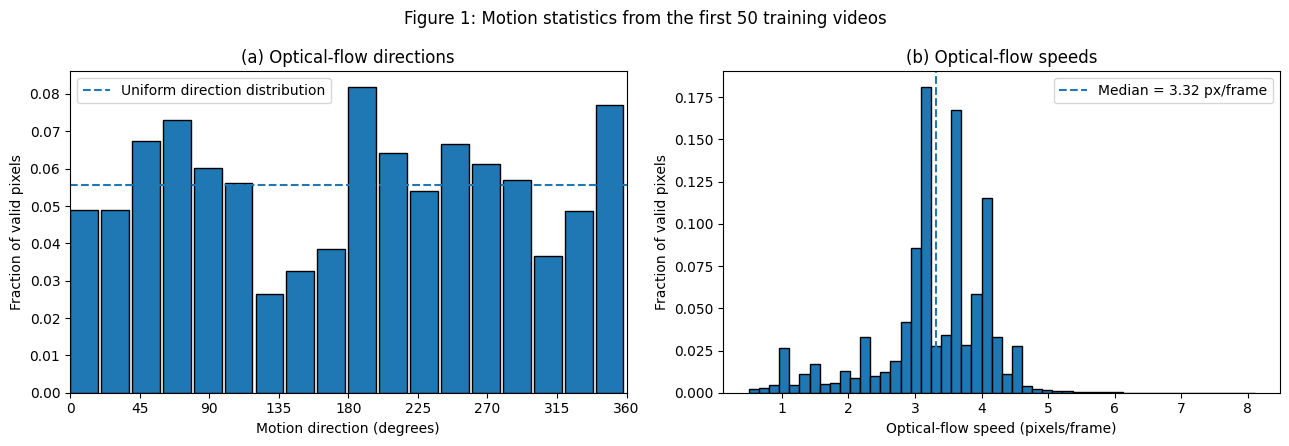

In [13]:

# Figure 1(a): Motion direction distribution
# Figure 1(b): Motion speed distribution

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel (a): 18 bins, each covering 20 degrees
direction_bins = np.arange(0, 361, 20)

direction_counts, _ = np.histogram(
    all_directions,
    bins=direction_bins
)

direction_fractions = direction_counts / len(all_directions)

axes[0].bar(
    direction_bins[:-1],
    direction_fractions,
    width=18,
    align="edge",
    edgecolor="black"
)

axes[0].axhline(
    1 / 18,
    linestyle="--",
    label="Uniform direction distribution"
)

axes[0].set_xlim(0, 360)
axes[0].set_xticks(np.arange(0, 361, 45))
axes[0].set_xlabel("Motion direction (degrees)")
axes[0].set_ylabel("Fraction of valid pixels")
axes[0].set_title("(a) Optical-flow directions")
axes[0].legend()

# Panel (b): Speed distribution
speed_counts, speed_bins = np.histogram(
    all_speeds,
    bins=50
)

speed_fractions = speed_counts / len(all_speeds)

axes[1].bar(
    speed_bins[:-1],
    speed_fractions,
    width=np.diff(speed_bins),
    align="edge",
    edgecolor="black"
)

axes[1].axvline(
    median_speed,
    linestyle="--",
    label=f"Median = {median_speed:.2f} px/frame"
)

axes[1].set_xlabel("Optical-flow speed (pixels/frame)")
axes[1].set_ylabel("Fraction of valid pixels")
axes[1].set_title("(b) Optical-flow speeds")
axes[1].legend()

fig.suptitle(
    "Figure 1: Motion statistics from the first 50 training videos"
)
plt.tight_layout()
plt.show()


In [14]:

# Save Figure 1 in the Question2 folder
from pathlib import Path

figure_path = Path("Figure1_motion_statistics.png")

fig.savefig(figure_path, dpi=300, bbox_inches="tight")

print("Figure saved to:", figure_path.resolve())
print("File exists:", figure_path.exists())
print("File size (KB):", round(figure_path.stat().st_size / 1024, 2))


Figure saved to: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\Figure1_motion_statistics.png
File exists: True
File size (KB): 174.84


In [15]:

print("Training videos:", train_videos.shape)
print("Validation videos:", val_videos.shape)
print("Test videos:", test_videos.shape)

print("\nData type:", train_videos.dtype)
print("Value range:", train_videos.min().item(), "to", train_videos.max().item())
print("Training tensor device:", train_videos.device)

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Training videos: torch.Size([8000, 20, 1, 64, 64])
Validation videos: torch.Size([1000, 20, 1, 64, 64])
Test videos: torch.Size([1000, 20, 1, 64, 64])

Data type: torch.float32
Value range: 0.0 to 1.0
Training tensor device: cpu

GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [16]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size=3):
        super().__init__()

        self.hidden_channels = hidden_channels

        # One convolution computes all four gates.
        self.gates = nn.Conv2d(
            in_channels=input_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=kernel_size // 2,
            bias=True
        )

    def forward(self, x, h_prev, c_prev):
        # Combine current input and previous hidden state.
        combined = torch.cat([x, h_prev], dim=1)

        # Split the convolution output into four gates.
        gates = self.gates(combined)
        i, f, o, g = torch.chunk(gates, chunks=4, dim=1)

        # Update cell state and hidden state.
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c_prev + i * g
        h = o * torch.tanh(c)

        return h, c


print("ConvLSTMCell class defined successfully.")


ConvLSTMCell class defined successfully.


In [17]:

class ModelA(nn.Module):
    def __init__(self):
        super().__init__()

        # Convert 1x64x64 frames into 16x16x16 features.
        self.pixel_unshuffle = nn.PixelUnshuffle(downscale_factor=4)

        # Two ConvLSTM layers, each with 64 hidden channels.
        self.convlstm1 = ConvLSTMCell(
            input_channels=16,
            hidden_channels=64,
            kernel_size=3
        )

        self.convlstm2 = ConvLSTMCell(
            input_channels=64,
            hidden_channels=64,
            kernel_size=3
        )

        # Convert hidden features into 16 channels.
        self.output_conv = nn.Conv2d(
            in_channels=64,
            out_channels=16,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=True
        )

        # Reconstruct the original spatial resolution.
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor=4)

    def forward(self, x):
        # x shape: (batch, time, 1, 64, 64)
        batch_size, num_frames, _, _, _ = x.shape

        # Initialize both layers' hidden and cell states to zero.
        h1 = torch.zeros(
            batch_size, 64, 16, 16,
            device=x.device, dtype=x.dtype
        )
        c1 = torch.zeros_like(h1)

        h2 = torch.zeros_like(h1)
        c2 = torch.zeros_like(h1)

        predictions = []

        # Process frames sequentially.
        for t in range(num_frames):
            features = self.pixel_unshuffle(x[:, t])

            h1, c1 = self.convlstm1(features, h1, c1)
            h2, c2 = self.convlstm2(h1, h2, c2)

            frame = self.output_conv(h2)
            frame = self.pixel_shuffle(frame)
            frame = torch.sigmoid(frame)

            predictions.append(frame)

        return torch.stack(predictions, dim=1)


model_a = ModelA()

parameter_count = sum(
    parameter.numel()
    for parameter in model_a.parameters()
    if parameter.requires_grad
)

print("Model A created successfully.")
print("Trainable parameters:", f"{parameter_count:,}")


Model A created successfully.
Trainable parameters: 480,784


In [18]:

# Test Model A using a small batch of two videos.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_a = model_a.to(device)

dummy_input = torch.rand(2, 5, 1, 64, 64, device=device)

model_a.eval()
with torch.no_grad():
    dummy_output = model_a(dummy_input)

print("Device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)
print("Output minimum:", dummy_output.min().item())
print("Output maximum:", dummy_output.max().item())
print("All outputs finite:", torch.isfinite(dummy_output).all().item())


Device: cuda
Input shape: torch.Size([2, 5, 1, 64, 64])
Output shape: torch.Size([2, 5, 1, 64, 64])
Output minimum: 0.47058433294296265
Output maximum: 0.5290731191635132
All outputs finite: True


In [20]:

# Model A receptive-field calculation

pixels_per_cell = 4

# Longest path:
# ConvLSTM layer 1 input-to-gates convolution
# + ConvLSTM layer 2 input-to-gates convolution
# + ConvLSTM layer 2 hidden-to-gates recurrent convolution
spatial_steps = 3

reach_pixels = spatial_steps * pixels_per_cell

print("Original pixels per folded cell:", pixels_per_cell)
print("Spatial convolution steps on the longest path:", spatial_steps)
print("Model A one-step spatial reach:", reach_pixels, "original pixels")


Original pixels per folded cell: 4
Spatial convolution steps on the longest path: 3
Model A one-step spatial reach: 12 original pixels


In [21]:

def model_a_rollout(model, input_frames):
    """
    input_frames: (B, 5, 1, 64, 64)
    Returns:      (B, 5, 1, 64, 64), predictions for frames 6-10
    """
    batch_size = input_frames.shape[0]

    # Initialize recurrent states to zero for each video.
    h1 = torch.zeros(
        batch_size, 64, 16, 16,
        device=input_frames.device,
        dtype=input_frames.dtype
    )
    c1 = torch.zeros_like(h1)
    h2 = torch.zeros_like(h1)
    c2 = torch.zeros_like(h1)

    predictions = []
    current_frame = None

    # Nine recurrent steps in total.
    for step in range(9):
        if step < 5:
            # First five steps use the observed frames.
            current_frame = input_frames[:, step]
        # Steps 5-8 use the previous prediction as input.
        # current_frame already contains that prediction.

        features = model.pixel_unshuffle(current_frame)

        h1, c1 = model.convlstm1(features, h1, c1)
        h2, c2 = model.convlstm2(h1, h2, c2)

        output = model.output_conv(h2)
        output = model.pixel_shuffle(output)
        output = torch.sigmoid(output)

        # Save predictions from steps 5-9 (zero-based indices 4-8).
        if step >= 4:
            predictions.append(output)

        # The next step will use this prediction as its input.
        current_frame = output

    return torch.stack(predictions, dim=1)


print("Autoregressive rollout function defined successfully.")


Autoregressive rollout function defined successfully.


In [22]:

model_a.eval()

test_input = torch.rand(2, 5, 1, 64, 64, device=device)

with torch.no_grad():
    test_predictions = model_a_rollout(model_a, test_input)

print("Input shape:", test_input.shape)
print("Forecast shape:", test_predictions.shape)
print("All predictions finite:", torch.isfinite(test_predictions).all().item())
print("Prediction range:",
      test_predictions.min().item(),
      "to",
      test_predictions.max().item())


Input shape: torch.Size([2, 5, 1, 64, 64])
Forecast shape: torch.Size([2, 5, 1, 64, 64])
All predictions finite: True
Prediction range: 0.4709239602088928 to 0.5287225842475891


In [23]:

import torch

if torch.cuda.is_available():
    torch.cuda.synchronize()
    free_bytes, total_bytes = torch.cuda.mem_get_info()

    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Total GPU memory: {total_bytes / (1024**3):.2f} GiB")
    print(f"Currently free GPU memory: {free_bytes / (1024**3):.2f} GiB")
else:
    print("CUDA is unavailable.")


GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Total GPU memory: 6.00 GiB
Currently free GPU memory: 4.91 GiB


In [24]:

import random
import torch.nn.functional as F

def sample_training_window(video):
    # Allowed start frames are 1 through 11 for speed 1x.
    start_frame = random.randint(1, 11)

    # make_window uses frame numbers starting at 1.
    X, Y = make_window(video, t=start_frame, speed=1)

    return X, Y


# Test the helper on one training video.
sample_X, sample_Y = sample_training_window(train_videos[0])

print("Input window shape:", sample_X.shape)
print("Target window shape:", sample_Y.shape)
print("Input values:", sample_X.min().item(), "to", sample_X.max().item())
print("Target values:", sample_Y.min().item(), "to", sample_Y.max().item())


Input window shape: torch.Size([5, 1, 64, 64])
Target window shape: torch.Size([5, 1, 64, 64])
Input values: 0.0 to 1.0
Target values: 0.0 to 1.0


In [25]:

def per_video_mse(predictions, targets):
    """
    predictions, targets: (B, T, C, H, W)

    Average squared error over time, channels, height and width
    separately for each video.
    """
    squared_error = (predictions - targets) ** 2
    return squared_error.flatten(start_dim=1).mean(dim=1)


# Use a small example batch.
dummy_predictions = torch.zeros(2, 5, 1, 64, 64)
dummy_targets = torch.ones(2, 5, 1, 64, 64)

individual_losses = per_video_mse(dummy_predictions, dummy_targets)
batch_loss = individual_losses.mean()

print("Individual video losses:", individual_losses.tolist())
print("Mean batch loss:", batch_loss.item())


Individual video losses: [1.0, 1.0]
Mean batch loss: 1.0


In [26]:

import time
import random
import numpy as np
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

def train_model_a(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    # Set all random seeds for this run.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create a fresh model and optimizer for this seed.
    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Each dataset item is one complete video.
    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    # Save outputs separately for each seed.
    output_dir = Path(f"model_a_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

            # Sample one 1x window per video in this batch.
            starts = torch.randint(
                low=1,
                high=12,
                size=(videos_batch.size(0),),
                device="cpu"
            ).tolist()

            inputs = []
            targets = []

            for i, start in enumerate(starts):
                X, Y = make_window(
                    videos_batch[i],
                    t=start,
                    speed=1
                )
                inputs.append(X)
                targets.append(Y)

            X_batch = torch.stack(inputs).to(run_device)
            Y_batch = torch.stack(targets).to(run_device)

            optimizer.zero_grad(set_to_none=True)

            predictions = model_a_rollout(model, X_batch)
            loss = per_video_mse(predictions, Y_batch).mean()

            loss.backward()
            optimizer.step()

            batch_count = videos_batch.size(0)
            total_train_loss += loss.item() * batch_count
            videos_seen += batch_count

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        train_loss = total_train_loss / videos_seen

        # Validate on all validation videos, using 1x windows starting at t=1.
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for start_idx in range(0, len(val_videos), batch_size):
                batch = val_videos[start_idx:start_idx + batch_size]
                batch = batch.to(run_device)

                X_val = batch[:, :5]
                Y_val = batch[:, 5:10]

                predictions = model_a_rollout(model, X_val)
                losses = per_video_mse(predictions, Y_val)

                val_loss_sum += losses.sum().item()
                val_count += batch.size(0)

        val_loss = val_loss_sum / val_count

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time_seconds": epoch_time
        }
        history.append(record)

        # Save the latest checkpoint every epoch.
        torch.save(
            {
                "seed": seed,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history
            },
            output_dir / "latest_checkpoint.pt"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(
                model.state_dict(),
                output_dir / "best_model.pt"
            )

        print(
            f"Seed {seed} | Epoch {epoch:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f} | "
            f"Time: {epoch_time / 60:.2f} min"
        )

    mean_epoch_time = float(np.mean(epoch_times))

    print(f"\nSeed {seed} finished.")
    print(f"Best validation MSE: {best_val_loss:.6f}")
    print(f"Mean epoch time: {mean_epoch_time / 60:.2f} minutes")

    return model, history


In [27]:
print("Training function defined:", callable(train_model_a))
print("Model A class available:", callable(ModelA))
print("Rollout function available:", callable(model_a_rollout))

Training function defined: True
Model A class available: True
Rollout function available: True


In [28]:

# Test one training step without starting the full training run.
import random

random.seed(0)
torch.manual_seed(0)

memory_test_model = ModelA().to(device)
memory_test_optimizer = torch.optim.Adam(
    memory_test_model.parameters(),
    lr=1e-3
)

# Use 32 training videos.
batch_videos = train_videos[:32].to(device)

test_inputs = []
test_targets = []

for video in batch_videos:
    X, Y = make_window(
        video,
        t=random.randint(1, 11),
        speed=1
    )
    test_inputs.append(X)
    test_targets.append(Y)

X_batch = torch.stack(test_inputs)
Y_batch = torch.stack(test_targets)

memory_test_model.train()
memory_test_optimizer.zero_grad(set_to_none=True)

predictions = model_a_rollout(memory_test_model, X_batch)
loss = per_video_mse(predictions, Y_batch).mean()

loss.backward()
memory_test_optimizer.step()

torch.cuda.synchronize()

print("Batch size:", X_batch.shape[0])
print("Prediction shape:", predictions.shape)
print("Training loss:", loss.item())
print("One training step completed successfully.")

free_bytes, total_bytes = torch.cuda.mem_get_info()
print(f"GPU memory currently free: {free_bytes / (1024**3):.2f} GiB")


Batch size: 32
Prediction shape: torch.Size([32, 5, 1, 64, 64])
Training loss: 0.23409722745418549
One training step completed successfully.
GPU memory currently free: 4.54 GiB


In [29]:

import gc
import torch

del memory_test_model
del memory_test_optimizer
del batch_videos
del test_inputs
del test_targets
del X_batch
del Y_batch
del predictions
del loss

gc.collect()
torch.cuda.empty_cache()

free_bytes, total_bytes = torch.cuda.mem_get_info()

print("Temporary test objects cleared.")
print(f"Free GPU memory: {free_bytes / (1024**3):.2f} GiB")


Temporary test objects cleared.
Free GPU memory: 4.91 GiB


In [30]:

model_a_seed0, history_seed0 = train_model_a(
    seed=0,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)


Seed 0 | Epoch 01/30 | Train MSE: 0.046122 | Val MSE: 0.039320 | Time: 0.21 min
Seed 0 | Epoch 02/30 | Train MSE: 0.039678 | Val MSE: 0.038541 | Time: 0.21 min
Seed 0 | Epoch 03/30 | Train MSE: 0.038694 | Val MSE: 0.037351 | Time: 0.21 min
Seed 0 | Epoch 04/30 | Train MSE: 0.037207 | Val MSE: 0.036157 | Time: 0.21 min
Seed 0 | Epoch 05/30 | Train MSE: 0.035298 | Val MSE: 0.033933 | Time: 0.20 min
Seed 0 | Epoch 06/30 | Train MSE: 0.033599 | Val MSE: 0.032223 | Time: 0.20 min
Seed 0 | Epoch 07/30 | Train MSE: 0.032310 | Val MSE: 0.031146 | Time: 0.20 min
Seed 0 | Epoch 08/30 | Train MSE: 0.031213 | Val MSE: 0.030303 | Time: 0.20 min
Seed 0 | Epoch 09/30 | Train MSE: 0.030334 | Val MSE: 0.029643 | Time: 0.21 min
Seed 0 | Epoch 10/30 | Train MSE: 0.029597 | Val MSE: 0.029382 | Time: 0.20 min
Seed 0 | Epoch 11/30 | Train MSE: 0.029225 | Val MSE: 0.028579 | Time: 0.20 min
Seed 0 | Epoch 12/30 | Train MSE: 0.028783 | Val MSE: 0.028251 | Time: 0.20 min
Seed 0 | Epoch 13/30 | Train MSE: 0.0283

In [31]:

print("Seed 0 epochs recorded:", len(history_seed0))
print("\nFirst 3 epochs:")
for row in history_seed0[:3]:
    print(row)

print("\nLast 3 epochs:")
for row in history_seed0[-3:]:
    print(row)

best_epoch = min(history_seed0, key=lambda row: row["val_loss"])

print("\nBest validation epoch:", best_epoch["epoch"])
print("Best validation MSE:", best_epoch["val_loss"])


Seed 0 epochs recorded: 30

First 3 epochs:
{'epoch': 1, 'train_loss': 0.04612157432734966, 'val_loss': 0.039320432215929034, 'epoch_time_seconds': 12.70554780960083}
{'epoch': 2, 'train_loss': 0.03967842645943165, 'val_loss': 0.03854070746898651, 'epoch_time_seconds': 12.319251298904419}
{'epoch': 3, 'train_loss': 0.03869366000592708, 'val_loss': 0.0373513910472393, 'epoch_time_seconds': 12.40588665008545}

Last 3 epochs:
{'epoch': 28, 'train_loss': 0.022960879489779474, 'val_loss': 0.022888243943452836, 'epoch_time_seconds': 12.781866550445557}
{'epoch': 29, 'train_loss': 0.022723910458385944, 'val_loss': 0.022645651906728743, 'epoch_time_seconds': 12.777043342590332}
{'epoch': 30, 'train_loss': 0.02246801882982254, 'val_loss': 0.022332063540816308, 'epoch_time_seconds': 12.708121061325073}

Best validation epoch: 30
Best validation MSE: 0.022332063540816308


In [32]:

model_a_seed1, history_seed1 = train_model_a(
    seed=1,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)


Seed 1 | Epoch 01/30 | Train MSE: 0.047879 | Val MSE: 0.039477 | Time: 0.21 min
Seed 1 | Epoch 02/30 | Train MSE: 0.040197 | Val MSE: 0.039472 | Time: 0.20 min
Seed 1 | Epoch 03/30 | Train MSE: 0.040199 | Val MSE: 0.039472 | Time: 0.20 min
Seed 1 | Epoch 04/30 | Train MSE: 0.040192 | Val MSE: 0.039472 | Time: 0.20 min
Seed 1 | Epoch 05/30 | Train MSE: 0.040199 | Val MSE: 0.039448 | Time: 0.20 min
Seed 1 | Epoch 06/30 | Train MSE: 0.039691 | Val MSE: 0.038332 | Time: 0.20 min
Seed 1 | Epoch 07/30 | Train MSE: 0.037882 | Val MSE: 0.035927 | Time: 0.20 min
Seed 1 | Epoch 08/30 | Train MSE: 0.035513 | Val MSE: 0.033900 | Time: 0.20 min
Seed 1 | Epoch 09/30 | Train MSE: 0.033396 | Val MSE: 0.031673 | Time: 0.20 min
Seed 1 | Epoch 10/30 | Train MSE: 0.031406 | Val MSE: 0.030312 | Time: 0.20 min
Seed 1 | Epoch 11/30 | Train MSE: 0.029913 | Val MSE: 0.029601 | Time: 0.20 min
Seed 1 | Epoch 12/30 | Train MSE: 0.029019 | Val MSE: 0.028422 | Time: 0.20 min
Seed 1 | Epoch 13/30 | Train MSE: 0.0283

In [33]:

from pathlib import Path
import torch

for seed in (0, 1):
    checkpoint_path = Path(f"model_a_seed_{seed}/best_model.pt")

    print(f"Seed {seed}")
    print("Checkpoint exists:", checkpoint_path.exists())

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )
        print("Checkpoint keys:", list(checkpoint.keys()))
        print()


Seed 0
Checkpoint exists: True
Checkpoint keys: ['convlstm1.gates.weight', 'convlstm1.gates.bias', 'convlstm2.gates.weight', 'convlstm2.gates.bias', 'output_conv.weight', 'output_conv.bias']

Seed 1
Checkpoint exists: True
Checkpoint keys: ['convlstm1.gates.weight', 'convlstm1.gates.bias', 'convlstm2.gates.weight', 'convlstm2.gates.bias', 'output_conv.weight', 'output_conv.bias']



In [34]:

best_models_a = {}

for seed in (0, 1):
    model = ModelA().to(device)

    checkpoint_path = Path(f"model_a_seed_{seed}/best_model.pt")
    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state_dict)
    model.eval()

    best_models_a[seed] = model

    print(f"Seed {seed}: best model loaded successfully")

print("\nParameter count:", sum(
    parameter.numel()
    for parameter in best_models_a[0].parameters()
))


Seed 0: best model loaded successfully
Seed 1: best model loaded successfully

Parameter count: 480784


In [35]:

# Select all 1,000 test videos.
test_inputs = test_videos[:, :5]   # Frames 1–5
test_targets = test_videos[:, 5:10]  # Frames 6–10

print("Test inputs:", test_inputs.shape)
print("Test targets:", test_targets.shape)

# Baseline 1: predict completely blank frames.
blank_predictions = torch.zeros_like(test_targets)

# Baseline 2: repeat the last observed input frame.
copy_last_predictions = test_inputs[:, 4:5].repeat(1, 5, 1, 1, 1)

print("Blank predictions:", blank_predictions.shape)
print("Copy-last predictions:", copy_last_predictions.shape)


Test inputs: torch.Size([1000, 5, 1, 64, 64])
Test targets: torch.Size([1000, 5, 1, 64, 64])
Blank predictions: torch.Size([1000, 5, 1, 64, 64])
Copy-last predictions: torch.Size([1000, 5, 1, 64, 64])


In [36]:

def calculate_horizon_mse(predictions, targets):
    # Average squared pixel error separately for each forecast horizon.
    squared_error = (predictions - targets) ** 2
    return squared_error.mean(dim=(0, 2, 3, 4))

baseline_predictions = {
    "Blank": blank_predictions,
    "Copy-last": copy_last_predictions,
}

baseline_results = {}

for name, predictions in baseline_predictions.items():
    horizon_mse = calculate_horizon_mse(predictions, test_targets)
    e5 = horizon_mse.mean().item()

    baseline_results[name] = {
        "horizon_mse": horizon_mse.cpu().tolist(),
        "E5": e5,
    }

    print(f"\n{name}")
    for horizon, mse in enumerate(horizon_mse.tolist(), start=1):
        print(f"  Horizon {horizon}: MSE = {mse:.6f}")
    print(f"  E5 = {e5:.6f}")



Blank
  Horizon 1: MSE = 0.042610
  Horizon 2: MSE = 0.042570
  Horizon 3: MSE = 0.042576
  Horizon 4: MSE = 0.042532
  Horizon 5: MSE = 0.042530
  E5 = 0.042564

Copy-last
  Horizon 1: MSE = 0.049164
  Horizon 2: MSE = 0.060420
  Horizon 3: MSE = 0.066889
  Horizon 4: MSE = 0.070779
  Horizon 5: MSE = 0.073160
  E5 = 0.064082


In [37]:

from torch.utils.data import DataLoader, TensorDataset
import time

def evaluate_model_a(model, inputs, targets, batch_size=32):
    loader = DataLoader(
        TensorDataset(inputs, targets),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    all_predictions = []
    all_targets = []

    model.eval()
    start_time = time.perf_counter()

    with torch.no_grad():
        for batch_inputs, batch_targets in loader:
            batch_inputs = batch_inputs.to(device)
            batch_targets = batch_targets.to(device)

            predictions = model_a_rollout(model, batch_inputs)

            all_predictions.append(predictions.cpu())
            all_targets.append(batch_targets.cpu())

    elapsed_seconds = time.perf_counter() - start_time

    predictions = torch.cat(all_predictions, dim=0)
    targets = torch.cat(all_targets, dim=0)

    horizon_mse = calculate_horizon_mse(predictions, targets)
    e5 = horizon_mse.mean().item()

    return predictions, horizon_mse, e5, elapsed_seconds


model_a_results = {}

for seed, model in best_models_a.items():
    predictions, horizon_mse, e5, elapsed = evaluate_model_a(
        model, test_inputs, test_targets, batch_size=32
    )

    model_a_results[seed] = {
        "predictions": predictions,
        "horizon_mse": horizon_mse.tolist(),
        "E5": e5,
        "inference_seconds": elapsed,
    }

    print(f"\nModel A — Seed {seed}")
    for horizon, mse in enumerate(horizon_mse.tolist(), start=1):
        print(f"  Horizon {horizon}: MSE = {mse:.6f}")
    print(f"  E5 = {e5:.6f}")
    print(f"  Test inference time = {elapsed:.2f} seconds")



Model A — Seed 0
  Horizon 1: MSE = 0.017263
  Horizon 2: MSE = 0.020783
  Horizon 3: MSE = 0.023047
  Horizon 4: MSE = 0.024781
  Horizon 5: MSE = 0.026413
  E5 = 0.022457
  Test inference time = 2.49 seconds

Model A — Seed 1
  Horizon 1: MSE = 0.016606
  Horizon 2: MSE = 0.020145
  Horizon 3: MSE = 0.022475
  Horizon 4: MSE = 0.024269
  Horizon 5: MSE = 0.026030
  E5 = 0.021905
  Test inference time = 2.60 seconds


In [39]:

mean_horizon_mse = [
    sum(model_a_results[seed]["horizon_mse"][h] for seed in (0, 1)) / 2
    for h in range(5)
]

mean_e5 = sum(model_a_results[seed]["E5"] for seed in (0, 1)) / 2
parameter_count = sum(
    parameter.numel() for parameter in best_models_a[0].parameters()
)

print(f"{'Model':<15} {'Parameters':>12} {'MSE1':>10} {'MSE2':>10} {'MSE3':>10} {'MSE4':>10} {'MSE5':>10} {'E5':>10}")
print("-" * 100)

for name in ("Blank", "Copy-last"):
    result = baseline_results[name]
    values = result["horizon_mse"]
    print(
        f"{name:<15} {0:>12,} "
        + " ".join(f"{value:>10.6f}" for value in values)
        + f" {result['E5']:>10.6f}"
    )

print(
    f"{'Model A (mean)':<15} {parameter_count:>12,} "
    + " ".join(f"{value:>10.6f}" for value in mean_horizon_mse)
    + f" {mean_e5:>10.6f}"
)


Model             Parameters       MSE1       MSE2       MSE3       MSE4       MSE5         E5
----------------------------------------------------------------------------------------------------
Blank                      0   0.042610   0.042570   0.042576   0.042532   0.042530   0.042564
Copy-last                  0   0.049164   0.060420   0.066889   0.070779   0.073160   0.064082
Model A (mean)       480,784   0.016935   0.020464   0.022761   0.024525   0.026221   0.022181


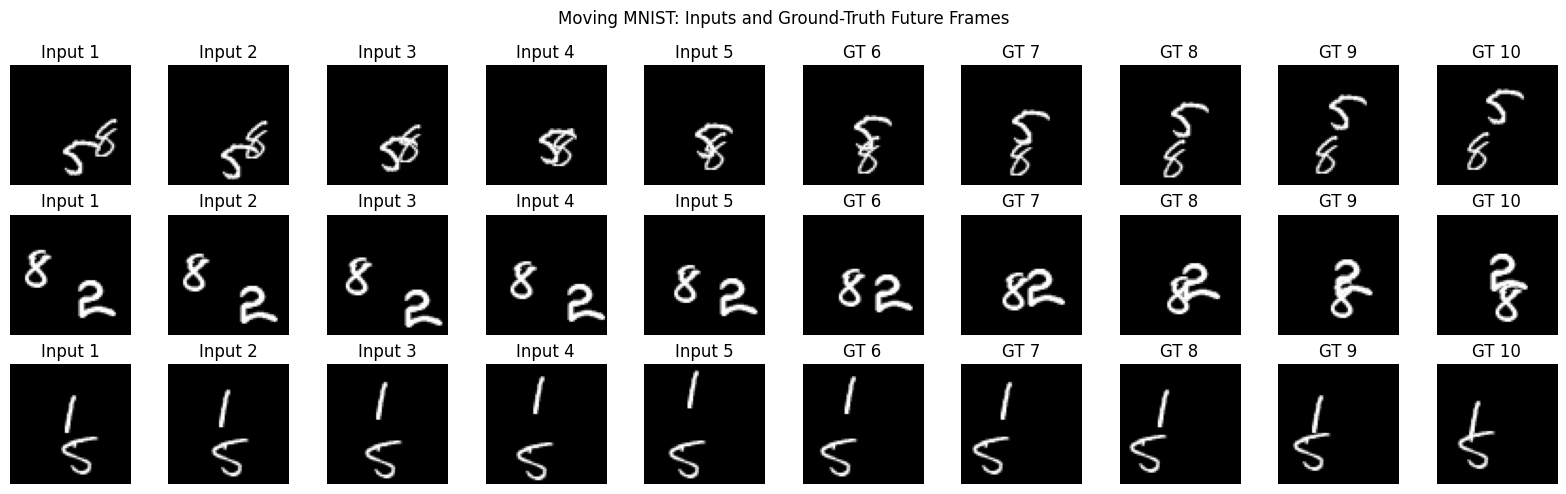

In [40]:

import matplotlib.pyplot as plt

# Use test video indices 0, 1, and 2.
example_indices = [0, 1, 2]

fig, axes = plt.subplots(3, 10, figsize=(16, 5))

for row, idx in enumerate(example_indices):
    # First five columns: observed input frames.
    for t in range(5):
        axes[row, t].imshow(test_inputs[idx, t, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        axes[row, t].set_title(f"Input {t+1}")
        axes[row, t].axis("off")

    # Last five columns: ground-truth future frames.
    for t in range(5):
        axes[row, t+5].imshow(test_targets[idx, t, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        axes[row, t+5].set_title(f"GT {t+6}")
        axes[row, t+5].axis("off")

    axes[row, 0].set_ylabel(f"Test video {idx}", rotation=90, size=9)

plt.suptitle("Moving MNIST: Inputs and Ground-Truth Future Frames")
plt.tight_layout()
plt.show()


In [41]:

# Use Model A, Seed 0, for the required visual examples.
example_indices = [0, 1, 2]
model_a_seed0_best = best_models_a[0]

example_predictions = {}

model_a_seed0_best.eval()

with torch.no_grad():
    for idx in example_indices:
        inputs = test_inputs[idx:idx+1].to(device)
        prediction = model_a_rollout(model_a_seed0_best, inputs)
        example_predictions[idx] = prediction[0].cpu()

print("Generated predictions for test videos:", example_indices)

for idx in example_indices:
    print(
        f"Video {idx}: prediction shape = "
        f"{tuple(example_predictions[idx].shape)}"
    )


Generated predictions for test videos: [0, 1, 2]
Video 0: prediction shape = (5, 1, 64, 64)
Video 1: prediction shape = (5, 1, 64, 64)
Video 2: prediction shape = (5, 1, 64, 64)


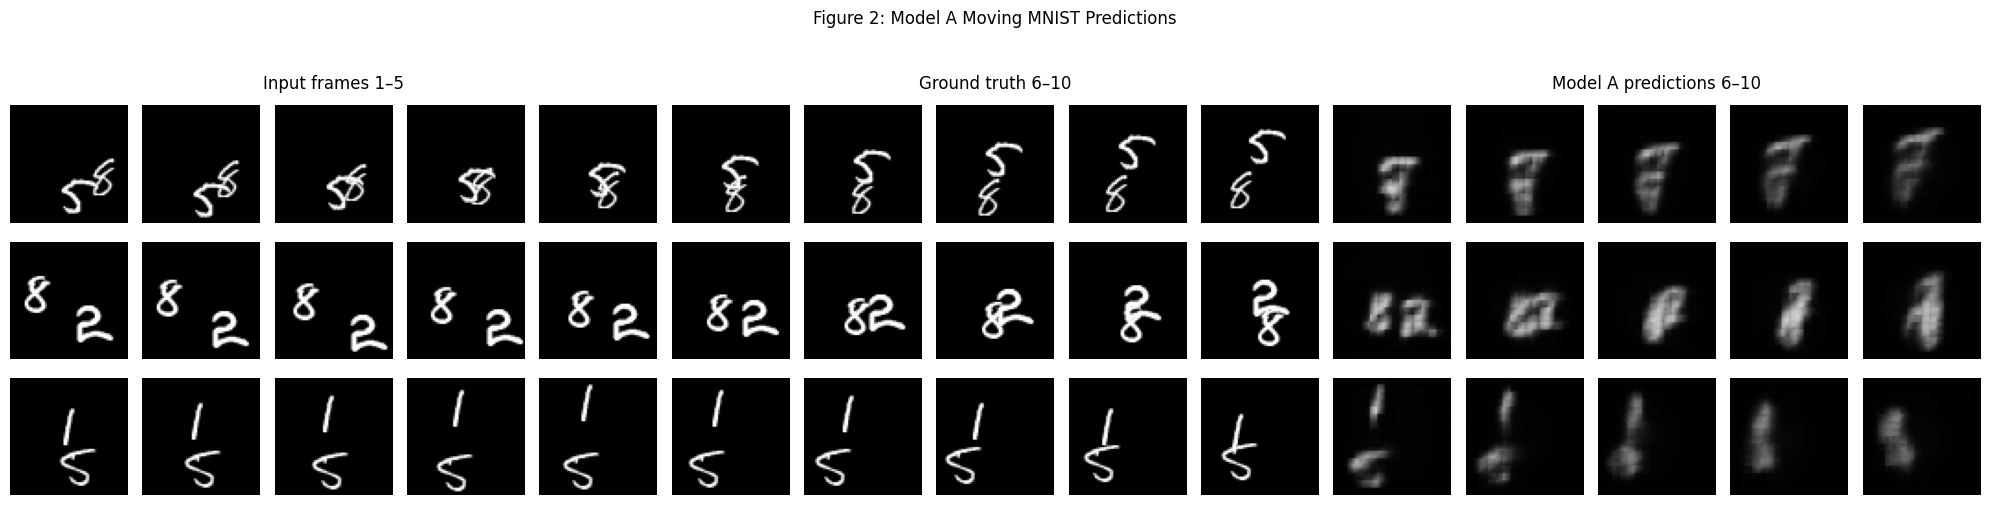

Figure saved to: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure2_model_A_predictions.png
File exists: True


In [42]:
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(3, 15, figsize=(20, 5))

for row, idx in enumerate(example_indices):
    # First five columns: inputs.
    for t in range(5):
        axes[row, t].imshow(
            test_inputs[idx, t, 0].numpy(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, t].axis("off")

    # Next five columns: ground truth.
    for t in range(5):
        axes[row, t+5].imshow(
            test_targets[idx, t, 0].numpy(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, t+5].axis("off")

    # Last five columns: predictions.
    for t in range(5):
        axes[row, t+10].imshow(
            example_predictions[idx][t, 0].numpy(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, t+10].axis("off")

# Group labels.
axes[0, 2].set_title("Input frames 1–5", pad=12)
axes[0, 7].set_title("Ground truth 6–10", pad=12)
axes[0, 12].set_title("Model A predictions 6–10", pad=12)

for row, idx in enumerate(example_indices):
    axes[row, 0].set_ylabel(f"Test video {idx}", labelpad=8)

fig.suptitle("Figure 2: Model A Moving MNIST Predictions", y=1.03)
plt.tight_layout()

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)
figure2_path = output_dir / "Figure2_model_A_predictions.png"

fig.savefig(figure2_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure2_path.resolve())
print("File exists:", figure2_path.exists())


In [43]:

# Check whether the final-epoch models are still available

print("Seed 0 model available:", "model_a_seed0" in globals())
print("Seed 1 model available:", "model_a_seed1" in globals())

if "model_a_seed0" in globals():
    print("Seed 0 model type:", type(model_a_seed0).__name__)

if "model_a_seed1" in globals():
    print("Seed 1 model type:", type(model_a_seed1).__name__)


Seed 0 model available: True
Seed 1 model available: True
Seed 0 model type: ModelA
Seed 1 model type: ModelA


In [46]:

from pathlib import Path
import torch

for seed in (0, 1):
    path = Path(f"model_a_seed_{seed}/latest_checkpoint.pt")

    print(f"\n{'=' * 20} Seed {seed} {'=' * 20}")
    print("File exists:", path.exists())

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if key == "history" and isinstance(value, list):
                print("History entries:", len(value))
                if value:
                    print("Last history entry:", value[-1])
            elif key in ("epoch", "epochs", "model_state_dict", "optimizer_state_dict"):
                if key.endswith("_state_dict") and isinstance(value, dict):
                    print(f"{key} keys:", list(value.keys())[:5])
                else:
                    print(f"{key}:", value)



==================== Seed 0 ====================
File exists: True
Checkpoint type: dict
Checkpoint keys: ['seed', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history']
epoch: 30
model_state_dict keys: ['convlstm1.gates.weight', 'convlstm1.gates.bias', 'convlstm2.gates.weight', 'convlstm2.gates.bias', 'output_conv.weight']
optimizer_state_dict keys: ['state', 'param_groups']
History entries: 30
Last history entry: {'epoch': 30, 'train_loss': 0.02246801882982254, 'val_loss': 0.022332063540816308, 'epoch_time_seconds': 12.708121061325073}

==================== Seed 1 ====================
File exists: True
Checkpoint type: dict
Checkpoint keys: ['seed', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history']
epoch: 30
model_state_dict keys: ['convlstm1.gates.weight', 'convlstm1.gates.bias', 'convlstm2.gates.weight', 'convlstm2.gates.bias', 'output_conv.weight']
optimizer_state_dict keys: ['state', 'param_groups']
History entries: 30
Last history entry: {'epoch': 30, 'tr

In [47]:

# Load the final-epoch weights from both verified checkpoints

final_models_a = {}

for seed in (0, 1):
    checkpoint_path = f"model_a_seed_{seed}/latest_checkpoint.pt"

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    assert checkpoint["epoch"] == 30, (
        f"Seed {seed} checkpoint is not from epoch 30"
    )

    model = ModelA().to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    final_models_a[seed] = model

    print(
        f"Seed {seed}: loaded epoch {checkpoint['epoch']}, "
        f"parameters = {sum(p.numel() for p in model.parameters()):,}"
    )

print("\nBoth final-epoch models are ready for evaluation.")


Seed 0: loaded epoch 30, parameters = 480,784
Seed 1: loaded epoch 30, parameters = 480,784

Both final-epoch models are ready for evaluation.


In [48]:

# Evaluate both final-epoch models on the original test set

model_a_final_results = {}

for seed in (0, 1):
    print(f"Evaluating final-epoch Model A, Seed {seed}...")

    predictions, horizon_mse, e5, elapsed = evaluate_model_a(
        final_models_a[seed],
        test_inputs,
        test_targets,
        batch_size=32
    )

    model_a_final_results[seed] = {
        "predictions": predictions,
        "horizon_mse": horizon_mse,
        "e5": e5,
        "inference_seconds": elapsed,
    }

    print("Horizon MSE:", horizon_mse.tolist())
    print(f"E5: {e5:.6f}")
    print(f"Inference time: {elapsed:.2f} seconds")

print("\nFinal-epoch evaluation complete.")


Evaluating final-epoch Model A, Seed 0...
Horizon MSE: [0.01726309023797512, 0.020783070474863052, 0.023046504706144333, 0.024780651554465294, 0.026412872597575188]
E5: 0.022457
Inference time: 1.90 seconds
Evaluating final-epoch Model A, Seed 1...
Horizon MSE: [0.016606345772743225, 0.020144600421190262, 0.022475479170680046, 0.024268852546811104, 0.02602950856089592]
E5: 0.021905
Inference time: 0.55 seconds

Final-epoch evaluation complete.


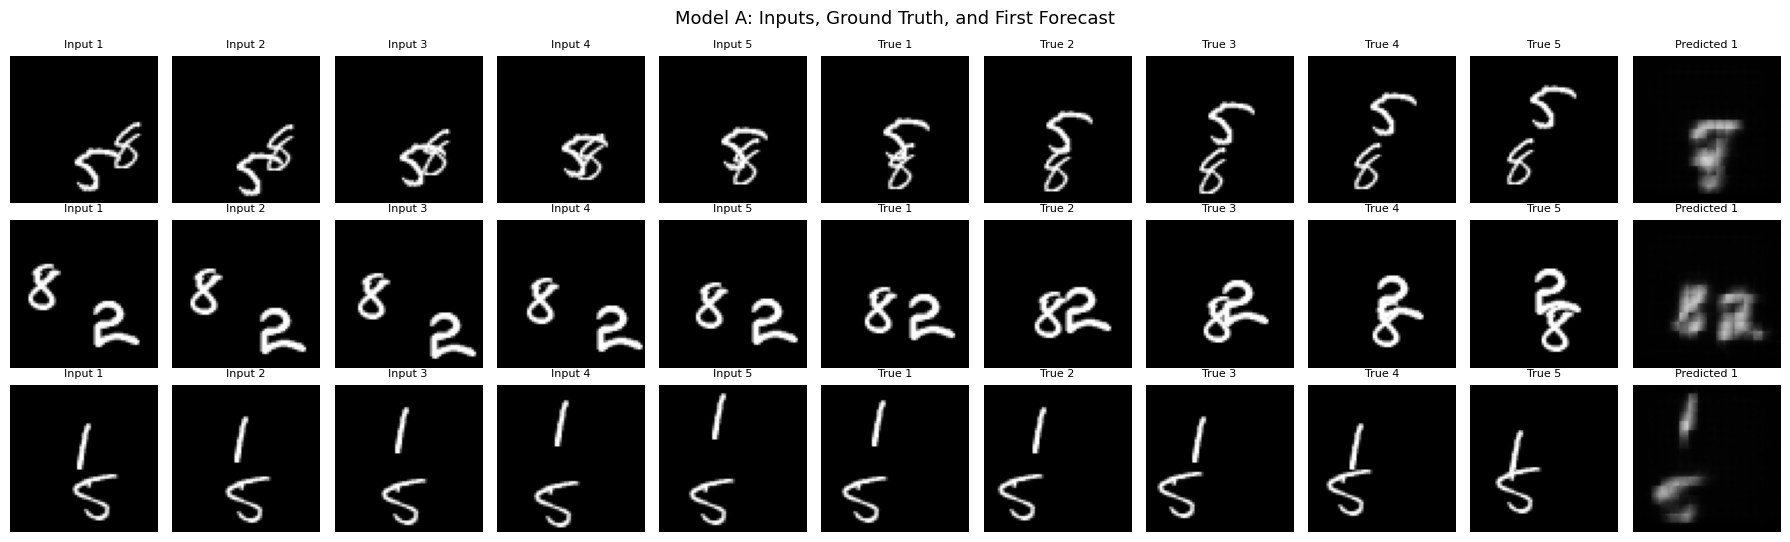

Saved Figure 2 to: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure2_model_A_predictions.png


In [49]:

import matplotlib.pyplot as plt
from pathlib import Path

# Use predictions from the verified final-epoch Seed 0 model
example_indices = [0, 1, 2]
example_predictions = model_a_final_results[0]["predictions"]

fig, axes = plt.subplots(
    len(example_indices),
    11,
    figsize=(18, 5.5)
)

for row, idx in enumerate(example_indices):
    # Five observed input frames
    for j in range(5):
        axes[row, j].imshow(
            test_inputs[idx, j, 0].cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, j].set_title(f"Input {j + 1}", fontsize=8)
        axes[row, j].axis("off")

    # Five ground-truth forecast frames
    for j in range(5):
        axes[row, 5 + j].imshow(
            test_targets[idx, j, 0].cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, 5 + j].set_title(f"True {j + 1}", fontsize=8)
        axes[row, 5 + j].axis("off")

    # First predicted frame, shown separately
    axes[row, 10].imshow(
        example_predictions[idx, 0, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[row, 10].set_title("Predicted 1", fontsize=8)
    axes[row, 10].axis("off")

fig.suptitle(
    "Model A: Inputs, Ground Truth, and First Forecast",
    fontsize=13
)
plt.tight_layout()

output_path = Path("figures/Figure2_model_A_predictions.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved Figure 2 to:", output_path.resolve())


In [50]:

# Q2.6-Q2.8: Model A mirror and rotation stress tests
# Uses both final-epoch models and all 1,000 test videos.

def predict_transformed_inputs(model, inputs, batch_size=32):
    """Predict future frames for transformed inputs in manageable batches."""
    model.eval()
    outputs = []

    with torch.no_grad():
        for start in range(0, len(inputs), batch_size):
            batch = inputs[start:start + batch_size].to(device)
            prediction = model_a_rollout(model, batch)
            outputs.append(prediction.cpu())

    return torch.cat(outputs, dim=0)


table3_seed_results = {}

# Ground-truth frames transformed in the same way as the inputs
transforms = {
    "Mirror": {"a": 0, "mirrored": True},
    "Rotation": {"a": 1, "mirrored": False},
}

for seed in (0, 1):
    model = final_models_a[seed]
    original_predictions = model_a_final_results[seed]["predictions"]

    seed_metrics = {
        "E5": model_a_final_results[seed]["e5"]
    }

    for transform_name, transform_args in transforms.items():
        print(f"Seed {seed}: evaluating {transform_name.lower()}...")

        transformed_inputs = apply_symmetry(
            test_inputs,
            **transform_args
        )

        transformed_targets = apply_symmetry(
            test_targets,
            **transform_args
        )

        transformed_original_predictions = apply_symmetry(
            original_predictions,
            **transform_args
        )

        predictions_after_transform = predict_transformed_inputs(
            model,
            transformed_inputs,
            batch_size=32
        )

        # Transformed prediction error:
        # MSE(f(T(X)), T(Y))
        transformed_error = (
            (predictions_after_transform - transformed_targets) ** 2
        ).mean().item()

        # Consistency gap:
        # MSE(f(T(X)), T(f(X)))
        consistency_gap = (
            (
                predictions_after_transform
                - transformed_original_predictions
            ) ** 2
        ).mean().item()

        if transform_name == "Mirror":
            seed_metrics["EM"] = transformed_error
            seed_metrics["CM"] = consistency_gap
        else:
            seed_metrics["ER"] = transformed_error
            seed_metrics["CR"] = consistency_gap

    table3_seed_results[seed] = seed_metrics
    print(f"Seed {seed} metrics:", seed_metrics)

# Table 3 reports the mean across the two seeds
metric_names = ["E5", "CM", "EM", "CR", "ER"]

print("\nTABLE 3 — MODEL A MIRROR AND ROTATION RESULTS")
print(f"{'Metric':<12}{'Seed 0':>14}{'Seed 1':>14}{'Mean':>14}")

for metric in metric_names:
    value0 = table3_seed_results[0][metric]
    value1 = table3_seed_results[1][metric]
    mean_value = (value0 + value1) / 2

    print(
        f"{metric:<12}"
        f"{value0:>14.6f}"
        f"{value1:>14.6f}"
        f"{mean_value:>14.6f}"
    )


Seed 0: evaluating mirror...
Seed 0: evaluating rotation...
Seed 0 metrics: {'E5': 0.022457238286733627, 'EM': 0.02314576506614685, 'CM': 0.0018154628342017531, 'ER': 0.02419046312570572, 'CR': 0.0030672696884721518}
Seed 1: evaluating mirror...
Seed 1: evaluating rotation...
Seed 1 metrics: {'E5': 0.02190495654940605, 'EM': 0.02257055602967739, 'CM': 0.0017605532193556428, 'ER': 0.023563988506793976, 'CR': 0.002928656293079257}

TABLE 3 — MODEL A MIRROR AND ROTATION RESULTS
Metric              Seed 0        Seed 1          Mean
E5                0.022457      0.021905      0.022181
CM                0.001815      0.001761      0.001788
EM                0.023146      0.022571      0.022858
CR                0.003067      0.002929      0.002998
ER                0.024190      0.023564      0.023877


In [51]:

# Q2.7-Q2.8: Find the two test videos with the largest
# mirror and rotation consistency gaps for Seed 0.

seed = 0
model = final_models_a[seed]
original_predictions = model_a_final_results[seed]["predictions"]

per_video_consistency = {}

for transform_name, transform_args in transforms.items():
    print(f"Calculating per-video {transform_name.lower()} gaps...")

    transformed_inputs = apply_symmetry(
        test_inputs,
        **transform_args
    )

    transformed_original_predictions = apply_symmetry(
        original_predictions,
        **transform_args
    )

    predictions_after_transform = predict_transformed_inputs(
        model,
        transformed_inputs,
        batch_size=32
    )

    # Average squared difference separately for each video
    gaps = (
        predictions_after_transform - transformed_original_predictions
    ).square().flatten(start_dim=1).mean(dim=1)

    per_video_consistency[transform_name] = gaps

    top_values, top_indices = torch.topk(gaps, k=2)

    print(f"\nLargest {transform_name.lower()} consistency gaps:")
    for rank in range(2):
        print(
            f"Rank {rank + 1}: "
            f"test video index {top_indices[rank].item()}, "
            f"gap = {top_values[rank].item():.6f}"
        )

print("\nIndexing note: test video index 0 is the first video in test_videos[9000:10000].")


Calculating per-video mirror gaps...

Largest mirror consistency gaps:
Rank 1: test video index 269, gap = 0.007445
Rank 2: test video index 691, gap = 0.005994
Calculating per-video rotation gaps...

Largest rotation consistency gaps:
Rank 1: test video index 982, gap = 0.007865
Rank 2: test video index 269, gap = 0.006936

Indexing note: test video index 0 is the first video in test_videos[9000:10000].


In [52]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Figure 3: the four required video/transformation cases.
# Test-set indices are zero-based.
figure3_cases = [
    {"transform": "Mirror", "index": 269, "gap": 0.007445},
    {"transform": "Mirror", "index": 691, "gap": 0.005994},
    {"transform": "Rotation", "index": 982, "gap": 0.007865},
    {"transform": "Rotation", "index": 269, "gap": 0.006936},
]

model = final_models_a[0]
model.eval()

figure3_dir = Path("figures/Figure3")
figure3_dir.mkdir(parents=True, exist_ok=True)

def frame_to_numpy(frame):
    """Convert a single 1x64x64 frame to a displayable 64x64 array."""
    return frame.detach().cpu().squeeze().numpy()

def render_figure3_case(case, save_png=True, save_gif=True):
    transform_name = case["transform"]
    idx = case["index"]

    transform_args = transforms[transform_name]
    X = test_inputs[idx:idx + 1]
    Y = test_targets[idx:idx + 1]

    # Apply the same transformation to every input and target frame.
    TX = apply_symmetry(X, **transform_args)
    TY = apply_symmetry(Y, **transform_args)

    # f(X), f(T(X)), and T(f(X)).
    with torch.no_grad():
        pred_X = model_a_rollout(model, X.to(device)).cpu()
        pred_TX = model_a_rollout(model, TX.to(device)).cpu()

    T_pred_X = apply_symmetry(pred_X, **transform_args)

    # Four rows: each row has 5 input/history frames + 5 future frames.
    row_inputs = [X, TX, TX, TX]
    row_futures = [pred_X, TY, pred_TX, T_pred_X]
    row_labels = [
        "X / f(X)",
        "T(X) / T(Y)",
        "T(X) / f(T(X))",
        "T(X) / T(f(X))",
    ]

    def make_frame(horizon=None):
        fig, axes = plt.subplots(4, 10, figsize=(15, 6.4))

        for row in range(4):
            for col in range(5):
                axes[row, col].imshow(
                    frame_to_numpy(row_inputs[row][0, col]),
                    cmap="gray", vmin=0, vmax=1
                )
                axes[row, col].axis("off")

            for col in range(5):
                # PNG shows all five forecast horizons.
                # GIF advances through one horizon at a time.
                if horizon is None:
                    future_frame = row_futures[row][0, col]
                    title = f"H{col + 1}"
                else:
                    future_frame = row_futures[row][0, horizon]
                    title = f"H{horizon + 1}"

                axes[row, col + 5].imshow(
                    frame_to_numpy(future_frame),
                    cmap="gray", vmin=0, vmax=1
                )
                axes[row, col + 5].axis("off")
                axes[row, col + 5].set_title(title, fontsize=8)

            axes[row, 0].set_ylabel(
                row_labels[row], fontsize=9, rotation=0,
                labelpad=50, va="center"
            )

        fig.suptitle(
            f"Figure 3 — {transform_name}, test index {idx}, "
            f"consistency gap {case['gap']:.6f}",
            fontsize=12
        )
        fig.tight_layout(rect=[0.06, 0, 1, 0.95])

        # Convert figure to a PIL image for saving the GIF.
        fig.canvas.draw()
        image_array = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
        pil_image = Image.fromarray(image_array)
        plt.close(fig)
        return pil_image

    safe_name = f"{transform_name.lower()}_test_{idx}"

    if save_png:
        png_image = make_frame(horizon=None)
        png_path = figure3_dir / f"{safe_name}.png"
        png_image.save(png_path)
        print("Saved PNG:", png_path.resolve())

    if save_gif:
        gif_frames = [make_frame(horizon=h) for h in range(5)]
        gif_path = figure3_dir / f"{safe_name}.gif"
        gif_frames[0].save(
            gif_path,
            save_all=True,
            append_images=gif_frames[1:],
            duration=700,
            loop=0
        )
        print("Saved GIF:", gif_path.resolve())

for case in figure3_cases:
    render_figure3_case(case)

print("\nFigure 3 panels and GIFs generated.")


Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\mirror_test_269.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\mirror_test_269.gif
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\mirror_test_691.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\mirror_test_691.gif
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\rotation_test_982.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\rotation_test_982.gif
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\rotation_test_269.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure3\rotation_test_269.gif

Figure 3 panels and GIFs generated.


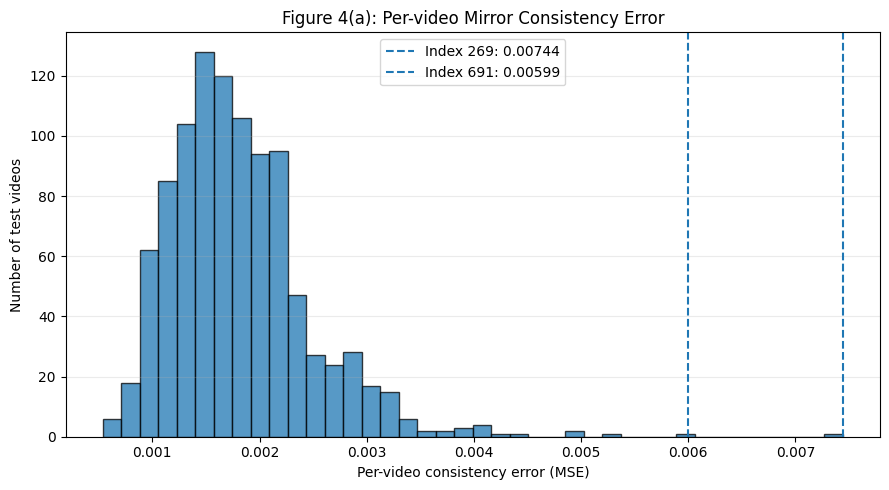

Saved: figures\Figure4\Figure4a_mirror_histogram.png


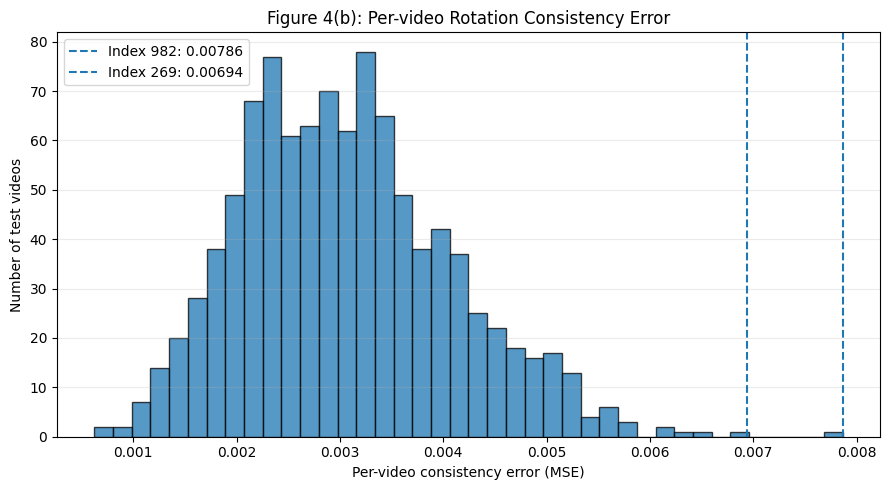

Saved: figures\Figure4\Figure4b_rotation_histogram.png


In [53]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

figure4_dir = Path("figures") / "Figure4"
figure4_dir.mkdir(parents=True, exist_ok=True)

# These are zero-based indices within the 1,000-video test set.
mirror_marked = {
    269: "Index 269",
    691: "Index 691",
}
rotation_marked = {
    982: "Index 982",
    269: "Index 269",
}

# Reuse the previously calculated seed-0 consistency errors.
mirror_errors = np.asarray(per_video_consistency["Mirror"])
rotation_errors = np.asarray(per_video_consistency["Rotation"])

assert len(mirror_errors) == 1000, (
    f"Expected 1000 mirror errors, got {len(mirror_errors)}"
)
assert len(rotation_errors) == 1000, (
    f"Expected 1000 rotation errors, got {len(rotation_errors)}"
)

def plot_consistency_histogram(errors, marked_videos, title, output_path):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(errors, bins=40, edgecolor="black", alpha=0.75)
    ax.set_xlabel("Per-video consistency error (MSE)")
    ax.set_ylabel("Number of test videos")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)

    for index, label in marked_videos.items():
        value = errors[index]
        ax.axvline(
            value,
            linestyle="--",
            linewidth=1.5,
            label=f"{label}: {value:.3g}"
        )

    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")

plot_consistency_histogram(
    mirror_errors,
    mirror_marked,
    "Figure 4(a): Per-video Mirror Consistency Error",
    figure4_dir / "Figure4a_mirror_histogram.png",
)

plot_consistency_histogram(
    rotation_errors,
    rotation_marked,
    "Figure 4(b): Per-video Rotation Consistency Error",
    figure4_dir / "Figure4b_rotation_histogram.png",
)


In [54]:

required_names = [
    "make_window",
    "test_videos",
    "final_models_a",
    "model_a_rollout",
    "device",
]

for name in required_names:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

if "test_videos" in globals():
    print("Test videos shape:", tuple(test_videos.shape))

if "final_models_a" in globals():
    print("Available Model A seeds:", list(final_models_a.keys()))


make_window: available
test_videos: available
final_models_a: available
model_a_rollout: available
device: available
Test videos shape: (1000, 20, 1, 64, 64)
Available Model A seeds: [0, 1]


In [56]:

import numpy as np
import torch

allowed_starts = {
    1: list(range(1, 12)),
    2: list(range(1, 9)),
    3: [1, 2],
}

def evaluate_speed_for_seed(model, speed, starts, videos=test_videos,
                            batch_size=32):
    model.eval()

    # Accumulate each horizon separately because some windows have
    # fewer than five available target frames.
    horizon_squared_sums = np.zeros(5, dtype=np.float64)
    horizon_pixel_counts = np.zeros(5, dtype=np.float64)

    window_e5_values = []
    window_e2_values = []

    with torch.no_grad():
        for start in starts:
            X_list, Y_list = [], []

            for video in videos:
                X, Y = make_window(video, t=start, speed=speed)
                X_list.append(X)
                Y_list.append(Y)

            X_all = torch.stack(X_list)
            Y_all = torch.stack(Y_list)

            predictions = []
            for begin in range(0, len(X_all), batch_size):
                batch_X = X_all[begin:begin + batch_size].to(device)
                batch_predictions = model_a_rollout(model, batch_X)
                predictions.append(batch_predictions.cpu())

            predictions = torch.cat(predictions, dim=0)

            available_horizons = Y_all.shape[1]
            squared_errors = (
                predictions[:, :available_horizons] - Y_all
            ) ** 2

            # Average over pixels for each video and each available horizon.
            per_video_horizon_mse = squared_errors.mean(dim=(2, 3, 4))

            # E5-style error: average over the target frames available
            # for this particular window, then over videos/windows.
            window_e5_values.append(
                per_video_horizon_mse.mean(dim=1).numpy()
            )

            # All windows have at least two available targets here.
            window_e2_values.append(
                per_video_horizon_mse[:, :2].mean(dim=1).numpy()
            )

            # Pool per-horizon sums, using only windows where that
            # horizon has a ground-truth target.
            sums = squared_errors.sum(dim=(0, 2, 3, 4)).numpy()
            pixels_per_horizon = (
                squared_errors.shape[0]
                * squared_errors.shape[2]
                * squared_errors.shape[3]
                * squared_errors.shape[4]
            )

            horizon_squared_sums[:available_horizons] += sums
            horizon_pixel_counts[:available_horizons] += pixels_per_horizon

    horizon_mse = np.full(5, np.nan)
    valid = horizon_pixel_counts > 0
    horizon_mse[valid] = (
        horizon_squared_sums[valid] / horizon_pixel_counts[valid]
    )

    return {
        "e2": float(np.concatenate(window_e2_values).mean()),
        "e5": float(np.concatenate(window_e5_values).mean()),
        "horizon_mse": horizon_mse,
        "horizon_counts": horizon_pixel_counts,
        "num_starts": len(starts),
    }


speed_results_a = {}

for speed, starts in allowed_starts.items():
    speed_results_a[speed] = {}

    for seed, model in final_models_a.items():
        result = evaluate_speed_for_seed(model, speed, starts)
        speed_results_a[speed][seed] = result

        print(
            f"Speed {speed}x | Seed {seed} | "
            f"E2={result['e2']:.6g} | "
            f"E5={result['e5']:.6g} | "
            f"Horizon MSE={np.round(result['horizon_mse'], 6)}"
        )


Speed 1x | Seed 0 | E2=0.0187296 | E5=0.0223172 | Horizon MSE=[0.016935 0.020524 0.022918 0.024758 0.026451]
Speed 1x | Seed 1 | E2=0.0180409 | E5=0.0217072 | Horizon MSE=[0.016247 0.019835 0.022252 0.024192 0.02601 ]
Speed 2x | Seed 0 | E2=0.0449575 | E5=0.0478014 | Horizon MSE=[0.040846 0.049069 0.05324  0.052998 0.051204]
Speed 2x | Seed 1 | E2=0.0442237 | E5=0.0467219 | Horizon MSE=[0.040172 0.048276 0.051227 0.051416 0.050206]
Speed 3x | Seed 0 | E2=0.0536899 | E5=0.0536899 | Horizon MSE=[0.049252 0.058128      nan      nan      nan]
Speed 3x | Seed 1 | E2=0.0521363 | E5=0.0521363 | Horizon MSE=[0.047754 0.056519      nan      nan      nan]


In [57]:

def evaluate_copy_last_speed(speed, starts, videos=test_videos):
    window_e2_values = []
    window_e5_values = []

    with torch.no_grad():
        for start in starts:
            X_list, Y_list = [], []

            for video in videos:
                X, Y = make_window(video, t=start, speed=speed)
                X_list.append(X)
                Y_list.append(Y)

            X_all = torch.stack(X_list)
            Y_all = torch.stack(Y_list)

            # Repeat the last input frame for every available target horizon.
            last_frame = X_all[:, -1:, :, :, :]
            predictions = last_frame.expand(
                -1, Y_all.shape[1], -1, -1, -1
            )

            squared_errors = (predictions - Y_all) ** 2
            per_video_horizon_mse = squared_errors.mean(dim=(2, 3, 4))

            window_e2_values.append(
                per_video_horizon_mse[:, :2].mean(dim=1).numpy()
            )
            window_e5_values.append(
                per_video_horizon_mse.mean(dim=1).numpy()
            )

    return {
        "e2": float(np.concatenate(window_e2_values).mean()),
        "e5": float(np.concatenate(window_e5_values).mean()),
    }


copy_last_speed_results = {}

for speed, starts in allowed_starts.items():
    result = evaluate_copy_last_speed(speed, starts)
    copy_last_speed_results[speed] = result

    print(
        f"Copy-last | Speed {speed}x | "
        f"E2={result['e2']:.6g} | E5={result['e5']:.6g}"
    )


Copy-last | Speed 1x | E2=0.0545572 | E5=0.0639638
Copy-last | Speed 2x | E2=0.0658595 | E5=0.0691641
Copy-last | Speed 3x | E2=0.0701882 | E5=0.0701882


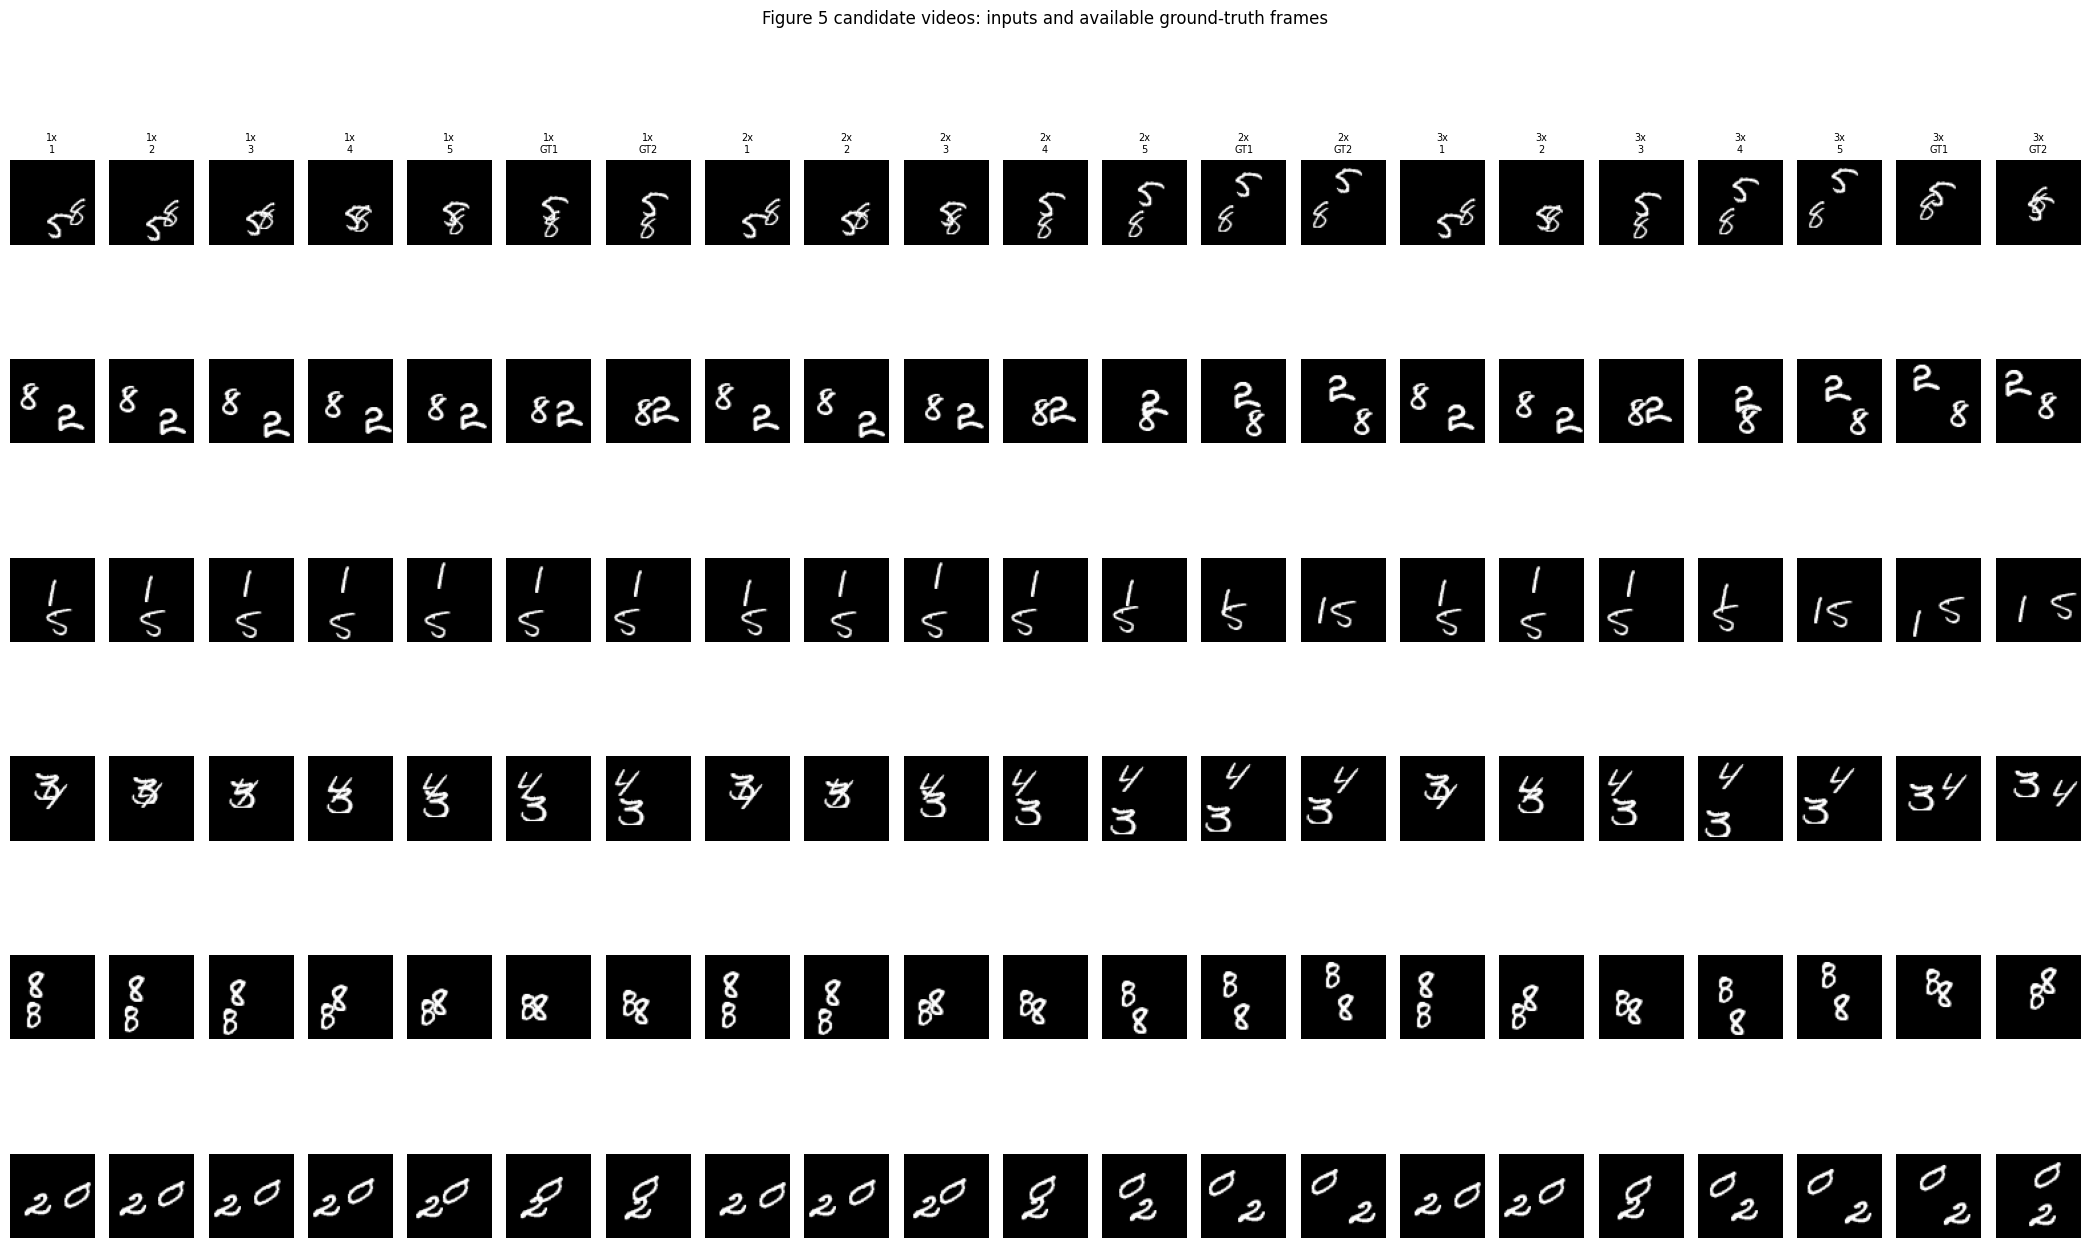

In [58]:

import matplotlib.pyplot as plt
import torch
from pathlib import Path

# Start with the first 6 test videos as candidates.
candidate_indices = list(range(6))

fig, axes = plt.subplots(
    len(candidate_indices), 21,
    figsize=(21, 2.2 * len(candidate_indices))
)

for row, idx in enumerate(candidate_indices):
    video = test_videos[idx]

    col = 0
    for speed, start in [(1, 1), (2, 1), (3, 1)]:
        X, Y = make_window(video, t=start, speed=speed)

        # Show five inputs and up to two available future ground-truth frames.
        frames = [X[i, 0] for i in range(5)]
        frames += [Y[i, 0] for i in range(min(2, len(Y)))]

        for j, frame in enumerate(frames):
            ax = axes[row, col]
            ax.imshow(frame.numpy(), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row == 0:
                ax.set_title(
                    f"{speed}x\n{j + 1 if j < 5 else 'GT' + str(j - 4)}",
                    fontsize=7
                )

            col += 1

    axes[row, 0].set_ylabel(f"Test {idx}", fontsize=8)

fig.suptitle(
    "Figure 5 candidate videos: inputs and available ground-truth frames",
    y=1.01
)
fig.tight_layout()
plt.show()


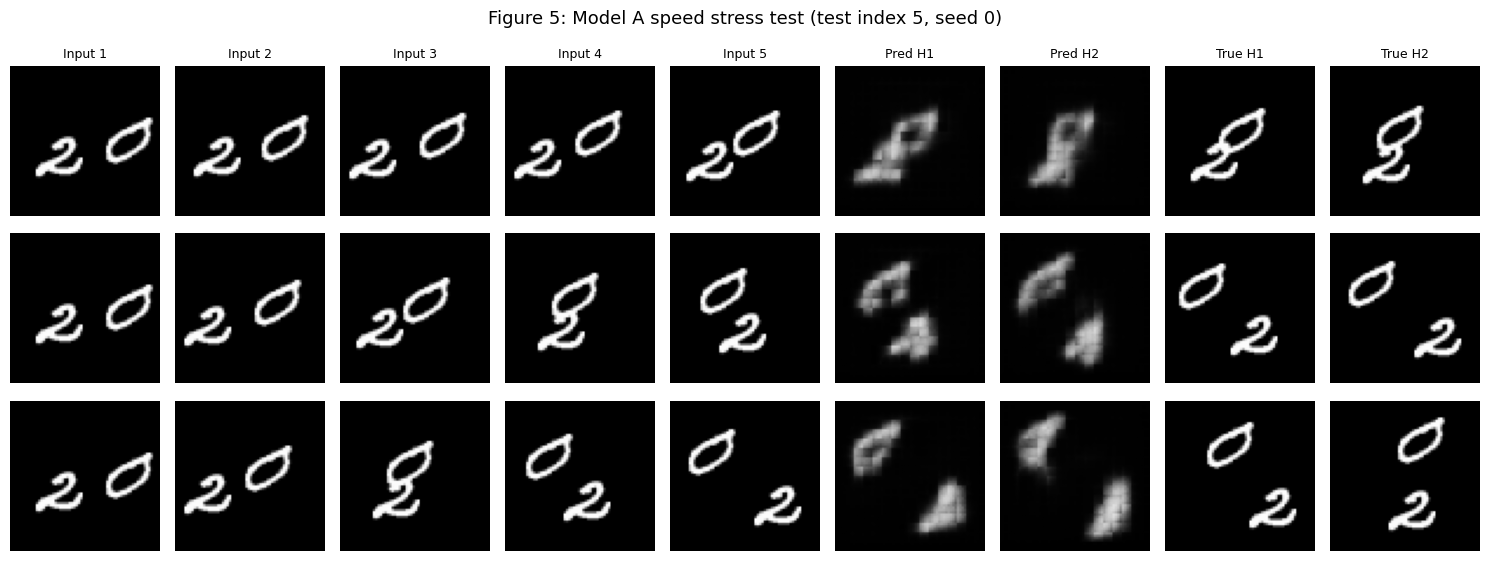

Saved: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure5_speed_stress_test.png


In [59]:

import matplotlib.pyplot as plt
from pathlib import Path
import torch
import numpy as np

# Sixth candidate in the contact sheet; zero-based test index.
figure5_test_index = 5
video = test_videos[figure5_test_index]

model = final_models_a[0]
model.eval()

speeds = [1, 2, 3]
figure5_results = {}

with torch.no_grad():
    for speed in speeds:
        X, Y = make_window(video, t=1, speed=speed)

        # Generate all five forecasts; only H1 and H2 are displayed.
        predictions = model_a_rollout(
            model, X.unsqueeze(0).to(device)
        ).cpu()[0]

        figure5_results[speed] = {
            "X": X.cpu(),
            "Y": Y.cpu(),
            "predictions": predictions,
        }

# Five inputs + two predictions + two ground-truth frames = nine columns.
fig, axes = plt.subplots(
    3, 9,
    figsize=(15, 5.8),
    squeeze=False
)

column_titles = [
    "Input 1", "Input 2", "Input 3", "Input 4", "Input 5",
    "Pred H1", "Pred H2", "True H1", "True H2"
]

for row, speed in enumerate(speeds):
    result = figure5_results[speed]
    X, Y, predictions = result["X"], result["Y"], result["predictions"]

    frames = [
        X[i, 0].numpy() for i in range(5)
    ] + [
        predictions[i, 0].numpy() for i in range(2)
    ] + [
        Y[i, 0].numpy() for i in range(2)
    ]

    for col, frame in enumerate(frames):
        axes[row, col].imshow(frame, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(column_titles[col], fontsize=9)

    axes[row, 0].set_ylabel(
        f"{speed}× speed",
        fontsize=11,
        rotation=90,
        labelpad=10
    )

fig.suptitle(
    f"Figure 5: Model A speed stress test (test index {figure5_test_index}, seed 0)",
    fontsize=13
)
fig.tight_layout()

figure5_path = Path("figures") / "Figure5_speed_stress_test.png"
figure5_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure5_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", figure5_path.resolve())


In [60]:

import torch

def randomly_transform_window(X, Y):
    """
    Apply the same randomly selected symmetry to input X and target Y.

    X: [5, 1, 64, 64]
    Y: [number of available target frames, 1, 64, 64]
    """
    rotation = int(torch.randint(0, 4, (1,)).item())
    mirrored = bool(torch.randint(0, 2, (1,)).item())

    X_transformed = apply_symmetry(
        X, a=rotation, mirrored=mirrored
    )
    Y_transformed = apply_symmetry(
        Y, a=rotation, mirrored=mirrored
    )

    return X_transformed, Y_transformed, rotation, mirrored


# Verify the helper on one real training video window.
sample_X, sample_Y = make_window(train_videos[0], t=1, speed=1)

aug_X, aug_Y, aug_rotation, aug_mirrored = randomly_transform_window(
    sample_X, sample_Y
)

print("Original input shape:", tuple(sample_X.shape))
print("Transformed input shape:", tuple(aug_X.shape))
print("Original target shape:", tuple(sample_Y.shape))
print("Transformed target shape:", tuple(aug_Y.shape))
print("Selected rotation:", aug_rotation)
print("Mirrored:", aug_mirrored)

assert aug_X.shape == sample_X.shape
assert aug_Y.shape == sample_Y.shape
assert torch.equal(
    aug_X,
    apply_symmetry(sample_X, a=aug_rotation, mirrored=aug_mirrored)
)
assert torch.equal(
    aug_Y,
    apply_symmetry(sample_Y, a=aug_rotation, mirrored=aug_mirrored)
)

print("Symmetry augmentation checks passed.")


Original input shape: (5, 1, 64, 64)
Transformed input shape: (5, 1, 64, 64)
Original target shape: (5, 1, 64, 64)
Transformed target shape: (5, 1, 64, 64)
Selected rotation: 3
Mirrored: True
Symmetry augmentation checks passed.


In [61]:

import inspect

for name, obj in list(globals().items()):
    if (
        inspect.isfunction(obj)
        and any(term in name.lower() for term in ["train", "fit"])
        and obj.__module__ == "__main__"
    ):
        try:
            print(f"{name}{inspect.signature(obj)}")
        except (TypeError, ValueError):
            print(name)


sample_training_window(video)
train_model_a(seed, epochs=30, batch_size=32, learning_rate=0.001)


In [63]:

import inspect
from pathlib import Path

source = inspect.getsource(train_model_a)
source_path = Path("train_model_a_source.txt")
source_path.write_text(source, encoding="utf-8")

print(source)
print("\nFull source saved to:", source_path.resolve())


def train_model_a(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    # Set all random seeds for this run.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create a fresh model and optimizer for this seed.
    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Each dataset item is one complete video.
    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    # Save outputs separately for each seed.
    output_dir = Path(f"model_a_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
       

In [65]:

source_lines = inspect.getsource(train_model_a).splitlines()

print("=== Lines 40–85 ===")
print("\n".join(
    f"{i + 1:03d}: {source_lines[i]}"
    for i in range(39, min(85, len(source_lines)))
))

print("\n=== Lines 86–136 ===")
print("\n".join(
    f"{i + 1:03d}: {source_lines[i]}"
    for i in range(85, min(136, len(source_lines)))
))


=== Lines 40–85 ===
040:             # Sample one 1x window per video in this batch.
041:             starts = torch.randint(
042:                 low=1,
043:                 high=12,
044:                 size=(videos_batch.size(0),),
045:                 device="cpu"
046:             ).tolist()
047: 
048:             inputs = []
049:             targets = []
050: 
051:             for i, start in enumerate(starts):
052:                 X, Y = make_window(
053:                     videos_batch[i],
054:                     t=start,
055:                     speed=1
056:                 )
057:                 inputs.append(X)
058:                 targets.append(Y)
059: 
060:             X_batch = torch.stack(inputs).to(run_device)
061:             Y_batch = torch.stack(targets).to(run_device)
062: 
063:             optimizer.zero_grad(set_to_none=True)
064: 
065:             predictions = model_a_rollout(model, X_batch)
066:             loss = per_video_mse(predictions, Y_batch).mean()
06

In [67]:

print("\n".join(
    f"{i + 1:03d}: {source_lines[i]}"
    for i in range(87, min(130, len(source_lines)))
))


088: 
089:                 X_val = batch[:, :5]
090:                 Y_val = batch[:, 5:10]
091: 
092:                 predictions = model_a_rollout(model, X_val)
093:                 losses = per_video_mse(predictions, Y_val)
094: 
095:                 val_loss_sum += losses.sum().item()
096:                 val_count += batch.size(0)
097: 
098:         val_loss = val_loss_sum / val_count
099: 
100:         record = {
101:             "epoch": epoch,
102:             "train_loss": train_loss,
103:             "val_loss": val_loss,
104:             "epoch_time_seconds": epoch_time
105:         }
106:         history.append(record)
107: 
108:         # Save the latest checkpoint every epoch.
109:         torch.save(
110:             {
111:                 "seed": seed,
112:                 "epoch": epoch,
113:                 "model_state_dict": model.state_dict(),
114:                 "optimizer_state_dict": optimizer.state_dict(),
115:                 "history": history
116:          

In [68]:

def train_model_b(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    # Reproduce the same random initialization and training protocol.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    output_dir = Path(f"model_b_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

            # Sample one normal-speed window per video.
            starts = torch.randint(
                low=1,
                high=12,
                size=(videos_batch.size(0),),
                device="cpu"
            ).tolist()

            inputs = []
            targets = []

            for i, start in enumerate(starts):
                X, Y = make_window(
                    videos_batch[i],
                    t=start,
                    speed=1
                )

                # Apply the same random symmetry to X and Y.
                X, Y, _, _ = randomly_transform_window(X, Y)

                inputs.append(X)
                targets.append(Y)

            X_batch = torch.stack(inputs).to(run_device)
            Y_batch = torch.stack(targets).to(run_device)

            optimizer.zero_grad(set_to_none=True)

            predictions = model_a_rollout(model, X_batch)
            loss = per_video_mse(predictions, Y_batch).mean()

            loss.backward()
            optimizer.step()

            batch_count = videos_batch.size(0)
            total_train_loss += loss.item() * batch_count
            videos_seen += batch_count

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        train_loss = total_train_loss / videos_seen

        # Validation stays unaugmented and uses t=1, speed=1.
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for start_idx in range(0, len(val_videos), batch_size):
                batch = val_videos[start_idx:start_idx + batch_size]
                batch = batch.to(run_device)

                X_val = batch[:, :5]
                Y_val = batch[:, 5:10]

                predictions = model_a_rollout(model, X_val)
                losses = per_video_mse(predictions, Y_val)

                val_loss_sum += losses.sum().item()
                val_count += batch.size(0)

        val_loss = val_loss_sum / val_count

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time_seconds": epoch_time
        }
        history.append(record)

        # Save the latest checkpoint at every epoch.
        checkpoint = {
            "seed": seed,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history
        }

        torch.save(checkpoint, output_dir / "latest_checkpoint.pt")

        # Also retain the checkpoint with the lowest validation loss.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(checkpoint, output_dir / "best_model.pt")

        print(
            f"Seed {seed} | Epoch {epoch:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f} | "
            f"Time: {epoch_time / 60:.2f} min"
        )

    mean_epoch_time = float(np.mean(epoch_times))

    print(f"\nModel B, seed {seed} finished.")
    print(f"Mean epoch time: {mean_epoch_time:.2f} seconds")
    print(f"Final training MSE: {history[-1]['train_loss']:.6f}")
    print(f"Final validation MSE: {history[-1]['val_loss']:.6f}")

    return model, history, mean_epoch_time


In [69]:
print("Model B training function defined:", callable(train_model_b))
print("Model A parameter count:", sum(
    p.numel() for p in ModelA().parameters()
))

Model B training function defined: True
Model A parameter count: 480784


In [70]:
model_b_seed0, history_b_seed0, epoch_time_b_seed0 = train_model_b(
    seed=0,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)

Seed 0 | Epoch 01/30 | Train MSE: 0.046136 | Val MSE: 0.039349 | Time: 0.26 min
Seed 0 | Epoch 02/30 | Train MSE: 0.039714 | Val MSE: 0.038582 | Time: 0.22 min
Seed 0 | Epoch 03/30 | Train MSE: 0.038745 | Val MSE: 0.037523 | Time: 0.22 min
Seed 0 | Epoch 04/30 | Train MSE: 0.037215 | Val MSE: 0.035539 | Time: 0.22 min
Seed 0 | Epoch 05/30 | Train MSE: 0.035377 | Val MSE: 0.033885 | Time: 0.21 min
Seed 0 | Epoch 06/30 | Train MSE: 0.033669 | Val MSE: 0.032781 | Time: 0.21 min
Seed 0 | Epoch 07/30 | Train MSE: 0.032096 | Val MSE: 0.030991 | Time: 0.21 min
Seed 0 | Epoch 08/30 | Train MSE: 0.031176 | Val MSE: 0.030272 | Time: 0.21 min
Seed 0 | Epoch 09/30 | Train MSE: 0.030299 | Val MSE: 0.030193 | Time: 0.21 min
Seed 0 | Epoch 10/30 | Train MSE: 0.029819 | Val MSE: 0.029138 | Time: 0.21 min
Seed 0 | Epoch 11/30 | Train MSE: 0.029380 | Val MSE: 0.028826 | Time: 0.21 min
Seed 0 | Epoch 12/30 | Train MSE: 0.029018 | Val MSE: 0.028388 | Time: 0.21 min
Seed 0 | Epoch 13/30 | Train MSE: 0.0285

In [71]:
model_b_seed1, history_b_seed1, epoch_time_b_seed1 = train_model_b(
    seed=1,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)

Seed 1 | Epoch 01/30 | Train MSE: 0.047833 | Val MSE: 0.039476 | Time: 0.22 min
Seed 1 | Epoch 02/30 | Train MSE: 0.040177 | Val MSE: 0.039472 | Time: 0.21 min
Seed 1 | Epoch 03/30 | Train MSE: 0.040189 | Val MSE: 0.039472 | Time: 0.22 min
Seed 1 | Epoch 04/30 | Train MSE: 0.040195 | Val MSE: 0.039471 | Time: 0.21 min
Seed 1 | Epoch 05/30 | Train MSE: 0.040190 | Val MSE: 0.039454 | Time: 0.21 min
Seed 1 | Epoch 06/30 | Train MSE: 0.039734 | Val MSE: 0.038245 | Time: 0.21 min
Seed 1 | Epoch 07/30 | Train MSE: 0.037869 | Val MSE: 0.035975 | Time: 0.22 min
Seed 1 | Epoch 08/30 | Train MSE: 0.035579 | Val MSE: 0.034475 | Time: 0.22 min
Seed 1 | Epoch 09/30 | Train MSE: 0.033456 | Val MSE: 0.031960 | Time: 0.22 min
Seed 1 | Epoch 10/30 | Train MSE: 0.031628 | Val MSE: 0.030372 | Time: 0.22 min
Seed 1 | Epoch 11/30 | Train MSE: 0.030327 | Val MSE: 0.029361 | Time: 0.22 min
Seed 1 | Epoch 12/30 | Train MSE: 0.029402 | Val MSE: 0.028861 | Time: 0.22 min
Seed 1 | Epoch 13/30 | Train MSE: 0.0287

In [72]:
from pathlib import Path
import torch

for seed in (0, 1):
    checkpoint_path = Path(f"model_b_seed_{seed}") / "latest_checkpoint.pt"
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print(
        f"Seed {seed}: "
        f"checkpoint exists={checkpoint_path.exists()}, "
        f"saved epoch={checkpoint['epoch']}, "
        f"history entries={len(checkpoint['history'])}"
    )

Seed 0: checkpoint exists=True, saved epoch=30, history entries=30
Seed 1: checkpoint exists=True, saved epoch=30, history entries=30


In [73]:

# Evaluate Model B using its final-epoch weights.
# This assumes the earlier Model A evaluation helpers and
# test_inputs / test_targets / transforms are still defined.

model_b_final_results = {}

for seed, model in [(0, model_b_seed0), (1, model_b_seed1)]:
    model.eval()

    # Original predictions and errors
    with torch.no_grad():
        predictions = predict_transformed_inputs(
            model, test_inputs, batch_size=32
        )
        horizon_mse = calculate_horizon_mse(
            predictions, test_targets
        )
        e5 = float(horizon_mse.mean().item())

    # Transformed-input predictions
    with torch.no_grad():
        mirror_inputs = mirror(test_inputs)
        rotation_inputs = rotate90(test_inputs, k=1)

        mirror_predictions = predict_transformed_inputs(
            model, mirror_inputs, batch_size=32
        )
        rotation_predictions = predict_transformed_inputs(
            model, rotation_inputs, batch_size=32
        )

        # Consistency: compare transformed-input predictions with
        # the corresponding transformation of original predictions.
        cm = float(((mirror_predictions - mirror(predictions)) ** 2).mean().item())
        cr = float(((rotation_predictions - rotate90(predictions, k=1)) ** 2).mean().item())

        # Transformed prediction error: compare with transformed targets.
        em = float(((mirror_predictions - mirror(test_targets)) ** 2).mean().item())
        er = float(((rotation_predictions - rotate90(test_targets, k=1)) ** 2).mean().item())

    model_b_final_results[seed] = {
        "predictions": predictions,
        "horizon_mse": horizon_mse,
        "e5": e5,
        "CM": cm,
        "EM": em,
        "CR": cr,
        "ER": er,
    }

    print(f"\nModel B — Seed {seed}")
    print("Horizon MSE:", [round(float(v), 6) for v in horizon_mse])
    print(f"E5: {e5:.6f}")
    print(f"CM: {cm:.6f} | EM: {em:.6f}")
    print(f"CR: {cr:.6f} | ER: {er:.6f}")



Model B — Seed 0
Horizon MSE: [0.016361, 0.020358, 0.022878, 0.024706, 0.026369]
E5: 0.022134
CM: 0.001148 | EM: 0.022172
CR: 0.001430 | ER: 0.022175

Model B — Seed 1
Horizon MSE: [0.016884, 0.020456, 0.022796, 0.024619, 0.026297]
E5: 0.022210
CM: 0.001149 | EM: 0.022182
CR: 0.001676 | ER: 0.022219


In [76]:
import numpy as np

# Mean results from the completed evaluations
summary = {
    "Model A": {
        "E5": [0.0224572383, 0.0219049565],
        "CM": [0.0018154628, 0.0017605532],
        "EM": [0.0231457651, 0.0225705560],
        "CR": [0.0030672697, 0.0029286563],
        "ER": [0.0241904631, 0.0235639885],
    },
    "Model B": {
        "E5": [model_b_final_results[s]["e5"] for s in (0, 1)],
        "CM": [model_b_final_results[s]["CM"] for s in (0, 1)],
        "EM": [model_b_final_results[s]["EM"] for s in (0, 1)],
        "CR": [model_b_final_results[s]["CR"] for s in (0, 1)],
        "ER": [model_b_final_results[s]["ER"] for s in (0, 1)],
    },
}

for model_name, metrics_dict in summary.items():
    print(f"\n{model_name} — mean across seeds")
    for metric, values in metrics_dict.items():
        print(f"{metric}: {np.mean(values):.6f}")


Model A — mean across seeds
E5: 0.022181
CM: 0.001788
EM: 0.022858
CR: 0.002998
ER: 0.023877

Model B — mean across seeds
E5: 0.022172
CM: 0.001148
EM: 0.022177
CR: 0.001553
ER: 0.022197


In [77]:
print("Allowed training starts by speed:")
for speed, starts in allowed_starts.items():
    print(f"{speed}x: {list(starts)}")

Allowed training starts by speed:
1x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
2x: [1, 2, 3, 4, 5, 6, 7, 8]
3x: [1, 2]


In [126]:

def train_model_c(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    output_dir = Path(f"model_c_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

            # Randomly choose 1x, 2x, or 3x speed for each video.
            speeds = torch.randint(
                low=1,
                high=4,
                size=(videos_batch.size(0),),
                device="cpu"
            ).tolist()

            inputs = []
            targets = []
            target_lengths = []

            for i, speed in enumerate(speeds):
                start = random.choice(allowed_starts_cd_train[speed])

                X, Y = make_window(
                    videos_batch[i],
                    t=start,
                    speed=speed
                )

                inputs.append(X)
                target_lengths.append(Y.size(0))

                # Pad shorter targets to five frames.
                if Y.size(0) < 5:
                    padding = torch.zeros(
                        (5 - Y.size(0), *Y.shape[1:]),
                        dtype=Y.dtype,
                        device=Y.device
                    )
                    Y = torch.cat([Y, padding], dim=0)

                targets.append(Y)

            X_batch = torch.stack(inputs).to(run_device)
            Y_batch = torch.stack(targets).to(run_device)

            optimizer.zero_grad(set_to_none=True)

            # Always produce five forecasts.
            predictions = model_a_rollout(model, X_batch)

            # Ignore padded target frames in the training loss.
            losses = per_video_mse_masked(
                predictions,
                Y_batch,
                target_lengths
            )
            loss = losses.mean()

            loss.backward()
            optimizer.step()

            batch_count = videos_batch.size(0)
            total_train_loss += loss.item() * batch_count
            videos_seen += batch_count

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        train_loss = total_train_loss / videos_seen

        # Original 1x validation, unchanged.
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for start_idx in range(0, len(val_videos), batch_size):
                batch = val_videos[start_idx:start_idx + batch_size]
                batch = batch.to(run_device)

                X_val = batch[:, :5]
                Y_val = batch[:, 5:10]

                predictions = model_a_rollout(model, X_val)
                losses = per_video_mse(predictions, Y_val)

                val_loss_sum += losses.sum().item()
                val_count += batch.size(0)

        val_loss = val_loss_sum / val_count

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time_seconds": epoch_time
        }
        history.append(record)

        checkpoint = {
            "seed": seed,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history
        }

        torch.save(checkpoint, output_dir / "latest_checkpoint.pt")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(checkpoint, output_dir / "best_model.pt")

        print(
            f"Seed {seed} | Epoch {epoch:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f} | "
            f"Time: {epoch_time / 60:.2f} min"
        )

    mean_epoch_time = float(np.mean(epoch_times))

    print(f"\nModel C, seed {seed} finished.")
    print(f"Mean epoch time: {mean_epoch_time:.2f} seconds")
    print(f"Final training MSE: {history[-1]['train_loss']:.6f}")
    print(f"Final validation MSE: {history[-1]['val_loss']:.6f}")

    return model, history, mean_epoch_time


In [ ]:
print("Model A architecture:")
print(model_a_seed0)

print("\nTotal trainable parameters:")
print(sum(p.numel() for p in model_a_seed0.parameters() if p.requires_grad))

Model A architecture:
ModelA(
  (pixel_unshuffle): PixelUnshuffle(downscale_factor=4)
  (convlstm1): ConvLSTMCell(
    (gates): Conv2d(80, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm2): ConvLSTMCell(
    (gates): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=4)
)

Total trainable parameters:
480784


In [79]:
print("Model C training function defined:", callable(train_model_c))

Model C training function defined: True


In [81]:

def per_video_mse_masked(predictions, targets, target_lengths):
    """
    predictions: [B, 5, C, H, W]
    targets:     [B, 5, C, H, W], padded where targets are unavailable
    target_lengths: list or tensor containing each video's valid target count

    Returns one MSE value per video, averaging only over valid target frames
    and their pixels.
    """
    lengths = torch.as_tensor(
        target_lengths,
        device=predictions.device
    )

    horizon_indices = torch.arange(
        predictions.size(1),
        device=predictions.device
    )

    mask = horizon_indices.unsqueeze(0) < lengths.unsqueeze(1)
    mask = mask[:, :, None, None, None]

    squared_error = (predictions - targets) ** 2
    squared_error = squared_error * mask

    valid_pixels_per_video = (
        lengths * predictions.size(2) * predictions.size(3) * predictions.size(4)
    )

    return squared_error.sum(dim=(1, 2, 3, 4)) / valid_pixels_per_video


In [82]:
dummy_predictions = torch.ones(2, 5, 1, 2, 2)
dummy_targets = torch.zeros(2, 5, 1, 2, 2)

# Video 1 has 5 valid targets; video 2 has only 2.
test_losses = per_video_mse_masked(
    dummy_predictions,
    dummy_targets,
    [5, 2]
)

print("Masked test losses:", test_losses.tolist())

Masked test losses: [1.0, 1.0]


In [129]:
model_c_seed0, history_c_seed0, epoch_time_c_seed0 = train_model_c(
    seed=0,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)

Seed 0 | Epoch 01/30 | Train MSE: 0.046603 | Val MSE: 0.039381 | Time: 0.24 min
Seed 0 | Epoch 02/30 | Train MSE: 0.039919 | Val MSE: 0.038858 | Time: 0.21 min
Seed 0 | Epoch 03/30 | Train MSE: 0.039360 | Val MSE: 0.038283 | Time: 0.21 min
Seed 0 | Epoch 04/30 | Train MSE: 0.038629 | Val MSE: 0.037579 | Time: 0.21 min
Seed 0 | Epoch 05/30 | Train MSE: 0.037681 | Val MSE: 0.035701 | Time: 0.21 min
Seed 0 | Epoch 06/30 | Train MSE: 0.036741 | Val MSE: 0.035223 | Time: 0.21 min
Seed 0 | Epoch 07/30 | Train MSE: 0.036008 | Val MSE: 0.034369 | Time: 0.21 min
Seed 0 | Epoch 08/30 | Train MSE: 0.035331 | Val MSE: 0.032840 | Time: 0.21 min
Seed 0 | Epoch 09/30 | Train MSE: 0.034761 | Val MSE: 0.032521 | Time: 0.21 min
Seed 0 | Epoch 10/30 | Train MSE: 0.034412 | Val MSE: 0.033232 | Time: 0.21 min
Seed 0 | Epoch 11/30 | Train MSE: 0.033960 | Val MSE: 0.031492 | Time: 0.21 min
Seed 0 | Epoch 12/30 | Train MSE: 0.033653 | Val MSE: 0.031196 | Time: 0.21 min
Seed 0 | Epoch 13/30 | Train MSE: 0.0333

In [130]:
model_c_seed1, history_c_seed1, epoch_time_c_seed1 = train_model_c(
    seed=1,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)

Seed 1 | Epoch 01/30 | Train MSE: 0.048301 | Val MSE: 0.039476 | Time: 0.31 min
Seed 1 | Epoch 02/30 | Train MSE: 0.040190 | Val MSE: 0.039431 | Time: 0.24 min
Seed 1 | Epoch 03/30 | Train MSE: 0.040123 | Val MSE: 0.039346 | Time: 0.21 min
Seed 1 | Epoch 04/30 | Train MSE: 0.039845 | Val MSE: 0.038755 | Time: 0.21 min
Seed 1 | Epoch 05/30 | Train MSE: 0.039167 | Val MSE: 0.037315 | Time: 0.21 min
Seed 1 | Epoch 06/30 | Train MSE: 0.037723 | Val MSE: 0.035629 | Time: 0.21 min
Seed 1 | Epoch 07/30 | Train MSE: 0.036357 | Val MSE: 0.034102 | Time: 0.21 min
Seed 1 | Epoch 08/30 | Train MSE: 0.035393 | Val MSE: 0.033524 | Time: 0.21 min
Seed 1 | Epoch 09/30 | Train MSE: 0.034776 | Val MSE: 0.032089 | Time: 0.21 min
Seed 1 | Epoch 10/30 | Train MSE: 0.034266 | Val MSE: 0.032077 | Time: 0.21 min
Seed 1 | Epoch 11/30 | Train MSE: 0.033653 | Val MSE: 0.030948 | Time: 0.21 min
Seed 1 | Epoch 12/30 | Train MSE: 0.033217 | Val MSE: 0.030417 | Time: 0.21 min
Seed 1 | Epoch 13/30 | Train MSE: 0.0328

In [131]:
from pathlib import Path
import torch

for seed in (0, 1):
    checkpoint_path = Path(f"model_c_seed_{seed}") / "latest_checkpoint.pt"
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print(
        f"Seed {seed}: "
        f"checkpoint exists={checkpoint_path.exists()}, "
        f"saved epoch={checkpoint['epoch']}, "
        f"history entries={len(checkpoint['history'])}"
    )

Seed 0: checkpoint exists=True, saved epoch=30, history entries=30
Seed 1: checkpoint exists=True, saved epoch=30, history entries=30


In [88]:
import inspect

print("Function signature:")
print(inspect.signature(evaluate_speed_for_seed))

Function signature:
(model, speed, starts, videos=tensor([[[[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         ...,


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0.

In [89]:

speed_results_c = {}

models_c = {
    0: model_c_seed0,
    1: model_c_seed1,
}

for seed, model in models_c.items():
    speed_results_c[seed] = {}

    for speed in (1, 2, 3):
        result = evaluate_speed_for_seed(
            model=model,
            speed=speed,
            starts=allowed_starts[speed],
            videos=test_videos,
            batch_size=32
        )

        speed_results_c[seed][speed] = result

        print(f"\nModel C — Seed {seed} — Speed {speed}x")
        print(result)



Model C — Seed 0 — Speed 1x
{'e2': 0.02398078702390194, 'e5': 0.027646636590361595, 'horizon_mse': array([0.02230286, 0.02565871, 0.02807189, 0.0301575 , 0.03204222]), 'horizon_counts': array([45056000., 45056000., 45056000., 45056000., 45056000.]), 'num_starts': 11}

Model C — Seed 0 — Speed 2x
{'e2': 0.029723891988396645, 'e5': 0.03180493041872978, 'horizon_mse': array([0.02731678, 0.03213102, 0.03458102, 0.03611363, 0.03710977]), 'horizon_counts': array([32768000., 32768000., 24576000., 16384000.,  8192000.]), 'num_starts': 8}

Model C — Seed 0 — Speed 3x
{'e2': 0.03376813977956772, 'e5': 0.03376813977956772, 'horizon_mse': array([0.03179287, 0.0357434 ,        nan,        nan,        nan]), 'horizon_counts': array([8192000., 8192000.,       0.,       0.,       0.]), 'num_starts': 2}

Model C — Seed 1 — Speed 1x
{'e2': 0.023448463529348373, 'e5': 0.02680843323469162, 'horizon_mse': array([0.02185375, 0.02504318, 0.02726513, 0.02906578, 0.03081431]), 'horizon_counts': array([4505600

In [132]:
import numpy as np

print("Model C — mean across seeds")

for speed in (1, 2, 3):
    e2_values = [
        speed_results_c[seed][speed]["e2"]
        for seed in (0, 1)
    ]
    e5_values = [
        speed_results_c[seed][speed]["e5"]
        for seed in (0, 1)
    ]

    print(
        f"{speed}x | "
        f"E2: {np.mean(e2_values):.6f} | "
        f"E5: {np.mean(e5_values):.6f}"
    )

Model C — mean across seeds
1x | E2: 0.023715 | E5: 0.027228
2x | E2: 0.029451 | E5: 0.031571
3x | E2: 0.033569 | E5: 0.033569


In [91]:
# Find the existing model and ConvLSTM class names
for name, obj in globals().copy().items():
    if isinstance(obj, type) and (
        "lstm" in name.lower()
        or "model" in name.lower()
        or "motion" in name.lower()
    ):
        print(name)

ConvLSTMCell
ModelA


In [93]:
print("Model A architecture:")
print(model_a_seed0)

print("\nTotal trainable parameters:")
print(sum(p.numel() for p in model_a_seed0.parameters() if p.requires_grad))

Model A architecture:
ModelA(
  (pixel_unshuffle): PixelUnshuffle(downscale_factor=4)
  (convlstm1): ConvLSTMCell(
    (gates): Conv2d(80, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm2): ConvLSTMCell(
    (gates): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=4)
)

Total trainable parameters:
480784


In [94]:

import torch
import torch.nn as nn

class ModelD(nn.Module):
    def __init__(self):
        super().__init__()

        self.pixel_unshuffle = nn.PixelUnshuffle(4)

        self.convlstm1 = ConvLSTMCell(input_channels=16, hidden_channels=64)
        self.convlstm2 = ConvLSTMCell(input_channels=64, hidden_channels=64)
        self.convlstm3 = ConvLSTMCell(input_channels=64, hidden_channels=64)

        self.output_conv = nn.Conv2d(64, 16, kernel_size=1)
        self.pixel_shuffle = nn.PixelShuffle(4)

    def forward(self, x, states):
        # x: [batch, 1, 64, 64]
        # states: [(h1, c1), (h2, c2), (h3, c3)]

        x = self.pixel_unshuffle(x)

        h1, c1 = self.convlstm1(x, states[0])
        h2, c2 = self.convlstm2(h1, states[1])
        h3, c3 = self.convlstm3(h2, states[2])

        output = self.output_conv(h3)
        output = self.pixel_shuffle(output)
        output = torch.sigmoid(output)

        new_states = [(h1, c1), (h2, c2), (h3, c3)]

        return output, new_states


In [95]:
import inspect

print("Constructor signature:")
print(inspect.signature(ConvLSTMCell.__init__))

print("\nForward signature:")
print(inspect.signature(ConvLSTMCell.forward))

Constructor signature:
(self, input_channels, hidden_channels, kernel_size=3)

Forward signature:
(self, x, h_prev, c_prev)


In [98]:

import torch
import torch.nn as nn


class ModelD(nn.Module):
    def __init__(self):
        super().__init__()

        hidden = 56

        self.pixel_unshuffle = nn.PixelUnshuffle(4)

        self.convlstm1 = ConvLSTMCell(16, hidden)
        self.convlstm2 = ConvLSTMCell(hidden, hidden)
        self.convlstm3 = ConvLSTMCell(hidden, hidden)

        self.output_conv = nn.Conv2d(hidden, 16, kernel_size=1)
        self.pixel_shuffle = nn.PixelShuffle(4)

    def forward(self, x, states):
        x = self.pixel_unshuffle(x)

        h1, c1 = self.convlstm1(x, states[0][0], states[0][1])
        h2, c2 = self.convlstm2(h1, states[1][0], states[1][1])
        h3, c3 = self.convlstm3(h2, states[2][0], states[2][1])

        output = self.output_conv(h3)
        output = self.pixel_shuffle(output)
        output = torch.sigmoid(output)

        new_states = [(h1, c1), (h2, c2), (h3, c3)]

        return output, new_states


In [99]:
model_d_check = ModelD()

params_d = sum(
    p.numel()
    for p in model_d_check.parameters()
    if p.requires_grad
)

print(f"Model D parameters: {params_d:,}")
print(f"Assignment limit:   {721176:,}")
print(f"Within limit:       {params_d <= 721176}")

Model D parameters: 598,320
Assignment limit:   721,176
Within limit:       True


In [100]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_d_check = ModelD().to(device)

batch_size = 2
dummy_x = torch.rand(batch_size, 1, 64, 64, device=device)

# The recurrent state lives on the folded 16 x 16 grid.
hidden = 56
dummy_states = [
    (
        torch.zeros(batch_size, hidden, 16, 16, device=device),
        torch.zeros(batch_size, hidden, 16, 16, device=device),
    )
    for _ in range(3)
]

with torch.no_grad():
    dummy_output, new_states = model_d_check(dummy_x, dummy_states)

print("Input shape:", tuple(dummy_x.shape))
print("Output shape:", tuple(dummy_output.shape))
print("Number of recurrent layers:", len(new_states))
print("Output values in [0, 1]:",
      bool((dummy_output >= 0).all() and (dummy_output <= 1).all()))


Input shape: (2, 1, 64, 64)
Output shape: (2, 1, 64, 64)
Number of recurrent layers: 3
Output values in [0, 1]: True


In [101]:
import inspect

print(inspect.signature(train_model_c))

(seed, epochs=30, batch_size=32, learning_rate=0.001)


In [102]:
import inspect

try:
    print(inspect.getsource(train_model_c))
except OSError:
    print("Notebook source is unavailable; we will use the notebook cell history instead.")

def train_model_c(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    output_dir = Path(f"model_c_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

            # Randomly choose 1x, 2x, or 3x s

In [103]:
import inspect

print(inspect.signature(model_a_rollout))

try:
    print(inspect.getsource(model_a_rollout))
except OSError:
    print("Source unavailable; please locate the cell defining model_a_rollout.")

(model, input_frames)
def model_a_rollout(model, input_frames):
    """
    input_frames: (B, 5, 1, 64, 64)
    Returns:      (B, 5, 1, 64, 64), predictions for frames 6-10
    """
    batch_size = input_frames.shape[0]

    # Initialize recurrent states to zero for each video.
    h1 = torch.zeros(
        batch_size, 64, 16, 16,
        device=input_frames.device,
        dtype=input_frames.dtype
    )
    c1 = torch.zeros_like(h1)
    h2 = torch.zeros_like(h1)
    c2 = torch.zeros_like(h1)

    predictions = []
    current_frame = None

    # Nine recurrent steps in total.
    for step in range(9):
        if step < 5:
            # First five steps use the observed frames.
            current_frame = input_frames[:, step]
        # Steps 5-8 use the previous prediction as input.
        # current_frame already contains that prediction.

        features = model.pixel_unshuffle(current_frame)

        h1, c1 = model.convlstm1(features, h1, c1)
        h2, c2 = model.convlstm2(h1, h2

In [104]:

def model_d_rollout(model, input_frames):
    """
    input_frames: (B, 5, 1, 64, 64)
    Returns:      (B, 5, 1, 64, 64), predictions for frames 6-10
    """
    batch_size = input_frames.shape[0]
    device = input_frames.device
    dtype = input_frames.dtype

    # Initialize three ConvLSTM layers' hidden and cell states.
    hidden = 56

    states = [
        (
            torch.zeros(batch_size, hidden, 16, 16,
                        device=device, dtype=dtype),
            torch.zeros(batch_size, hidden, 16, 16,
                        device=device, dtype=dtype)
        )
        for _ in range(3)
    ]

    predictions = []
    current_frame = None

    # Five observed frames, followed by four feedback steps.
    for step in range(9):
        if step < 5:
            current_frame = input_frames[:, step]

        output, states = model(current_frame, states)

        # Save the five predictions for frames 6-10.
        if step >= 4:
            predictions.append(output)

        # Feed the prediction into the next recurrent step.
        current_frame = output

    return torch.stack(predictions, dim=1)


In [105]:
model_d_check.eval()

dummy_input = torch.rand(2, 5, 1, 64, 64, device=device)

with torch.no_grad():
    dummy_predictions = model_d_rollout(model_d_check, dummy_input)

print("Input shape:", tuple(dummy_input.shape))
print("Prediction shape:", tuple(dummy_predictions.shape))
print("All predictions finite:", bool(torch.isfinite(dummy_predictions).all()))

Input shape: (2, 5, 1, 64, 64)
Prediction shape: (2, 5, 1, 64, 64)
All predictions finite: True


In [237]:

def train_model_d(
    seed,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3,
    output_dir=None
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Model D has three ConvLSTM layers with 56 hidden channels.
    model = ModelD().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    # Preserve the original folder names unless a separate path is supplied.
    if output_dir is None:
        output_dir = Path(f"model_d_seed_{seed}")
    else:
        output_dir = Path(output_dir)

    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

            # Randomly choose 1x, 2x, or 3x speed for each video.
            speeds = torch.randint(
                low=1,
                high=4,
                size=(videos_batch.size(0),),
                device="cpu"
            ).tolist()

            inputs = []
            targets = []
            target_lengths = []

            for i, speed in enumerate(speeds):
                start = random.choice(allowed_starts_cd_train[speed])

                X, Y = make_window(
                    videos_batch[i],
                    t=start,
                    speed=speed
                )

                inputs.append(X)
                target_lengths.append(Y.size(0))

                # Pad shorter targets to five frames.
                if Y.size(0) < 5:
                    padding = torch.zeros(
                        (5 - Y.size(0), *Y.shape[1:]),
                        dtype=Y.dtype,
                        device=Y.device
                    )
                    Y = torch.cat([Y, padding], dim=0)

                targets.append(Y)

            X_batch = torch.stack(inputs).to(run_device)
            Y_batch = torch.stack(targets).to(run_device)

            optimizer.zero_grad(set_to_none=True)

            predictions = model_d_rollout(model, X_batch)

            losses = per_video_mse_masked(
                predictions,
                Y_batch,
                target_lengths
            )
            loss = losses.mean()

            loss.backward()
            optimizer.step()

            batch_count = videos_batch.size(0)
            total_train_loss += loss.item() * batch_count
            videos_seen += batch_count

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        train_loss = total_train_loss / videos_seen

        # Original 1x validation, unchanged.
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for start_idx in range(0, len(val_videos), batch_size):
                batch = val_videos[start_idx:start_idx + batch_size]
                batch = batch.to(run_device)

                X_val = batch[:, :5]
                Y_val = batch[:, 5:10]

                predictions = model_d_rollout(model, X_val)
                losses = per_video_mse(predictions, Y_val)

                val_loss_sum += losses.sum().item()
                val_count += batch.size(0)

        val_loss = val_loss_sum / val_count

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time_seconds": epoch_time
        }
        history.append(record)

        checkpoint = {
            "seed": seed,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history
        }

        torch.save(checkpoint, output_dir / "latest_checkpoint.pt")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(checkpoint, output_dir / "best_model.pt")

        print(
            f"Model D | Seed {seed} | Epoch {epoch:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f} | "
            f"Time: {epoch_time / 60:.2f} min"
        )

    mean_epoch_time = float(np.mean(epoch_times))

    print(f"\nModel D, seed {seed} finished.")
    print(f"Mean epoch time: {mean_epoch_time:.2f} seconds")
    print(f"Final training MSE: {history[-1]['train_loss']:.6f}")
    print(f"Final validation MSE: {history[-1]['val_loss']:.6f}")

    return model, history, mean_epoch_time


In [107]:
import inspect

print(inspect.signature(train_model_d))
print("Model D parameters:", sum(
    p.numel() for p in ModelD().parameters() if p.requires_grad
))

(seed, epochs=30, batch_size=32, learning_rate=0.001)
Model D parameters: 598320


In [234]:

python_rng_state = random.getstate()
numpy_rng_state = np.random.get_state()
torch_rng_state = torch.get_rng_state()
cuda_rng_state = (
    torch.cuda.get_rng_state_all()
    if torch.cuda.is_available()
    else None
)

try:
    # Create a fresh Seed 0 model and capture its initial output layer.
    random.seed(0)
    np.random.seed(0)
    torch.manual_seed(0)
    torch.cuda.manual_seed_all(0)

    initial_model = ModelD().to(
        torch.device("cuda" if torch.cuda.is_available() else "cpu")
    )

    initial_weight = initial_model.output_conv.weight.detach().clone()
    initial_bias = initial_model.output_conv.bias.detach().clone()

    print("Initial output-weight std:",
          initial_weight.std().item())
    print("Initial output-bias mean:",
          initial_bias.mean().item())

    # Train a fresh Seed 0 model.
    # Use a separate output directory to protect the existing checkpoints.
    import inspect

    print("\nTraining uses output directory: model_d_seed_0")
    print("IMPORTANT: this function overwrites files in that directory.")
finally:
    random.setstate(python_rng_state)
    np.random.set_state(numpy_rng_state)
    torch.set_rng_state(torch_rng_state)

    if cuda_rng_state is not None:
        torch.cuda.set_rng_state_all(cuda_rng_state)

Initial output-weight std: 0.07762355357408524
Initial output-bias mean: -0.0017377426847815514

Training uses output directory: model_d_seed_0
IMPORTANT: this function overwrites files in that directory.


In [135]:
model_d_seed1, history_d_seed1, epoch_time_d_seed1 = train_model_d(
    seed=1,
    epochs=30,
    batch_size=32,
    learning_rate=1e-3
)

Model D | Seed 1 | Epoch 01/30 | Train MSE: 0.048346 | Val MSE: 0.039281 | Time: 0.33 min
Model D | Seed 1 | Epoch 02/30 | Train MSE: 0.039785 | Val MSE: 0.038578 | Time: 0.28 min
Model D | Seed 1 | Epoch 03/30 | Train MSE: 0.039094 | Val MSE: 0.037911 | Time: 0.28 min
Model D | Seed 1 | Epoch 04/30 | Train MSE: 0.038500 | Val MSE: 0.037540 | Time: 0.28 min
Model D | Seed 1 | Epoch 05/30 | Train MSE: 0.038190 | Val MSE: 0.037275 | Time: 0.28 min
Model D | Seed 1 | Epoch 06/30 | Train MSE: 0.038014 | Val MSE: 0.037270 | Time: 0.28 min
Model D | Seed 1 | Epoch 07/30 | Train MSE: 0.037212 | Val MSE: 0.034280 | Time: 0.28 min
Model D | Seed 1 | Epoch 08/30 | Train MSE: 0.035358 | Val MSE: 0.032832 | Time: 0.28 min
Model D | Seed 1 | Epoch 09/30 | Train MSE: 0.034207 | Val MSE: 0.031467 | Time: 0.28 min
Model D | Seed 1 | Epoch 10/30 | Train MSE: 0.033550 | Val MSE: 0.030769 | Time: 0.28 min
Model D | Seed 1 | Epoch 11/30 | Train MSE: 0.033035 | Val MSE: 0.030610 | Time: 0.28 min
Model D | 

In [136]:
from pathlib import Path
import torch

for seed in (0, 1):
    checkpoint_path = Path(f"model_d_seed_{seed}/latest_checkpoint.pt")

    print(f"\nSeed {seed}")
    print("Checkpoint exists:", checkpoint_path.exists())

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )
        print("Saved epoch:", checkpoint["epoch"])
        print("History length:", len(checkpoint["history"]))


Seed 0
Checkpoint exists: True
Saved epoch: 30
History length: 30

Seed 1
Checkpoint exists: True
Saved epoch: 30
History length: 30


In [138]:

def evaluate_speed_for_model_d(
    model, speed, starts, videos=test_videos, batch_size=32
):
    run_device = next(model.parameters()).device
    model.eval()

    X_all = []
    Y_all = []
    target_lengths = []

    # Create every allowed window for every supplied video.
    for video in videos:
        for start in starts:
            X, Y = make_window(video, t=start, speed=speed)

            X_all.append(X)
            target_lengths.append(Y.size(0))

            if Y.size(0) < 5:
                padding = torch.zeros(
                    (5 - Y.size(0), *Y.shape[1:]),
                    dtype=Y.dtype,
                    device=Y.device
                )
                Y = torch.cat([Y, padding], dim=0)

            Y_all.append(Y)

    X_all = torch.stack(X_all)
    Y_all = torch.stack(Y_all)

    predictions = []

    with torch.no_grad():
        for begin in range(0, len(X_all), batch_size):
            batch_X = X_all[begin:begin + batch_size].to(run_device)

            batch_predictions = model_d_rollout(model, batch_X)
            predictions.append(batch_predictions.cpu())

    predictions = torch.cat(predictions, dim=0)

    # Compute per-horizon MSE using only windows with a valid target.
    horizon_mse = []

    for horizon in range(5):
        valid_indices = [
            i for i, length in enumerate(target_lengths)
            if length > horizon
        ]

        if not valid_indices:
            horizon_mse.append(float("nan"))
            continue

        idx = torch.tensor(valid_indices, dtype=torch.long)

        errors = (
            predictions[idx, horizon] - Y_all[idx, horizon]
        ) ** 2

        horizon_mse.append(errors.mean().item())

    horizon_mse = np.array(horizon_mse, dtype=float)

    e2 = float(np.mean(horizon_mse[:2]))

    # E5 is only valid when all five horizons have ground truth.
    if np.isfinite(horizon_mse).all():
        e5 = float(np.mean(horizon_mse))
    else:
        e5 = float("nan")

    return {
        "e2": e2,
        "e5": e5,
        "horizon_mse": horizon_mse,
        "num_starts": len(starts),
        "num_windows": len(X_all)
    }


In [139]:
test_result = evaluate_speed_for_model_d(
    model=model_d_seed0,
    speed=1,
    starts=allowed_starts[1],
    videos=test_videos,
    batch_size=32
)

print(test_result)

{'e2': 0.04010489955544472, 'e5': 0.0401104673743248, 'horizon_mse': array([0.04010752, 0.04010228, 0.04010767, 0.04011267, 0.04012219]), 'num_starts': 11, 'num_windows': 11000}


In [137]:

speed_results_d = {}

models_d = {
    0: model_d_seed0,
    1: model_d_seed1,
}

for seed, model in models_d.items():
    speed_results_d[seed] = {}

    for speed in (1, 2, 3):
        result = evaluate_speed_for_model_d(
            model=model,
            speed=speed,
            starts=allowed_starts[speed],
            videos=test_videos,
            batch_size=32
        )

        speed_results_d[seed][speed] = result

        print(f"\nModel D — Seed {seed} — Speed {speed}x")
        print(f"E2: {result['e2']:.6f}")
        print(f"E5: {result['e5']:.6f}")
        print("Horizon MSE:", result["horizon_mse"])
        print("Number of windows:", result["num_windows"])



Model D — Seed 0 — Speed 1x
E2: 0.040105
E5: 0.040110
Horizon MSE: [0.04010752 0.04010228 0.04010767 0.04011267 0.04012219]
Number of windows: 11000

Model D — Seed 0 — Speed 2x
E2: 0.040116
E5: 0.040156
Horizon MSE: [0.04010316 0.04012926 0.0401534  0.04018668 0.04020838]
Number of windows: 8000

Model D — Seed 0 — Speed 3x
E2: 0.040163
E5: nan
Horizon MSE: [0.04011842 0.04020847        nan        nan        nan]
Number of windows: 2000

Model D — Seed 1 — Speed 1x
E2: 0.021920
E5: 0.025014
Horizon MSE: [0.02039596 0.02344499 0.02544023 0.02710568 0.02868409]
Number of windows: 11000

Model D — Seed 1 — Speed 2x
E2: 0.027166
E5: 0.031136
Horizon MSE: [0.0251576  0.02917388 0.03183131 0.03398257 0.035535  ]
Number of windows: 8000

Model D — Seed 1 — Speed 3x
E2: 0.031289
E5: nan
Horizon MSE: [0.0289976  0.03358056        nan        nan        nan]
Number of windows: 2000


In [140]:

def evaluate_transformations_model_d(
    model,
    inputs=test_inputs,
    targets=test_targets,
    batch_size=32
):
    device = next(model.parameters()).device
    model.eval()

    def predict(x):
        batches = []
        with torch.no_grad():
            for start in range(0, len(x), batch_size):
                batch = x[start:start + batch_size].to(device)
                batches.append(model_d_rollout(model, batch).cpu())
        return torch.cat(batches, dim=0)

    original_predictions = predict(inputs)

    results = {}

    for name, a, mirrored in [
        ("Mirror", 0, True),
        ("Rotation", 1, False)
    ]:
        transformed_inputs = apply_symmetry(
            inputs, a=a, mirrored=mirrored
        )
        transformed_targets = apply_symmetry(
            targets, a=a, mirrored=mirrored
        )

        transformed_predictions = predict(transformed_inputs)

        # Undo the transformation on predictions made from transformed inputs.
        aligned_predictions = inverse_symmetry(
            transformed_predictions, a=a, mirrored=mirrored
        )

        consistency_error = (
            (original_predictions - aligned_predictions) ** 2
        ).mean().item()

        transformed_error = (
            (transformed_predictions - transformed_targets) ** 2
        ).mean().item()

        results[name] = {
            "consistency_error": consistency_error,
            "transformed_error": transformed_error
        }

    return results


results_d_seed0 = evaluate_transformations_model_d(model_d_seed0)
results_d_seed1 = evaluate_transformations_model_d(model_d_seed1)

print("Model D — Seed 0:", results_d_seed0)
print("Model D — Seed 1:", results_d_seed1)


Model D — Seed 0: {'Mirror': {'consistency_error': 1.4484696464478475e-07, 'transformed_error': 0.0401366651058197}, 'Rotation': {'consistency_error': 1.7577252720002434e-07, 'transformed_error': 0.040136657655239105}}
Model D — Seed 1: {'Mirror': {'consistency_error': 0.0016129001742228866, 'transformed_error': 0.025512853637337685}, 'Rotation': {'consistency_error': 0.0027462488505989313, 'transformed_error': 0.02663559652864933}}


In [141]:

import numpy as np

d_mean_e2 = {
    speed: np.mean([
        speed_results_d[seed][speed]["e2"]
        for seed in (0, 1)
    ])
    for speed in (1, 2, 3)
}

d_mean_e5_1x = np.mean([
    speed_results_d[seed][1]["e5"]
    for seed in (0, 1)
])

d_mean_cm = np.mean([
    results_d_seed0["Mirror"]["consistency_error"],
    results_d_seed1["Mirror"]["consistency_error"]
])

d_mean_em = np.mean([
    results_d_seed0["Mirror"]["transformed_error"],
    results_d_seed1["Mirror"]["transformed_error"]
])

d_mean_cr = np.mean([
    results_d_seed0["Rotation"]["consistency_error"],
    results_d_seed1["Rotation"]["consistency_error"]
])

d_mean_er = np.mean([
    results_d_seed0["Rotation"]["transformed_error"],
    results_d_seed1["Rotation"]["transformed_error"]
])

print("Model D mean E2:")
for speed, value in d_mean_e2.items():
    print(f"  {speed}x: {value:.6f}")

print(f"\nModel D mean E5 at 1x: {d_mean_e5_1x:.6f}")
print(f"CM: {d_mean_cm:.6e}")
print(f"EM: {d_mean_em:.6f}")
print(f"CR: {d_mean_cr:.6e}")
print(f"ER: {d_mean_er:.6f}")


Model D mean E2:
  1x: 0.031013
  2x: 0.033641
  3x: 0.035726

Model D mean E5 at 1x: 0.032562
CM: 8.065225e-04
EM: 0.032825
CR: 1.373212e-03
ER: 0.033386


In [142]:

for model_name in ("c", "d"):
    for seed in (0, 1):
        checkpoint_path = (
            f"model_{model_name}_seed_{seed}/latest_checkpoint.pt"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        history = checkpoint["history"]

        epoch_times = [
            entry["epoch_time"]
            for entry in history
            if "epoch_time" in entry
        ]

        print(
            f"Model {model_name.upper()} seed {seed}: "
            f"{len(history)} epochs, "
            f"mean epoch time = "
            f"{np.mean(epoch_times):.3f} s"
        )


Model C seed 0: 30 epochs, mean epoch time = nan s
Model C seed 1: 30 epochs, mean epoch time = nan s
Model D seed 0: 30 epochs, mean epoch time = nan s
Model D seed 1: 30 epochs, mean epoch time = nan s


In [145]:

checkpoint = torch.load(
    "model_c_seed_0/latest_checkpoint.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())
print("First history entry:", checkpoint["history"][0])


Checkpoint keys: dict_keys(['seed', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history'])
First history entry: {'epoch': 1, 'train_loss': 0.04660269279778004, 'val_loss': 0.039380695164203644, 'epoch_time_seconds': 14.348787069320679}


In [146]:

for model_name in ("c", "d"):
    for seed in (0, 1):
        checkpoint = torch.load(
            f"model_{model_name}_seed_{seed}/latest_checkpoint.pt",
            map_location="cpu",
            weights_only=False
        )

        history = checkpoint["history"]
        epoch_times = [
            entry["epoch_time_seconds"]
            for entry in history
        ]

        print(
            f"Model {model_name.upper()} seed {seed}: "
            f"{len(epoch_times)} epochs, "
            f"mean epoch time = {np.mean(epoch_times):.3f} s"
        )


Model C seed 0: 30 epochs, mean epoch time = 12.903 s
Model C seed 1: 30 epochs, mean epoch time = 12.760 s
Model D seed 0: 30 epochs, mean epoch time = 16.903 s
Model D seed 1: 30 epochs, mean epoch time = 17.130 s


In [147]:

import time
import torch
import numpy as np

def measure_inference_time(model, rollout_function, inputs, batch_size=32):
    device = next(model.parameters()).device
    model.eval()

    elapsed_seconds = 0.0
    number_of_videos = 0

    with torch.no_grad():
        for start in range(0, len(inputs), batch_size):
            # Move the batch to the model's device before timing.
            batch = inputs[start:start + batch_size].to(device)

            if device.type == "cuda":
                torch.cuda.synchronize(device)

            batch_start = time.perf_counter()

            predictions = rollout_function(model, batch)

            if device.type == "cuda":
                torch.cuda.synchronize(device)

            elapsed_seconds += time.perf_counter() - batch_start
            number_of_videos += batch.shape[0]

            # Ensure predictions were actually generated.
            assert predictions.shape == (
                batch.shape[0], 5, 1, 64, 64
            )

    return {
        "total_seconds": elapsed_seconds,
        "videos": number_of_videos,
        "seconds_per_video": elapsed_seconds / number_of_videos
    }


inference_results = {}

models_to_time = {
    "C_seed0": (model_c_seed0, model_a_rollout),
    "C_seed1": (model_c_seed1, model_a_rollout),
    "D_seed0": (model_d_seed0, model_d_rollout),
    "D_seed1": (model_d_seed1, model_d_rollout),
}

for name, (model, rollout) in models_to_time.items():
    result = measure_inference_time(
        model=model,
        rollout_function=rollout,
        inputs=test_inputs,
        batch_size=32
    )

    inference_results[name] = result

    print(
        f"{name}: "
        f"{result['videos']} videos, "
        f"total = {result['total_seconds']:.4f} s, "
        f"per video = {result['seconds_per_video']:.6f} s"
    )


C_seed0: 1000 videos, total = 0.6970 s, per video = 0.000697 s
C_seed1: 1000 videos, total = 0.3377 s, per video = 0.000338 s
D_seed0: 1000 videos, total = 0.5138 s, per video = 0.000514 s
D_seed1: 1000 videos, total = 0.5165 s, per video = 0.000517 s


In [121]:

import inspect

print("===== MODEL C TRAINING CODE =====")
print(inspect.getsource(train_model_c))

print("\n===== MODEL D TRAINING CODE =====")
print(inspect.getsource(train_model_d))


===== MODEL C TRAINING CODE =====
def train_model_c(seed, epochs=30, batch_size=32, learning_rate=1e-3):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    run_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = ModelA().to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    loader = DataLoader(
        TensorDataset(train_videos),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False
    )

    output_dir = Path(f"model_c_seed_{seed}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_val_loss = float("inf")
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_start = time.time()
        total_train_loss = 0.0
        videos_seen = 0

        for (videos_batch,) in loader:
            videos_batch = videos_batch.to(run_device)

           

In [122]:

print("Current allowed_starts:", {
    speed: list(starts)
    for speed, starts in allowed_starts.items()
})


Current allowed_starts: {1: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 2: [1, 2, 3, 4, 5, 6, 7, 8], 3: [1, 2]}


In [123]:

import json
from pathlib import Path

notebook_path = Path("Question2.ipynb")

if not notebook_path.exists():
    notebook_path = Path("..") / "Question2" / "Question2.ipynb"

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

for cell_number, cell in enumerate(notebook_data["cells"]):
    source = "".join(cell.get("source", []))
    if "allowed_starts" in source:
        print(f"\n--- Cell {cell_number} ---")
        print(source[:4000])



--- Cell 46 ---

import numpy as np
import torch

allowed_starts = {
    1: list(range(1, 12)),
    2: list(range(1, 9)),
    3: [1, 2],
}

def evaluate_speed_for_seed(model, speed, starts, videos=test_videos,
                            batch_size=32):
    model.eval()

    # Accumulate each horizon separately because some windows have
    # fewer than five available target frames.
    horizon_squared_sums = np.zeros(5, dtype=np.float64)
    horizon_pixel_counts = np.zeros(5, dtype=np.float64)

    window_e5_values = []
    window_e2_values = []

    with torch.no_grad():
        for start in starts:
            X_list, Y_list = [], []

            for video in videos:
                X, Y = make_window(video, t=start, speed=speed)
                X_list.append(X)
                Y_list.append(Y)

            X_all = torch.stack(X_list)
            Y_all = torch.stack(Y_list)

            predictions = []
            for begin in range(0, len(X_all), batch_size):
                batc

In [148]:

import torch
from pathlib import Path

for model_name in ("model_c", "model_d"):
    for seed in (0, 1):
        checkpoint_path = (
            Path(f"{model_name}_seed_{seed}") / "latest_checkpoint.pt"
        )

        print(f"\n{model_name.upper()} seed {seed}")
        print("Checkpoint exists:", checkpoint_path.exists())

        if checkpoint_path.exists():
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=False
            )
            print("Saved seed:", checkpoint.get("seed"))
            print("Saved epoch:", checkpoint.get("epoch"))
            print("Saved configuration:", checkpoint.get("config", "Not saved"))



MODEL_C seed 0
Checkpoint exists: True
Saved seed: 0
Saved epoch: 30
Saved configuration: Not saved

MODEL_C seed 1
Checkpoint exists: True
Saved seed: 1
Saved epoch: 30
Saved configuration: Not saved

MODEL_D seed 0
Checkpoint exists: True
Saved seed: 0
Saved epoch: 30
Saved configuration: Not saved

MODEL_D seed 1
Checkpoint exists: True
Saved seed: 1
Saved epoch: 30
Saved configuration: Not saved


In [149]:

# Training-window starts for speed-augmented Models C and D.
allowed_starts_cd_train = {
    1: list(range(1, 15)),  # Frames 1–14
    2: list(range(1, 9)),   # Frames 1–8
    3: [1, 2],              # Frames 1–2
}

print("Model C/D training starts:")
for speed, starts in allowed_starts_cd_train.items():
    print(f"{speed}x: {starts}")


Model C/D training starts:
1x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
2x: [1, 2, 3, 4, 5, 6, 7, 8]
3x: [1, 2]


In [150]:

import torch
from pathlib import Path

# Reload the final epoch-30 checkpoints for Models C and D.
for model_name, model_objects, model_class in [
    ("model_c", models_c, ModelA),
    ("model_d", models_d, ModelD),
]:
    for seed in (0, 1):
        checkpoint_path = (
            Path(f"{model_name}_seed_{seed}") / "latest_checkpoint.pt"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model = model_class().to(device)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        model_objects[seed] = model

        print(
            f"{model_name.upper()} seed {seed}: "
            f"loaded epoch {checkpoint['epoch']}"
        )


MODEL_C seed 0: loaded epoch 30
MODEL_C seed 1: loaded epoch 30
MODEL_D seed 0: loaded epoch 30
MODEL_D seed 1: loaded epoch 30


In [151]:

speed_results_c = {}

for seed, model in models_c.items():
    speed_results_c[seed] = {}

    for speed, starts in allowed_starts.items():
        result = evaluate_speed_for_seed(
            model=model,
            speed=speed,
            starts=starts,
            videos=test_videos,
            batch_size=32
        )

        speed_results_c[seed][speed] = result

        print(
            f"C | Seed {seed} | {speed}x | "
            f"E2={result['e2']:.6f} | "
            f"E5={result['e5']:.6f} | "
            f"Horizon MSE={np.round(result['horizon_mse'], 6)}"
        )


C | Seed 0 | 1x | E2=0.023859 | E5=0.027201 | Horizon MSE=[0.022331 0.025388 0.027703 0.029487 0.031095]
C | Seed 0 | 2x | E2=0.029339 | E5=0.031447 | Horizon MSE=[0.026998 0.031679 0.034289 0.035856 0.036855]
C | Seed 0 | 3x | E2=0.033538 | E5=0.033538 | Horizon MSE=[0.031513 0.035562      nan      nan      nan]
C | Seed 1 | 1x | E2=0.023022 | E5=0.026651 | Horizon MSE=[0.021317 0.024727 0.027183 0.029146 0.030882]
C | Seed 1 | 2x | E2=0.028794 | E5=0.030971 | Horizon MSE=[0.026481 0.031107 0.033794 0.035561 0.036777]
C | Seed 1 | 3x | E2=0.033349 | E5=0.033349 | Horizon MSE=[0.031123 0.035574      nan      nan      nan]


In [152]:

speed_results_d = {}

for seed, model in models_d.items():
    speed_results_d[seed] = {}

    for speed, starts in allowed_starts.items():
        result = evaluate_speed_for_model_d(
            model=model,
            speed=speed,
            starts=starts,
            videos=test_videos,
            batch_size=32
        )

        speed_results_d[seed][speed] = result

        print(
            f"D | Seed {seed} | {speed}x | "
            f"E2={result['e2']:.6f} | "
            f"E5={result['e5']:.6f} | "
            f"Horizon MSE={np.round(result['horizon_mse'], 6)}"
        )


D | Seed 0 | 1x | E2=0.040105 | E5=0.040110 | Horizon MSE=[0.040108 0.040102 0.040108 0.040113 0.040122]
D | Seed 0 | 2x | E2=0.040116 | E5=0.040156 | Horizon MSE=[0.040103 0.040129 0.040153 0.040187 0.040208]
D | Seed 0 | 3x | E2=0.040163 | E5=nan | Horizon MSE=[0.040118 0.040208      nan      nan      nan]
D | Seed 1 | 1x | E2=0.021920 | E5=0.025014 | Horizon MSE=[0.020396 0.023445 0.02544  0.027106 0.028684]
D | Seed 1 | 2x | E2=0.027166 | E5=0.031136 | Horizon MSE=[0.025158 0.029174 0.031831 0.033983 0.035535]
D | Seed 1 | 3x | E2=0.031289 | E5=nan | Horizon MSE=[0.028998 0.033581      nan      nan      nan]


In [154]:

def evaluate_transformations_model_c(
    model,
    inputs=test_inputs,
    targets=test_targets,
    batch_size=32
):
    device = next(model.parameters()).device
    model.eval()

    def predict(x):
        batches = []
        with torch.no_grad():
            for start in range(0, len(x), batch_size):
                batch = x[start:start + batch_size].to(device)
                batches.append(model_a_rollout(model, batch).cpu())
        return torch.cat(batches, dim=0)

    original_predictions = predict(inputs)
    results = {}

    for name, a, mirrored in [
        ("Mirror", 0, True),
        ("Rotation", 1, False)
    ]:
        transformed_inputs = apply_symmetry(
            inputs, a=a, mirrored=mirrored
        )
        transformed_targets = apply_symmetry(
            targets, a=a, mirrored=mirrored
        )

        transformed_predictions = predict(transformed_inputs)

        aligned_predictions = inverse_symmetry(
            transformed_predictions, a=a, mirrored=mirrored
        )

        consistency_error = (
            (original_predictions - aligned_predictions) ** 2
        ).mean().item()

        transformed_error = (
            (transformed_predictions - transformed_targets) ** 2
        ).mean().item()

        results[name] = {
            "consistency_error": consistency_error,
            "transformed_error": transformed_error
        }

    return results


transform_results_c = {}

for seed in (0, 1):
    transform_results_c[seed] = evaluate_transformations_model_c(
        models_c[seed]
    )
    print(f"Model C — Seed {seed}: {transform_results_c[seed]}")


Model C — Seed 0: {'Mirror': {'consistency_error': 0.000759757065679878, 'transformed_error': 0.027538003399968147}, 'Rotation': {'consistency_error': 0.0017838729545474052, 'transformed_error': 0.028330041095614433}}
Model C — Seed 1: {'Mirror': {'consistency_error': 0.0013723300071433187, 'transformed_error': 0.027077198028564453}, 'Rotation': {'consistency_error': 0.002949327230453491, 'transformed_error': 0.028087371960282326}}


In [155]:
print("Model A architecture:")
print(model_a_seed0)

print("\nTotal trainable parameters:")
print(sum(p.numel() for p in model_a_seed0.parameters() if p.requires_grad))

Model A architecture:
ModelA(
  (pixel_unshuffle): PixelUnshuffle(downscale_factor=4)
  (convlstm1): ConvLSTMCell(
    (gates): Conv2d(80, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm2): ConvLSTMCell(
    (gates): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=4)
)

Total trainable parameters:
480784


In [157]:

for transformation in ("Mirror", "Rotation"):
    cm = sum(
        transform_results_c[s][transformation]["consistency_error"]
        for s in (0, 1)
    ) / 2

    em = sum(
        transform_results_c[s][transformation]["transformed_error"]
        for s in (0, 1)
    ) / 2

    print(f"{transformation}: CM/CR = {cm:.6f}, EM/ER = {em:.6f}")


Mirror: CM/CR = 0.001066, EM/ER = 0.027308
Rotation: CM/CR = 0.002367, EM/ER = 0.028209


In [158]:

def evaluate_baseline_transformations(predictions, targets):
    results = {}

    for name, a, mirrored in [
        ("Mirror", 0, True),
        ("Rotation", 1, False)
    ]:
        transformed_targets = apply_symmetry(
            targets, a=a, mirrored=mirrored
        )

        transformed_predictions = apply_symmetry(
            predictions, a=a, mirrored=mirrored
        )

        # Transforming a baseline prediction gives the same result
        # as predicting from the transformed input for these baselines.
        transformed_error = (
            (transformed_predictions - transformed_targets) ** 2
        ).mean().item()

        results[name] = {
            "consistency_error": 0.0,
            "transformed_error": transformed_error
        }

    return results


baseline_transformation_results = {}

for name, predictions in baseline_predictions.items():
    baseline_transformation_results[name] = (
        evaluate_baseline_transformations(predictions, test_targets)
    )
    print(f"\n{name}:")
    for transformation, metrics in baseline_transformation_results[name].items():
        print(f"  {transformation}: {metrics}")



Blank:
  Mirror: {'consistency_error': 0.0, 'transformed_error': 0.042563606053590775}
  Rotation: {'consistency_error': 0.0, 'transformed_error': 0.042563606053590775}

Copy-last:
  Mirror: {'consistency_error': 0.0, 'transformed_error': 0.06408222764730453}
  Rotation: {'consistency_error': 0.0, 'transformed_error': 0.06408222764730453}


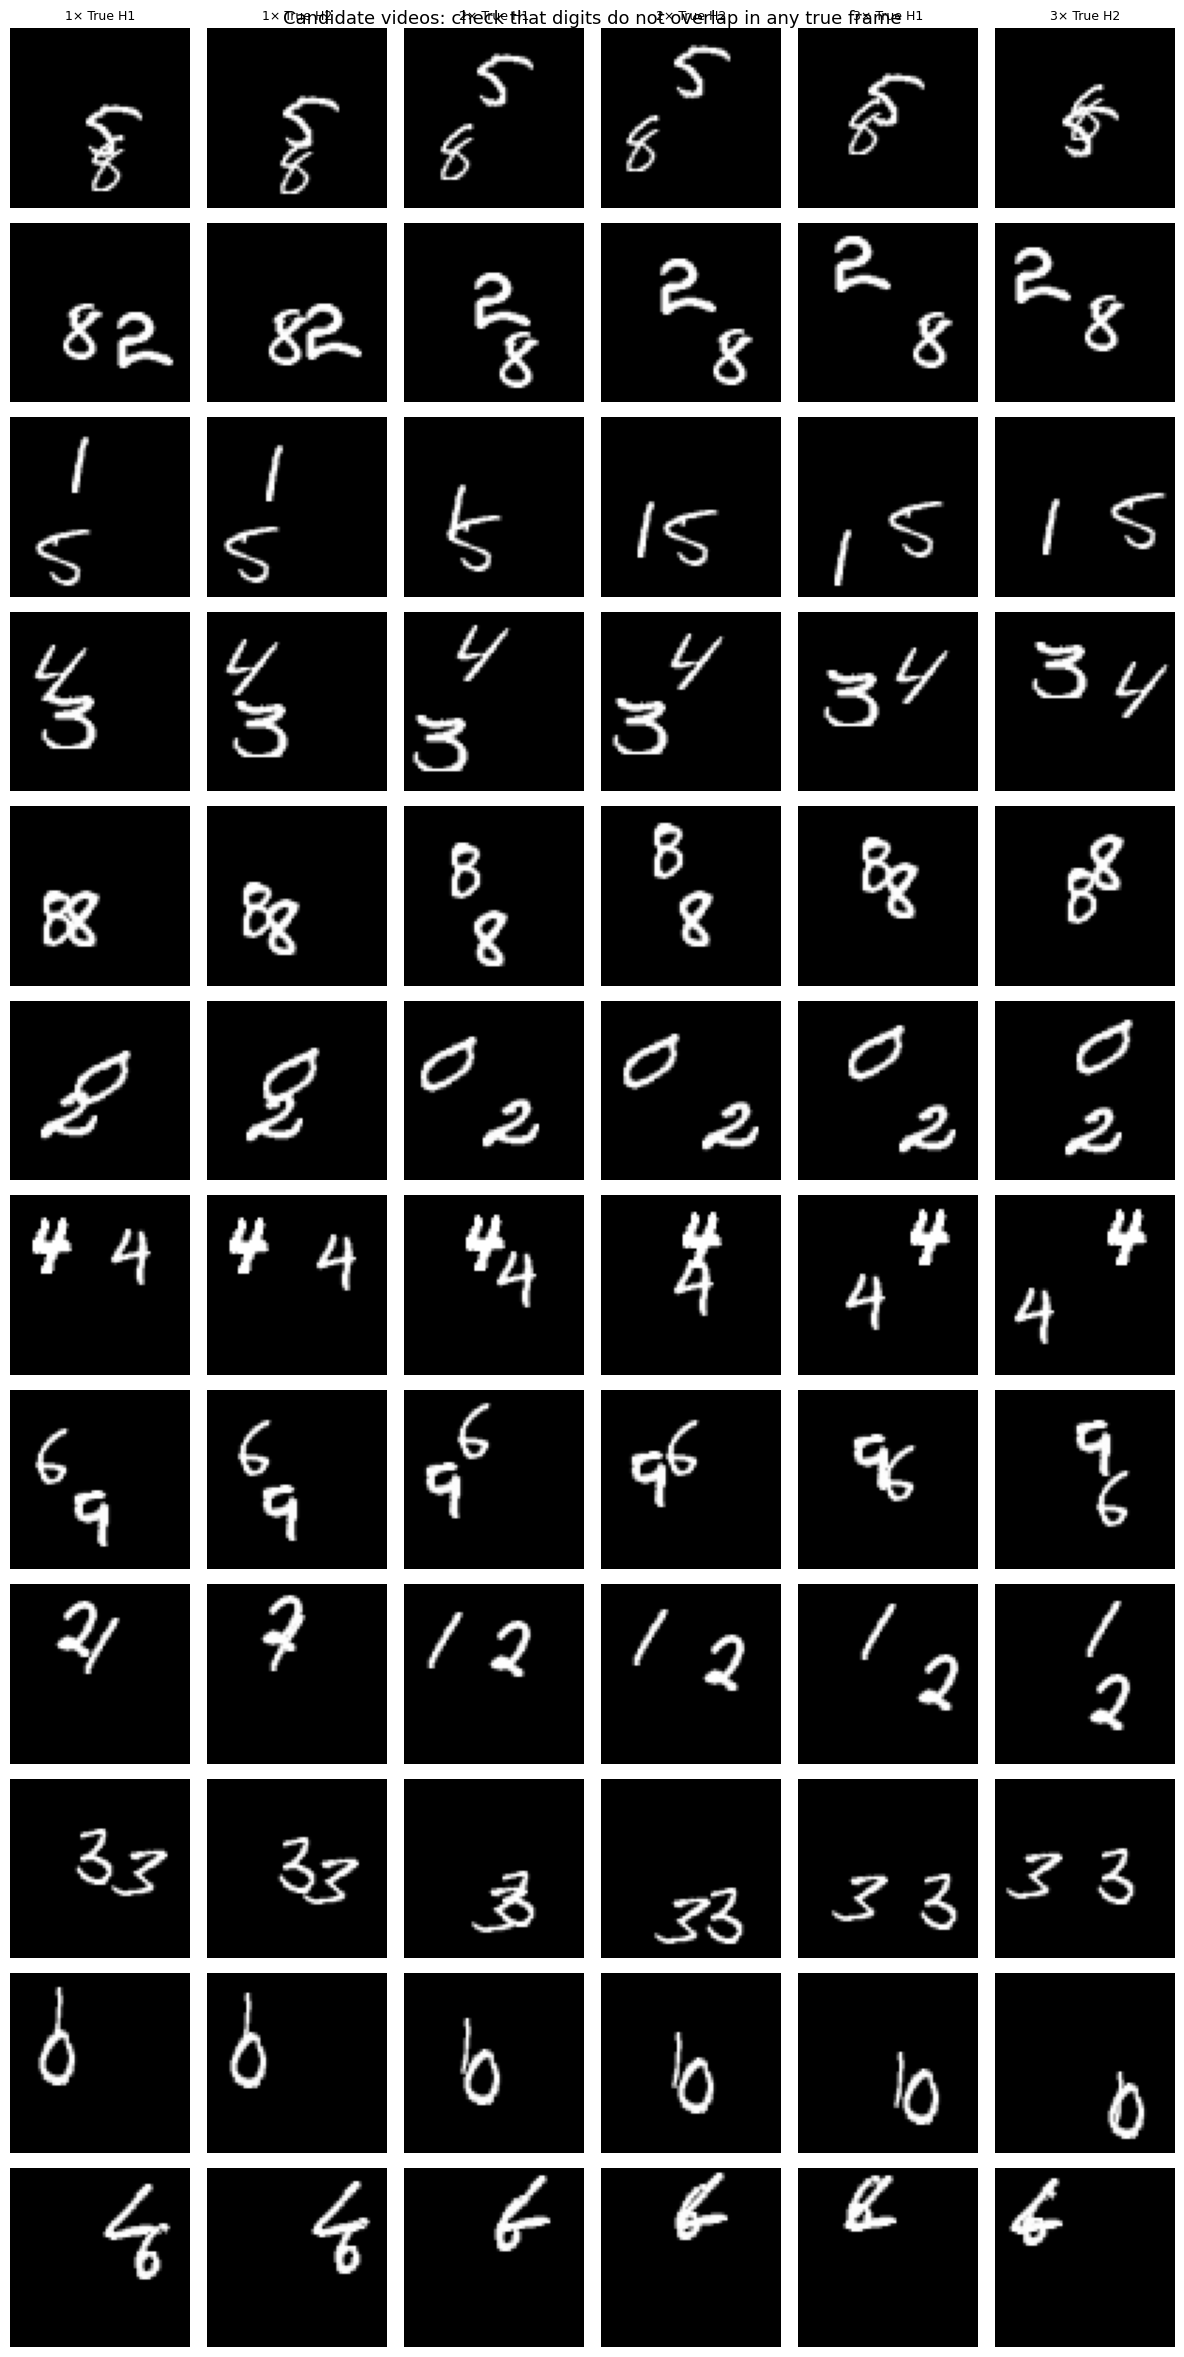

In [159]:

import matplotlib.pyplot as plt

candidate_indices = range(12)

fig, axes = plt.subplots(
    len(candidate_indices), 6,
    figsize=(12, 2 * len(candidate_indices))
)

column_labels = [
    "1× True H1", "1× True H2",
    "2× True H1", "2× True H2",
    "3× True H1", "3× True H2"
]

for row, idx in enumerate(candidate_indices):
    video = test_videos[idx]
    col = 0

    for speed in (1, 2, 3):
        _, Y = make_window(video, t=1, speed=speed)

        for horizon in (0, 1):
            axes[row, col].imshow(
                Y[horizon, 0].cpu().numpy(),
                cmap="gray", vmin=0, vmax=1
            )
            axes[row, col].axis("off")

            if row == 0:
                axes[row, col].set_title(
                    column_labels[col], fontsize=9
                )

            col += 1

    axes[row, 0].set_ylabel(
        f"Index {idx}", rotation=0, labelpad=35, fontsize=9
    )

fig.suptitle(
    "Candidate videos: check that digits do not overlap in any true frame",
    fontsize=13
)
fig.tight_layout()
plt.show()


In [160]:

def symmetrized_model_d_rollout(model, inputs, batch_size=32):
    """
    Symmetrised Model D forecaster.

    inputs: (N, 5, 1, 64, 64)
    returns: (N, 5, 1, 64, 64)
    """
    device = next(model.parameters()).device
    model.eval()

    predictions_sum = None

    with torch.no_grad():
        for a in range(4):
            for mirrored in (False, True):
                transformed_inputs = apply_symmetry(
                    inputs, a=a, mirrored=mirrored
                )

                transformed_batches = []

                for start in range(0, len(inputs), batch_size):
                    batch = transformed_inputs[
                        start:start + batch_size
                    ].to(device)

                    predictions = model_d_rollout(model, batch)
                    transformed_batches.append(predictions.cpu())

                transformed_predictions = torch.cat(
                    transformed_batches, dim=0
                )

                aligned_predictions = inverse_symmetry(
                    transformed_predictions,
                    a=a,
                    mirrored=mirrored
                )

                if predictions_sum is None:
                    predictions_sum = aligned_predictions
                else:
                    predictions_sum += aligned_predictions

    return predictions_sum / 8.0


print("Symmetrised Model D function defined successfully.")


Symmetrised Model D function defined successfully.


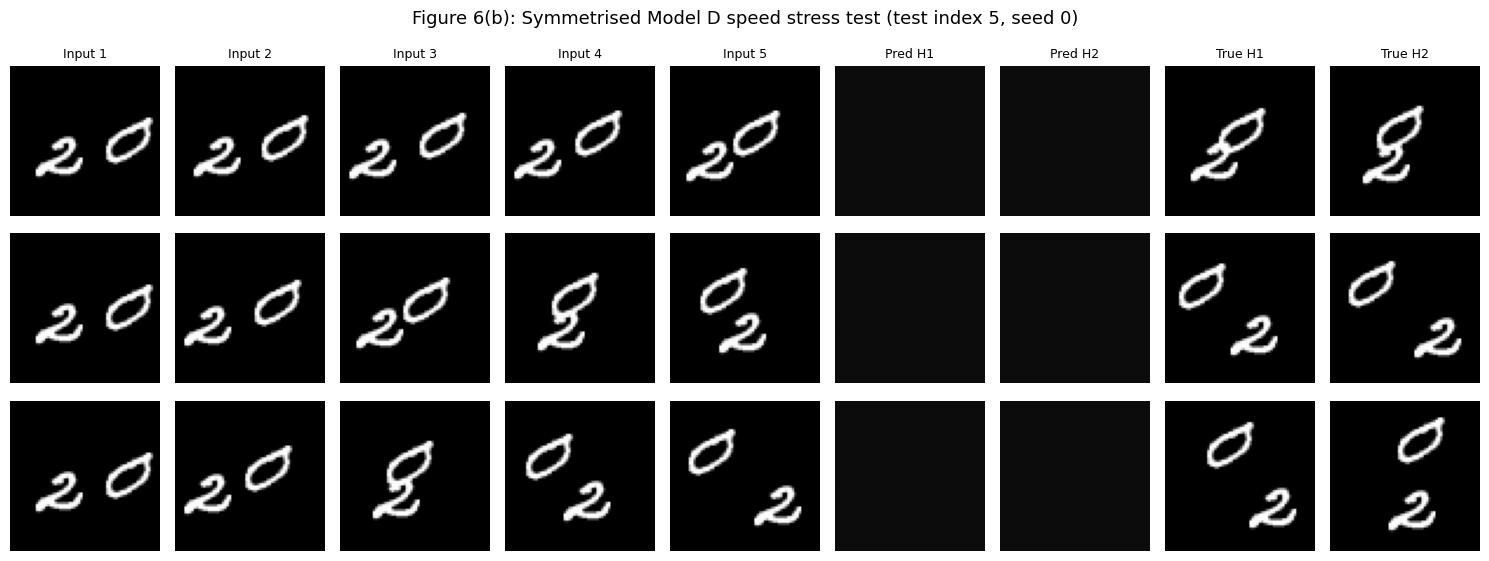

Saved: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6b_speed_stress_test.png


In [161]:

import matplotlib.pyplot as plt
from pathlib import Path
import torch

figure6_test_index = 5
video = test_videos[figure6_test_index]
model = model_d_seed0
model.eval()

speeds = [1, 2, 3]
figure6_results = {}

for speed in speeds:
    X, Y = make_window(video, t=1, speed=speed)

    predictions = symmetrized_model_d_rollout(
        model,
        X.unsqueeze(0),
        batch_size=1
    )[0]

    figure6_results[speed] = {
        "X": X.cpu(),
        "Y": Y.cpu(),
        "predictions": predictions.cpu()
    }

fig, axes = plt.subplots(
    3, 9,
    figsize=(15, 5.8),
    squeeze=False
)

column_titles = [
    "Input 1", "Input 2", "Input 3", "Input 4", "Input 5",
    "Pred H1", "Pred H2", "True H1", "True H2"
]

for row, speed in enumerate(speeds):
    result = figure6_results[speed]
    X = result["X"]
    Y = result["Y"]
    predictions = result["predictions"]

    frames = [
        X[i, 0].numpy() for i in range(5)
    ] + [
        predictions[i, 0].numpy() for i in range(2)
    ] + [
        Y[i, 0].numpy() for i in range(2)
    ]

    for col, frame in enumerate(frames):
        axes[row, col].imshow(
            frame, cmap="gray", vmin=0, vmax=1
        )
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                column_titles[col], fontsize=9
            )

    axes[row, 0].set_ylabel(
        f"{speed}× speed",
        fontsize=11,
        rotation=90,
        labelpad=10
    )

fig.suptitle(
    "Figure 6(b): Symmetrised Model D speed stress test "
    f"(test index {figure6_test_index}, seed 0)",
    fontsize=13
)
fig.tight_layout()

figure6b_path = Path("figures") / "Figure6b_speed_stress_test.png"
figure6b_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure6b_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", figure6b_path.resolve())


In [182]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch

# Figure 6(a): same four cases as Figure 3, using symmetrised Model D.
figure6_cases = [
    {"transform": "Mirror", "index": 269},
    {"transform": "Mirror", "index": 691},
    {"transform": "Rotation", "index": 982},
    {"transform": "Rotation", "index": 269},
]

# Use Model D, seed 0, wrapped in the 8-transformation average.
model = model_d_seed0
model.eval()

figure6_dir = Path("figures/Figure6")
figure6_dir.mkdir(parents=True, exist_ok=True)

def frame_to_numpy(frame):
    return frame.detach().cpu().squeeze().numpy()

def render_figure6a_case(case, save_png=True, save_gif=True):
    transform_name = case["transform"]
    idx = case["index"]
    transform_args = transforms[transform_name]

    X = test_inputs[idx:idx + 1]
    Y = test_targets[idx:idx + 1]

    # Apply the selected transformation consistently to every frame.
    TX = apply_symmetry(X, **transform_args)
    TY = apply_symmetry(Y, **transform_args)

    # Predictions from the symmetrised Model D.
    with torch.no_grad():
        pred_X = symmetrized_model_d_rollout(
            model, X, batch_size=32
        ).cpu()
        pred_TX = symmetrized_model_d_rollout(
            model, TX, batch_size=32
        ).cpu()

    T_pred_X = apply_symmetry(pred_X, **transform_args)

    # Measure the consistency gap for this example.
    # Invert the transformation on f(T(X)) before comparing with f(X).
    aligned_pred_TX = inverse_symmetry(
        pred_TX, **transform_args
    )
    consistency_gap = (
        (pred_X - aligned_pred_TX) ** 2
    ).mean().item()

    # Same four rows and ten columns as Figure 3.
    row_inputs = [X, TX, TX, TX]
    row_futures = [pred_X, TY, pred_TX, T_pred_X]
    row_labels = [
        "X / f(X)",
        "T(X) / T(Y)",
        "T(X) / f(T(X))",
        "T(X) / T(f(X))",
    ]

    def make_frame(horizon=None):
        fig, axes = plt.subplots(4, 10, figsize=(15, 6.4))

        for row in range(4):
            # Five input/history frames.
            for col in range(5):
                axes[row, col].imshow(
                    frame_to_numpy(row_inputs[row][0, col]),
                    cmap="gray", vmin=0, vmax=1
                )
                axes[row, col].axis("off")

            # Five future frames, or the selected horizon for a GIF frame.
            for col in range(5):
                if horizon is None:
                    future_frame = row_futures[row][0, col]
                    title = f"H{col + 1}"
                else:
                    future_frame = row_futures[row][0, horizon]
                    title = f"H{horizon + 1}"

                axes[row, col + 5].imshow(
                    frame_to_numpy(future_frame),
                    cmap="gray", vmin=0, vmax=1
                )
                axes[row, col + 5].axis("off")
                axes[row, col + 5].set_title(title, fontsize=8)

            axes[row, 0].set_ylabel(
                row_labels[row],
                fontsize=9,
                rotation=0,
                labelpad=50,
                va="center"
            )

        fig.suptitle(
            f"Figure 6(a) — Symmetrised Model D, {transform_name}, "
            f"test index {idx}, consistency gap {consistency_gap:.6g}",
            fontsize=11
        )
        fig.tight_layout(rect=[0.06, 0, 1, 0.95])

        fig.canvas.draw()
        image_array = np.asarray(
            fig.canvas.buffer_rgba()
        )[..., :3].copy()
        pil_image = Image.fromarray(image_array)
        plt.close(fig)
        return pil_image

    safe_name = f"sym_d_seed1_{transform_name.lower()}_test_{idx}"

    if save_png:
        png_path = figure6_dir / f"{safe_name}.png"
        make_frame().save(png_path)
        print("Saved PNG:", png_path.resolve())

    if save_gif:
        gif_frames = [make_frame(h) for h in range(5)]
        gif_path = figure6_dir / f"{safe_name}.gif"
        gif_frames[0].save(
            gif_path,
            save_all=True,
            append_images=gif_frames[1:],
            duration=700,
            loop=0
        )
        print("Saved GIF:", gif_path.resolve())

    print(f"{transform_name}, index {idx}: "
          f"consistency gap = {consistency_gap:.6g}")

for case in figure6_cases:
    render_figure6a_case(case)

print("\nFigure 6(a) panels and GIFs generated.")


Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_269.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_269.gif
Mirror, index 269: consistency gap = 5.54298e-18
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_691.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_691.gif
Mirror, index 691: consistency gap = 5.64937e-18
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test_982.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test_982.gif
Rotation, index 982: consistency gap = 7.11914e-18
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test

In [165]:

from pathlib import Path
import torch

models_b = {}

for seed in (0, 1):
    checkpoint_path = Path(f"model_b_seed_{seed}") / "latest_checkpoint.pt"
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model = ModelA().to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    models_b[seed] = model

    print(f"Loaded Model B seed {seed}: {checkpoint_path}")

print("Model B checkpoints loaded successfully.")


Loaded Model B seed 0: model_b_seed_0\latest_checkpoint.pt
Loaded Model B seed 1: model_b_seed_1\latest_checkpoint.pt
Model B checkpoints loaded successfully.


In [166]:

import torch
import numpy as np

def symmetrized_rollout_generic(model, inputs, rollout_fn, batch_size=32):
    """Average predictions over all 8 rotations/reflections."""
    model.eval()
    device = next(model.parameters()).device
    prediction_sum = None

    with torch.no_grad():
        for a in range(4):
            for mirrored in (False, True):
                transformed_inputs = apply_symmetry(
                    inputs, a=a, mirrored=mirrored
                )
                batches = []

                for start in range(0, len(inputs), batch_size):
                    batch = transformed_inputs[
                        start:start + batch_size
                    ].to(device)
                    batches.append(rollout_fn(model, batch).cpu())

                transformed_predictions = torch.cat(batches, dim=0)
                aligned = inverse_symmetry(
                    transformed_predictions, a=a, mirrored=mirrored
                )

                if prediction_sum is None:
                    prediction_sum = aligned
                else:
                    prediction_sum += aligned

    return prediction_sum / 8.0


def evaluate_symmetrized_model(model, rollout_fn, batch_size=32):
    """Evaluate on all 1,000 test videos at the original 1x speed."""
    X = test_inputs
    Y = test_targets

    pred = symmetrized_rollout_generic(
        model, X, rollout_fn, batch_size=batch_size
    )

    horizon_mse = ((pred - Y) ** 2).mean(dim=(0, 2, 3, 4))
    e5 = horizon_mse.mean().item()

    transform_results = {}

    for name, a, mirrored in [
        ("Mirror", 0, True),
        ("Rotation", 1, False),
    ]:
        TX = apply_symmetry(X, a=a, mirrored=mirrored)
        TY = apply_symmetry(Y, a=a, mirrored=mirrored)

        pred_TX = symmetrized_rollout_generic(
            model, TX, rollout_fn, batch_size=batch_size
        )

        # Compare f(T(X)) with T(f(X)).
        T_pred = apply_symmetry(pred, a=a, mirrored=mirrored)
        consistency = ((pred_TX - T_pred) ** 2).mean().item()
        transformed_error = ((pred_TX - TY) ** 2).mean().item()

        transform_results[name] = {
            "consistency": consistency,
            "transformed_error": transformed_error,
        }

    return {
        "horizon_mse": horizon_mse.tolist(),
        "E5": e5,
        "CM": transform_results["Mirror"]["consistency"],
        "EM": transform_results["Mirror"]["transformed_error"],
        "CR": transform_results["Rotation"]["consistency"],
        "ER": transform_results["Rotation"]["transformed_error"],
    }


# Evaluate both seeds. Model B and Model D use different rollout functions.
table6_results = {}

for model_name, model_dict, rollout_fn in [
    ("Symmetrised B", models_b, model_a_rollout),
    ("Symmetrised D", models_d, model_d_rollout),
]:
    table6_results[model_name] = {}

    for seed in (0, 1):
        print(f"Evaluating {model_name}, seed {seed}...")
        table6_results[model_name][seed] = evaluate_symmetrized_model(
            model_dict[seed], rollout_fn, batch_size=32
        )

# Display both seeds and their mean for each reported metric.
metric_names = ["E5", "CM", "EM", "CR", "ER"]

for model_name, seed_results in table6_results.items():
    print(f"\n{model_name}")
    for seed in (0, 1):
        r = seed_results[seed]
        print(
            f"Seed {seed}: "
            + ", ".join(f"{m}={r[m]:.8g}" for m in metric_names)
        )

    print("Mean over seeds:")
    for metric in metric_names:
        mean_value = np.mean([
            seed_results[seed][metric] for seed in (0, 1)
        ])
        print(f"  {metric}: {mean_value:.8g}")


Evaluating Symmetrised B, seed 0...
Evaluating Symmetrised B, seed 1...
Evaluating Symmetrised D, seed 0...
Evaluating Symmetrised D, seed 1...

Symmetrised B
Seed 0: E5=0.021554867, CM=8.6638593e-17, EM=0.021554859, CR=8.55093e-17, ER=0.021554859
Seed 1: E5=0.021551175, CM=8.8915543e-17, EM=0.021551175, CR=8.8084584e-17, ER=0.021551175
Mean over seeds:
  E5: 0.021553021
  CM: 8.7777068e-17
  EM: 0.021553017
  CR: 8.6796942e-17
  ER: 0.021553017

Symmetrised D
Seed 0: E5=0.040136579, CM=9.9797017e-18, EM=0.040136583, CR=8.3167047e-18, ER=0.040136583
Seed 1: E5=0.025041651, CM=6.6776187e-17, EM=0.025041647, CR=6.6948233e-17, ER=0.025041647
Mean over seeds:
  E5: 0.032589115
  CM: 3.8377944e-17
  EM: 0.032589115
  CR: 3.7632469e-17
  ER: 0.032589115


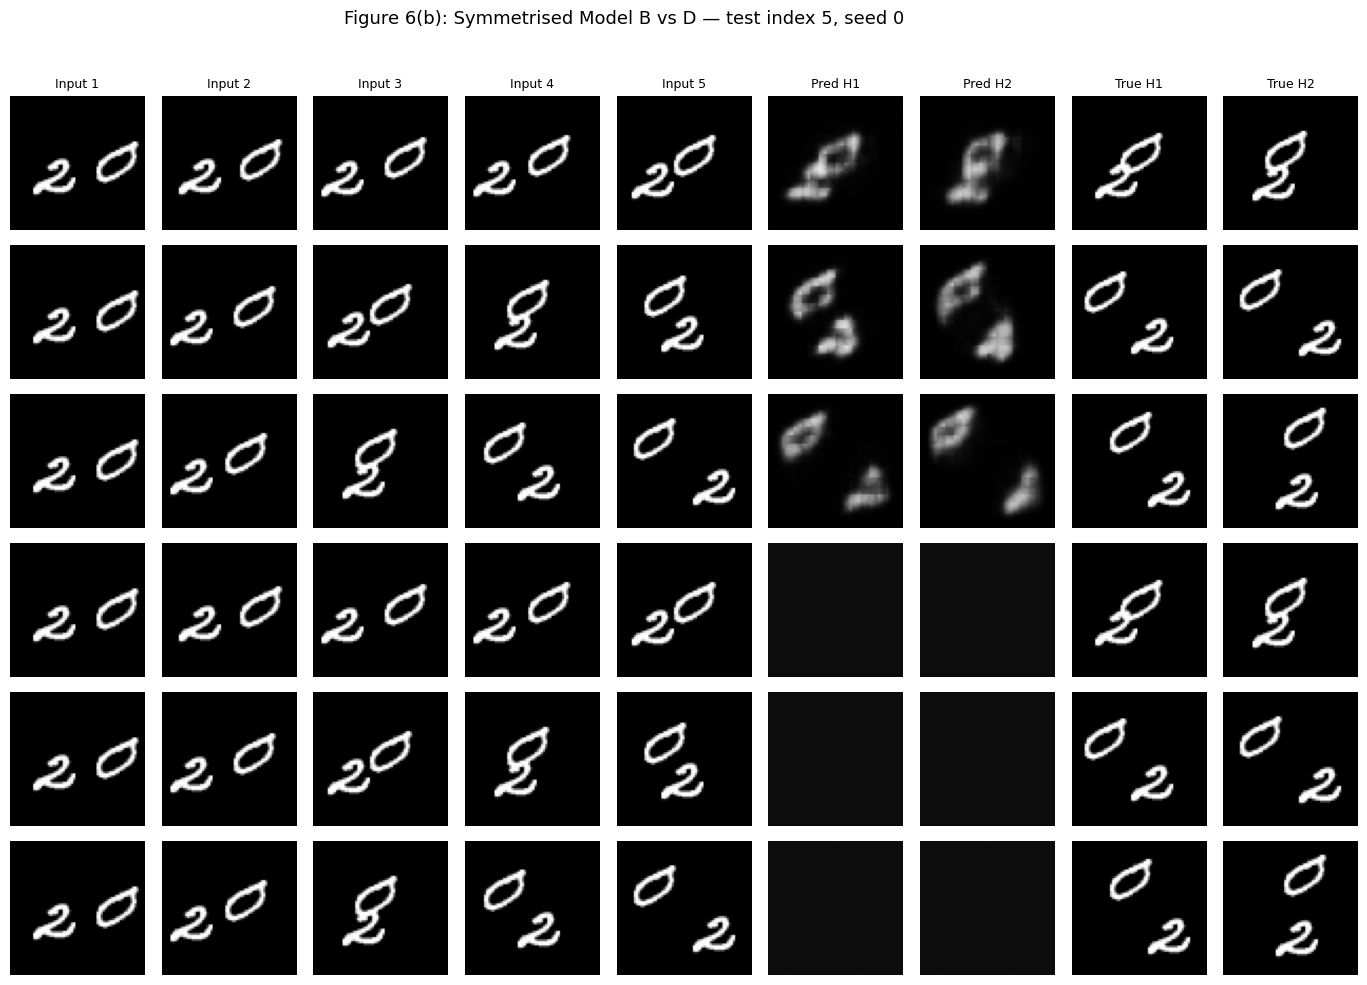

Saved: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\Figure6b_B_vs_D.png


In [167]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import torch

# Figure 6(b): compare symmetrised B and D on the same speed-stress video.
figure6b_index = 5
video = test_videos[figure6b_index]
speeds = [1, 2, 3]

models_to_compare = [
    ("Symmetrised B", models_b[0], model_a_rollout),
    ("Symmetrised D", models_d[0], model_d_rollout),
]

# Calculate the forecasts for each model and speed.
figure6b_results = {}

for model_name, model, rollout_fn in models_to_compare:
    figure6b_results[model_name] = {}

    for speed in speeds:
        X, Y = make_window(video, t=1, speed=speed)

        predictions = symmetrized_rollout_generic(
            model,
            X.unsqueeze(0),
            rollout_fn,
            batch_size=1
        )[0]

        figure6b_results[model_name][speed] = {
            "X": X.cpu(),
            "Y": Y.cpu(),
            "predictions": predictions.cpu(),
        }

# Show inputs, predictions H1/H2, and true H1/H2.
column_titles = [
    "Input 1", "Input 2", "Input 3", "Input 4", "Input 5",
    "Pred H1", "Pred H2", "True H1", "True H2"
]

fig, axes = plt.subplots(
    6, 9, figsize=(15, 10), squeeze=False
)

row = 0
for model_name, _, _ in models_to_compare:
    for speed in speeds:
        result = figure6b_results[model_name][speed]
        X = result["X"]
        Y = result["Y"]
        predictions = result["predictions"]

        frames = (
            [X[i, 0].numpy() for i in range(5)]
            + [predictions[i, 0].numpy() for i in range(2)]
            + [Y[i, 0].numpy() for i in range(2)]
        )

        for col, frame in enumerate(frames):
            axes[row, col].imshow(
                frame, cmap="gray", vmin=0, vmax=1
            )
            axes[row, col].axis("off")

            if row == 0:
                axes[row, col].set_title(
                    column_titles[col], fontsize=9
                )

        axes[row, 0].set_ylabel(
            f"{model_name}\n{speed}× speed",
            fontsize=9,
            rotation=0,
            labelpad=65,
            va="center"
        )
        row += 1

fig.suptitle(
    f"Figure 6(b): Symmetrised Model B vs D — "
    f"test index {figure6b_index}, seed 0",
    fontsize=13
)
fig.tight_layout(rect=[0.08, 0, 1, 0.96])

figure6b_path = Path("figures/Figure6/Figure6b_B_vs_D.png")
figure6b_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure6b_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", figure6b_path.resolve())


Saved final Figure 6(a): final_sym_b_mirror_test_269
Saved final Figure 6(a): final_sym_b_mirror_test_691
Saved final Figure 6(a): final_sym_b_rotation_test_982
Saved final Figure 6(a): final_sym_b_rotation_test_269


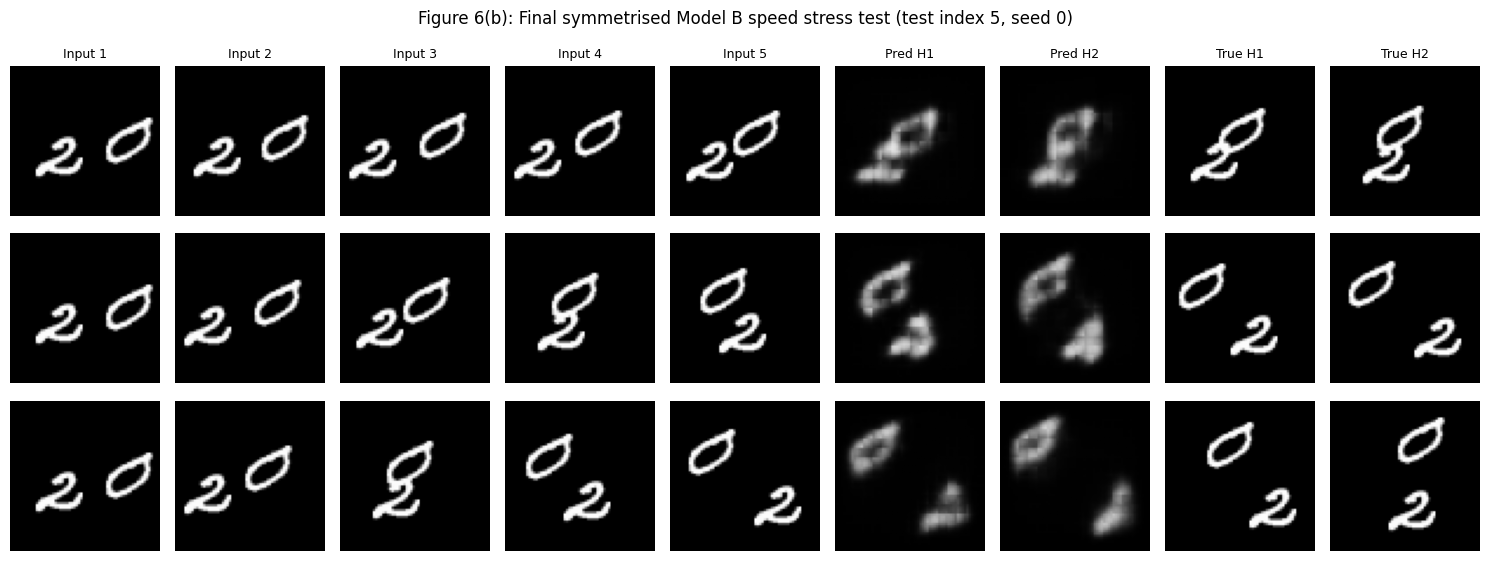

Saved final Figure 6(b): C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\Figure6b_final_symmetrised_B.png


In [168]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch

final_model = models_b[0]
final_model.eval()
final_dir = Path("figures/Figure6")
final_dir.mkdir(parents=True, exist_ok=True)

def final_sym_b_rollout(inputs):
    return symmetrized_rollout_generic(
        final_model, inputs, model_a_rollout, batch_size=32
    )

def frame_np(x):
    return x.detach().cpu().squeeze().numpy()

# Figure 6(a): repeat Figure 3 with the selected final model, Model B.
final_cases = [
    ("Mirror", 269),
    ("Mirror", 691),
    ("Rotation", 982),
    ("Rotation", 269),
]

for transform_name, idx in final_cases:
    args = transforms[transform_name]
    X = test_inputs[idx:idx + 1]
    Y = test_targets[idx:idx + 1]
    TX = apply_symmetry(X, **args)
    TY = apply_symmetry(Y, **args)

    with torch.no_grad():
        pred_X = final_sym_b_rollout(X).cpu()
        pred_TX = final_sym_b_rollout(TX).cpu()

    T_pred_X = apply_symmetry(pred_X, **args)
    rows_in = [X, TX, TX, TX]
    rows_future = [pred_X, TY, pred_TX, T_pred_X]
    labels = ["X / f(X)", "T(X) / T(Y)",
              "T(X) / f(T(X))", "T(X) / T(f(X))"]

    gap = (
        pred_TX - apply_symmetry(pred_X, **args)
    ).square().mean().item()

    def make_final_frame(h=None):
        fig, ax = plt.subplots(4, 10, figsize=(15, 6.4))
        for r in range(4):
            for c in range(5):
                ax[r, c].imshow(
                    frame_np(rows_in[r][0, c]),
                    cmap="gray", vmin=0, vmax=1
                )
                ax[r, c].axis("off")

            for c in range(5):
                horizon = c if h is None else h
                ax[r, c + 5].imshow(
                    frame_np(rows_future[r][0, horizon]),
                    cmap="gray", vmin=0, vmax=1
                )
                ax[r, c + 5].axis("off")
                ax[r, c + 5].set_title(f"H{horizon + 1}", fontsize=8)

            ax[r, 0].set_ylabel(
                labels[r], fontsize=9, rotation=0,
                labelpad=50, va="center"
            )

        fig.suptitle(
            f"Figure 6(a) — Symmetrised Model B, {transform_name}, "
            f"test index {idx}, consistency gap {gap:.3g}",
            fontsize=11
        )
        fig.tight_layout(rect=[0.06, 0, 1, 0.95])
        fig.canvas.draw()
        arr = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
        plt.close(fig)
        return Image.fromarray(arr)

    stem = f"final_sym_b_{transform_name.lower()}_test_{idx}"
    make_final_frame().save(final_dir / f"{stem}.png")

    gif_frames = [make_final_frame(h) for h in range(5)]
    gif_frames[0].save(
        final_dir / f"{stem}.gif",
        save_all=True, append_images=gif_frames[1:],
        duration=700, loop=0
    )
    print("Saved final Figure 6(a):", stem)

# Figure 6(b): repeat Figure 5 using the final symmetrised Model B.
idx = 5
video = test_videos[idx]
speeds = [1, 2, 3]
fig, axes = plt.subplots(3, 9, figsize=(15, 5.8), squeeze=False)

titles = [
    "Input 1", "Input 2", "Input 3", "Input 4", "Input 5",
    "Pred H1", "Pred H2", "True H1", "True H2"
]

for r, speed in enumerate(speeds):
    X, Y = make_window(video, t=1, speed=speed)
    with torch.no_grad():
        pred = final_sym_b_rollout(X.unsqueeze(0)).cpu()[0]

    frames = (
        [X[i, 0].numpy() for i in range(5)]
        + [pred[i, 0].numpy() for i in range(2)]
        + [Y[i, 0].numpy() for i in range(2)]
    )

    for c, frame in enumerate(frames):
        axes[r, c].imshow(frame, cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(titles[c], fontsize=9)

    axes[r, 0].set_ylabel(
        f"{speed}× speed", fontsize=10,
        rotation=90, labelpad=10
    )

fig.suptitle(
    f"Figure 6(b): Final symmetrised Model B speed stress test "
    f"(test index {idx}, seed 0)",
    fontsize=12
)
fig.tight_layout()
path = final_dir / "Figure6b_final_symmetrised_B.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved final Figure 6(b):", path.resolve())


In [169]:
from pathlib import Path

figure6_dir = Path("figures/Figure6")

required_files = [
    "final_sym_b_mirror_test_269.png",
    "final_sym_b_mirror_test_269.gif",
    "Figure6b_final_symmetrised_B.png",
]

for filename in required_files:
    path = figure6_dir / filename
    if path.exists():
        print(f"[OK] {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

[OK] final_sym_b_mirror_test_269.png (142,099 bytes)
[OK] final_sym_b_mirror_test_269.gif (354,185 bytes)
[OK] Figure6b_final_symmetrised_B.png (133,588 bytes)


In [171]:
from pathlib import Path

root = Path.cwd()

required = [
    "Figure1_motion_statistics.png",
    "figures/Figure2_model_A_predictions.png",
    "figures/Figure3/mirror_test_269.png",
    "figures/Figure3/mirror_test_691.png",
    "figures/Figure3/rotation_test_269.png",
    "figures/Figure3/rotation_test_982.png",
    "figures/Figure4/Figure4a_mirror_histogram.png",
    "figures/Figure4/Figure4b_rotation_histogram.png",
    "figures/Figure5_speed_stress_test.png",
    "figures/Figure6/Figure6b_final_symmetrised_B.png",
]

print("FIGURE CHECK")
for name in required:
    path = root / name
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}")

print("\nREPORT / TABLE FILES")
for pattern in ("*.md", "*.pdf", "*.docx", "*.csv", "*.xlsx"):
    matches = list(root.glob(pattern))
    for path in matches:
        print(f"[FILE] {path.name}")

FIGURE CHECK
[OK] Figure1_motion_statistics.png
[OK] figures/Figure2_model_A_predictions.png
[OK] figures/Figure3/mirror_test_269.png
[OK] figures/Figure3/mirror_test_691.png
[OK] figures/Figure3/rotation_test_269.png
[OK] figures/Figure3/rotation_test_982.png
[OK] figures/Figure4/Figure4a_mirror_histogram.png
[OK] figures/Figure4/Figure4b_rotation_histogram.png
[OK] figures/Figure5_speed_stress_test.png
[OK] figures/Figure6/Figure6b_final_symmetrised_B.png

REPORT / TABLE FILES


In [173]:
import json
from pathlib import Path

path = Path("Question2.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    outputs = cell.get("outputs", [])

    if source.strip() or outputs:
        preview = source.strip().replace("\n", " ")[:180]
        output_types = [
            out.get("output_type", "unknown")
            for out in outputs
        ]

        print(
            f"Cell {i:03d} | {cell['cell_type']:8s} | "
            f"outputs={len(outputs)} {output_types} | {preview}"
        )

Total cells: 124
Cell 000 | code     | outputs=1 ['stream'] | import sys  print("Python executable:", sys.executable) print("Python version:", sys.version)
Cell 001 | code     | outputs=1 ['stream'] | import torch import torchvision  print("PyTorch:", torch.__version__) print("Torchvision:", torchvision.__version__) print("CUDA available:", torch.cuda.is_available())  if torch.c
Cell 002 | code     | outputs=1 ['stream'] | from pathlib import Path import numpy as np  dataset_path = Path("data/MovingMNIST/mnist_test_seq.npy")  print("File exists:", dataset_path.exists())  if dataset_path.exists():    
Cell 003 | code     | outputs=1 ['stream'] | import torch import numpy as np  # Convert from (frames, videos, height, width) # to (videos, frames, channels, height, width) videos = np.load(dataset_path) videos = np.transpose(
Cell 004 | code     | outputs=0 [] | import torch  # -------------------------------------------------- # 1. Spatial transformations # Each video has shape (frames, c

In [175]:
import inspect

print("=== Model D structure ===")
print("Type:", type(models_d))

if isinstance(models_d, dict):
    for key, value in models_d.items():
        print(f"Key: {key!r} | Type: {type(value)}")
elif isinstance(models_d, (list, tuple)):
    print("Number of entries:", len(models_d))
    for i, value in enumerate(models_d):
        print(f"Entry {i} | Type: {type(value)}")

print("\n=== Symmetrised Model D function ===")
print(inspect.signature(symmetrized_model_d_rollout))
print(inspect.getsource(symmetrized_model_d_rollout))

print("\n=== Generic symmetrisation function ===")
print(inspect.signature(symmetrized_rollout_generic))

print("\n=== Test data shapes ===")
for name in ["test_inputs", "test_targets"]:
    value = globals().get(name)
    if value is not None:
        print(f"{name}: shape={getattr(value, 'shape', 'no shape')}, "
              f"type={type(value)}")

=== Model D structure ===
Type: <class 'dict'>
Key: 0 | Type: <class '__main__.ModelD'>
Key: 1 | Type: <class '__main__.ModelD'>

=== Symmetrised Model D function ===
(model, inputs, batch_size=32)
def symmetrized_model_d_rollout(model, inputs, batch_size=32):
    """
    Symmetrised Model D forecaster.

    inputs: (N, 5, 1, 64, 64)
    returns: (N, 5, 1, 64, 64)
    """
    device = next(model.parameters()).device
    model.eval()

    predictions_sum = None

    with torch.no_grad():
        for a in range(4):
            for mirrored in (False, True):
                transformed_inputs = apply_symmetry(
                    inputs, a=a, mirrored=mirrored
                )

                transformed_batches = []

                for start in range(0, len(inputs), batch_size):
                    batch = transformed_inputs[
                        start:start + batch_size
                    ].to(device)

                    predictions = model_d_rollout(model, batch)
              

In [176]:
print("=== Evaluation-related functions and variables ===")

keywords = (
    "metric", "evaluate", "eval_", "mse", "consistency",
    "symmetr", "mirror", "rotation", "transform", "error"
)

for name, obj in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if callable(obj):
            print(f"FUNCTION: {name}")
        elif any(word in name.lower() for word in (
            "metric", "result", "error", "mse", "consistency"
        )):
            if isinstance(obj, (dict, list, tuple)):
                print(f"DATA: {name} ({type(obj).__name__}, "
                      f"length={len(obj)})")
            else:
                print(f"DATA: {name} ({type(obj).__name__})")

=== Evaluation-related functions and variables ===
FUNCTION: apply_symmetry
DATA: baseline_transformation_results (dict, length=2)
FUNCTION: calculate_horizon_mse
DATA: consistency_gap (float)
FUNCTION: evaluate_baseline_transformations
FUNCTION: evaluate_copy_last_speed
FUNCTION: evaluate_model_a
FUNCTION: evaluate_speed_for_model_d
FUNCTION: evaluate_speed_for_seed
FUNCTION: evaluate_symmetrized_model
FUNCTION: evaluate_transformations_model_c
FUNCTION: evaluate_transformations_model_d
DATA: horizon_mse (Tensor)
FUNCTION: inverse_symmetry
DATA: mean_horizon_mse (list, length=5)
DATA: metric (str)
DATA: metric_names (list, length=5)
DATA: metrics (dict, length=2)
DATA: metrics_dict (dict, length=5)
FUNCTION: mirror
DATA: mirror_errors (ndarray)
DATA: mse (float)
DATA: per_video_consistency (dict, length=2)
FUNCTION: per_video_mse
FUNCTION: per_video_mse_masked
FUNCTION: plot_consistency_histogram
FUNCTION: predict_transformed_inputs
FUNCTION: randomly_transform_window
DATA: rotation_e

In [177]:
import inspect

for name in [
    "evaluate_symmetrized_model",
    "evaluate_transformations_model_d",
    "calculate_horizon_mse",
    "per_video_mse",
    "per_video_mse_masked",
]:
    func = globals().get(name)

    if callable(func):
        print(f"\n{'=' * 65}")
        print(f"FUNCTION: {name}{inspect.signature(func)}")
        print("=" * 65)
        print(inspect.getsource(func))


FUNCTION: evaluate_symmetrized_model(model, rollout_fn, batch_size=32)
def evaluate_symmetrized_model(model, rollout_fn, batch_size=32):
    """Evaluate on all 1,000 test videos at the original 1x speed."""
    X = test_inputs
    Y = test_targets

    pred = symmetrized_rollout_generic(
        model, X, rollout_fn, batch_size=batch_size
    )

    horizon_mse = ((pred - Y) ** 2).mean(dim=(0, 2, 3, 4))
    e5 = horizon_mse.mean().item()

    transform_results = {}

    for name, a, mirrored in [
        ("Mirror", 0, True),
        ("Rotation", 1, False),
    ]:
        TX = apply_symmetry(X, a=a, mirrored=mirrored)
        TY = apply_symmetry(Y, a=a, mirrored=mirrored)

        pred_TX = symmetrized_rollout_generic(
            model, TX, rollout_fn, batch_size=batch_size
        )

        # Compare f(T(X)) with T(f(X)).
        T_pred = apply_symmetry(pred, a=a, mirrored=mirrored)
        consistency = ((pred_TX - T_pred) ** 2).mean().item()
        transformed_error = ((pred_TX -

In [178]:
import time
import numpy as np

sym_d_results = {}

for seed in [0, 1]:
    print(f"\nEvaluating symmetrised Model D — seed {seed}...")
    start_time = time.time()

    result = evaluate_symmetrized_model(
        model=models_d[seed],
        rollout_fn=model_d_rollout,
        batch_size=32
    )

    sym_d_results[seed] = result

    print(f"Time: {time.time() - start_time:.1f} seconds")
    print("Horizon MSE:", [f"{x:.6f}" for x in result["horizon_mse"]])
    for metric in ["E5", "CM", "EM", "CR", "ER"]:
        print(f"{metric}: {result[metric]:.8f}")

print("\n=== Mean across seeds 0 and 1 ===")
for metric in ["E5", "CM", "EM", "CR", "ER"]:
    values = [sym_d_results[s][metric] for s in [0, 1]]
    print(f"{metric}: {np.mean(values):.8f}  "
          f"(seed 0: {values[0]:.8f}, seed 1: {values[1]:.8f})")


Evaluating symmetrised Model D — seed 0...
Time: 15.3 seconds
Horizon MSE: ['0.040178', '0.040141', '0.040148', '0.040109', '0.040107']
E5: 0.04013658
CM: 0.00000000
EM: 0.04013658
CR: 0.00000000
ER: 0.04013658

Evaluating symmetrised Model D — seed 1...
Time: 15.1 seconds
Horizon MSE: ['0.020667', '0.023691', '0.025516', '0.026986', '0.028349']
E5: 0.02504165
CM: 0.00000000
EM: 0.02504165
CR: 0.00000000
ER: 0.02504165

=== Mean across seeds 0 and 1 ===
E5: 0.03258912  (seed 0: 0.04013658, seed 1: 0.02504165)
CM: 0.00000000  (seed 0: 0.00000000, seed 1: 0.00000000)
EM: 0.03258912  (seed 0: 0.04013658, seed 1: 0.02504165)
CR: 0.00000000  (seed 0: 0.00000000, seed 1: 0.00000000)
ER: 0.03258912  (seed 0: 0.04013658, seed 1: 0.02504165)


In [179]:
[name for name in globals()
 if any(word in name.lower() for word in ["figure6", "plot_sym", "save_sym", "visualize_sym"])]

['figure6_test_index',
 'figure6_results',
 'figure6b_path',
 'figure6_cases',
 'figure6_dir',
 'render_figure6a_case',
 'figure6b_index',
 'figure6b_results']

In [180]:
import inspect

print(inspect.signature(render_figure6a_case))
print(inspect.getsource(render_figure6a_case))

(case, save_png=True, save_gif=True)
def render_figure6a_case(case, save_png=True, save_gif=True):
    transform_name = case["transform"]
    idx = case["index"]
    transform_args = transforms[transform_name]

    X = test_inputs[idx:idx + 1]
    Y = test_targets[idx:idx + 1]

    # Apply the selected transformation consistently to every frame.
    TX = apply_symmetry(X, **transform_args)
    TY = apply_symmetry(Y, **transform_args)

    # Predictions from the symmetrised Model D.
    with torch.no_grad():
        pred_X = symmetrized_model_d_rollout(
            model, X, batch_size=32
        ).cpu()
        pred_TX = symmetrized_model_d_rollout(
            model, TX, batch_size=32
        ).cpu()

    T_pred_X = apply_symmetry(pred_X, **transform_args)

    # Measure the consistency gap for this example.
    # Invert the transformation on f(T(X)) before comparing with f(X).
    aligned_pred_TX = inverse_symmetry(
        pred_TX, **transform_args
    )
    consistency_gap = (
    

In [181]:
print("Model D seeds:", list(models_d.keys()))
print("Figure 6 directory:", figure6_dir)

print("\nAvailable Figure 6 cases:")
for name in ["figure6a_cases", "figure6_cases", "cases"]:
    if name in globals():
        print(name, "=", globals()[name])

Model D seeds: [0, 1]
Figure 6 directory: figures\Figure6

Available Figure 6 cases:
figure6_cases = [{'transform': 'Mirror', 'index': 269}, {'transform': 'Mirror', 'index': 691}, {'transform': 'Rotation', 'index': 982}, {'transform': 'Rotation', 'index': 269}]


In [183]:
# Regenerate Figure 6(a) using Model D, seed 1.
# Save to new filenames so the original figures are preserved.

model = models_d[1]

for case in figure6_cases:
    render_figure6a_case(
        case,
        save_png=True,
        save_gif=True
    )

print("\nFinished regenerating Figure 6(a) with Model D, seed 1.")

Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_269.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_269.gif
Mirror, index 269: consistency gap = 1.18152e-16
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_691.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_mirror_test_691.gif
Mirror, index 691: consistency gap = 8.50268e-17
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test_982.png
Saved GIF: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test_982.gif
Rotation, index 982: consistency gap = 1.59394e-16
Saved PNG: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\figures\Figure6\sym_d_seed1_rotation_test

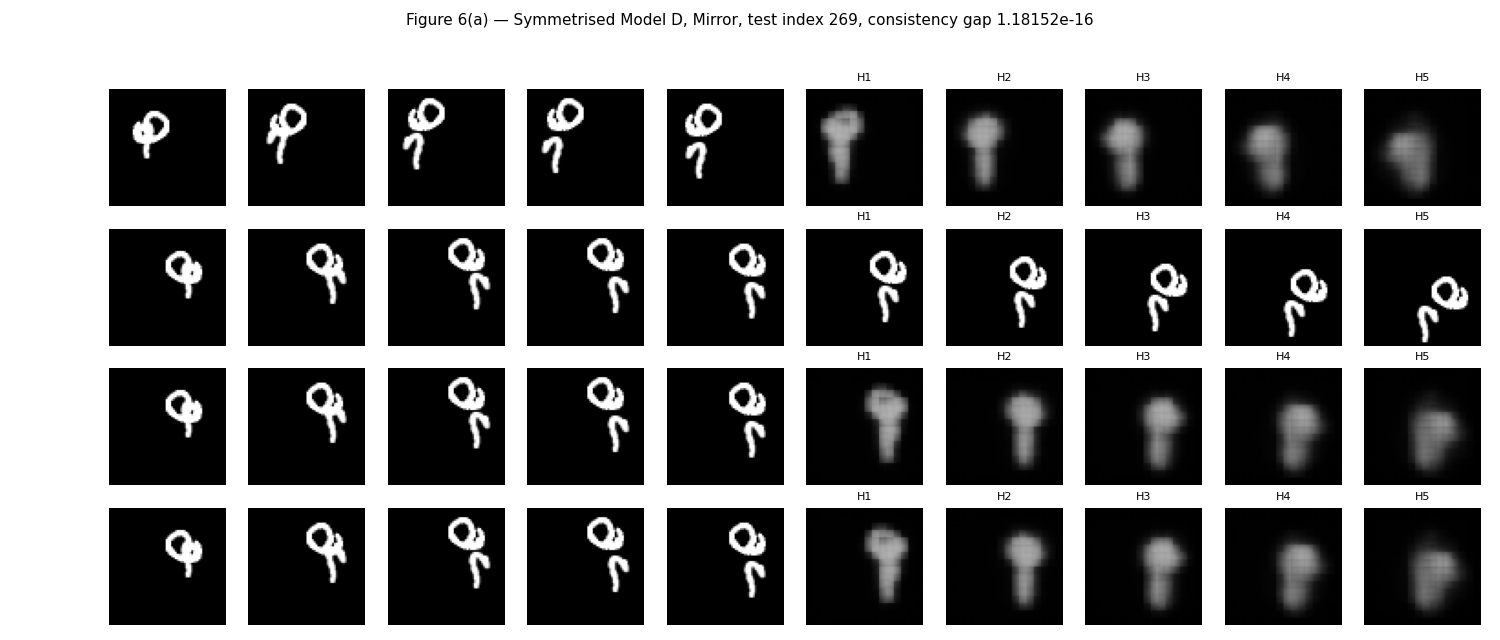

In [184]:
from IPython.display import display, Image

display(Image(filename=str(
    figure6_dir / "sym_d_seed1_mirror_test_269.png"
)))

In [185]:
import torch
import torch.nn as nn

# Change model_a if your Model A variable has a different name
model = model_a

# 1. Verify the trainable parameter count
parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", parameter_count)
assert parameter_count == 480_784, (
    f"Expected 480,784 parameters, got {parameter_count}"
)

# 2. Inspect the convolution layers
conv_layers = [
    (name, module)
    for name, module in model.named_modules()
    if isinstance(module, nn.Conv2d)
]

print("\nConvolution layers:")
for name, layer in conv_layers:
    print(
        f"{name}: kernel={layer.kernel_size}, "
        f"in_channels={layer.in_channels}, "
        f"out_channels={layer.out_channels}"
    )

# 3. Calculate the reach using the assignment's convention
patch_size = 4  # pixel_unshuffle(4): one folded-grid step = 4 pixels

spatial_convs = [
    layer for _, layer in conv_layers
    if layer.kernel_size != (1, 1)
]

assert len(spatial_convs) == 2, (
    "Expected two spatial 3x3 ConvLSTM convolutions. "
    "Check the printed architecture."
)
assert all(layer.kernel_size == (3, 3) for layer in spatial_convs)

# A 3x3 convolution reaches one neighbour in each direction:
# 1 folded-grid position = 4 original-image pixels.
reach_per_spatial_conv = (3 - 1) // 2 * patch_size

# Longest within-step path: ConvLSTM layer 1 -> ConvLSTM layer 2
reach = len(spatial_convs) * reach_per_spatial_conv

print("\nReach calculation:")
print(f"Folded-grid spacing: {patch_size} original-image pixels")
print(f"Reach per 3x3 convolution: {reach_per_spatial_conv} pixels")
print(f"Spatial convolutions on the longest path: {len(spatial_convs)}")
print(f"Model A reach: {reach} original-image pixels per time step")

assert reach == 8

Trainable parameters: 480784

Convolution layers:
convlstm1.gates: kernel=(3, 3), in_channels=80, out_channels=256
convlstm2.gates: kernel=(3, 3), in_channels=128, out_channels=256
output_conv: kernel=(1, 1), in_channels=64, out_channels=16

Reach calculation:
Folded-grid spacing: 4 original-image pixels
Reach per 3x3 convolution: 4 pixels
Spatial convolutions on the longest path: 2
Model A reach: 8 original-image pixels per time step



figures/Figure3/mirror_test_269.png


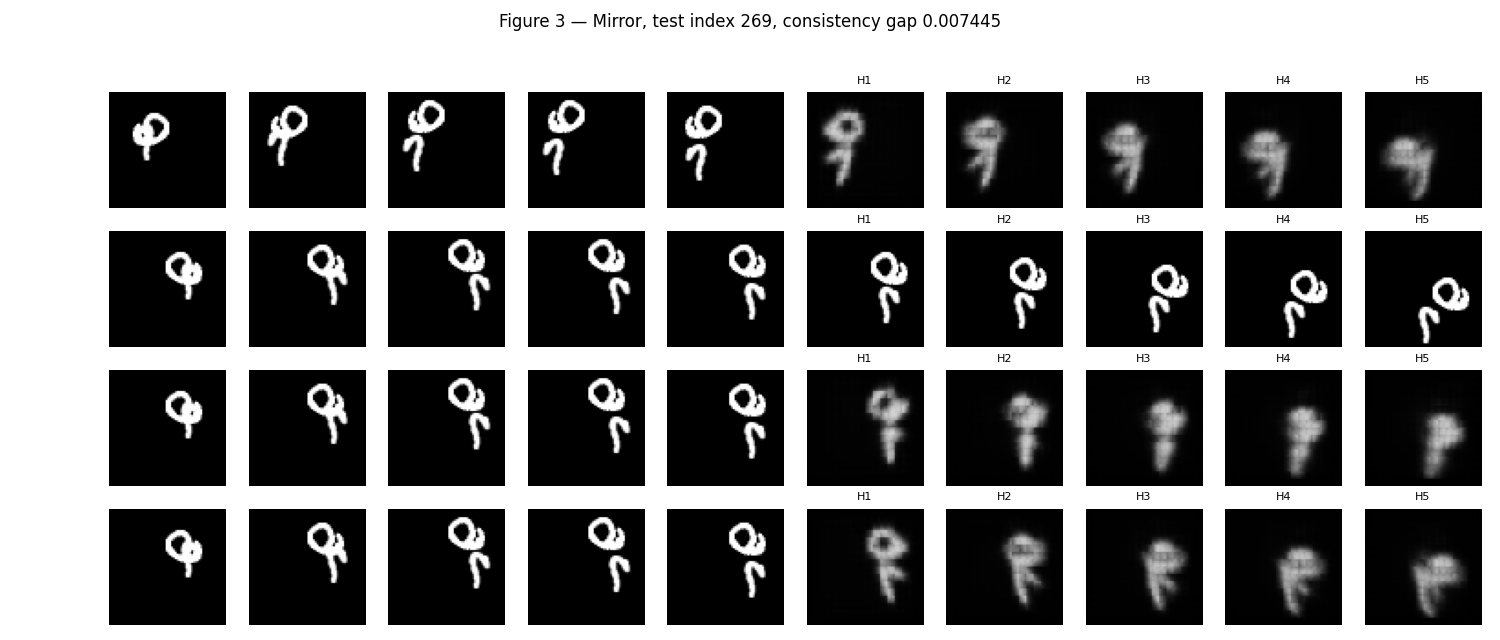


figures/Figure3/mirror_test_691.png


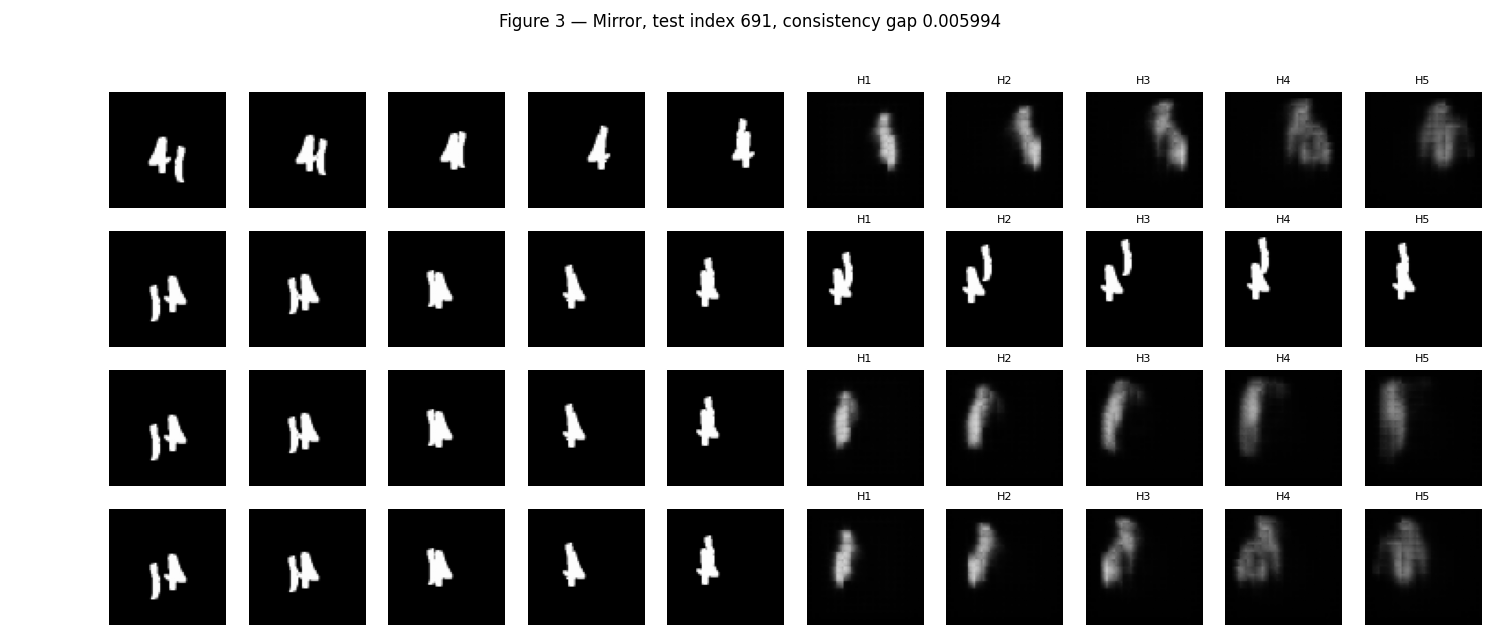


figures/Figure3/rotation_test_982.png


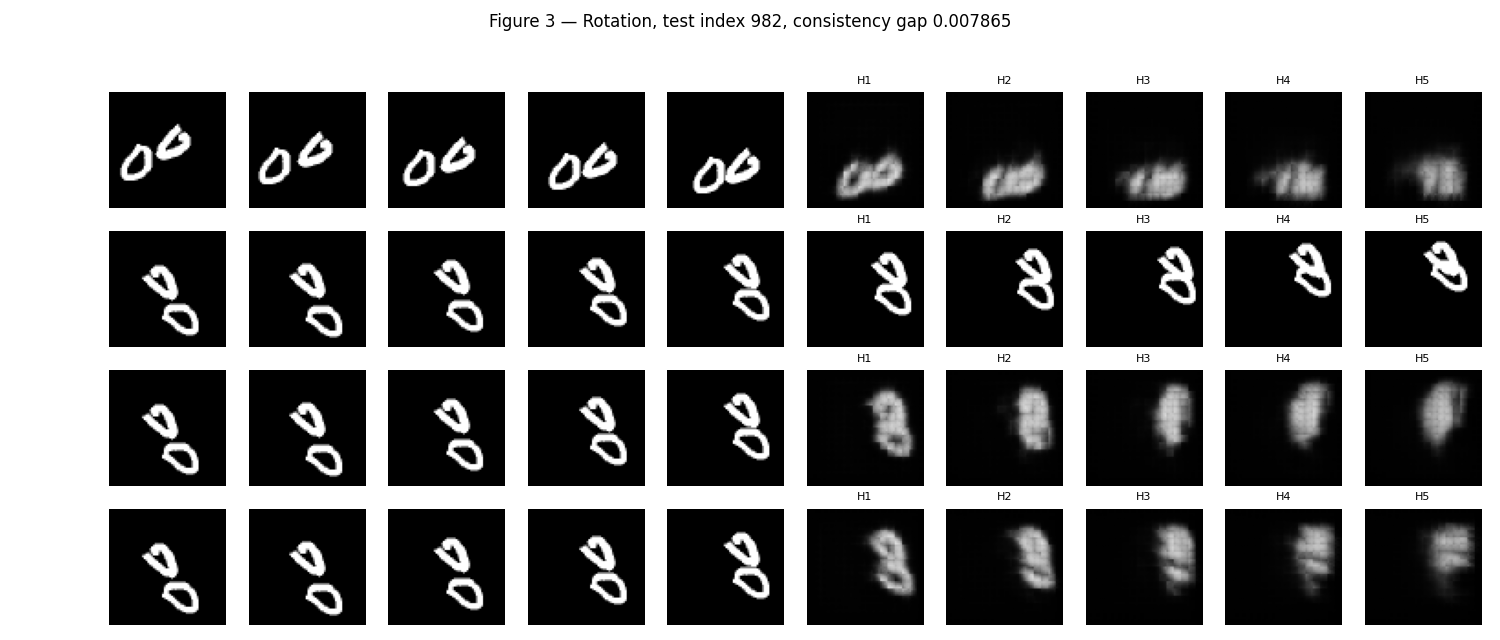


figures/Figure3/rotation_test_269.png


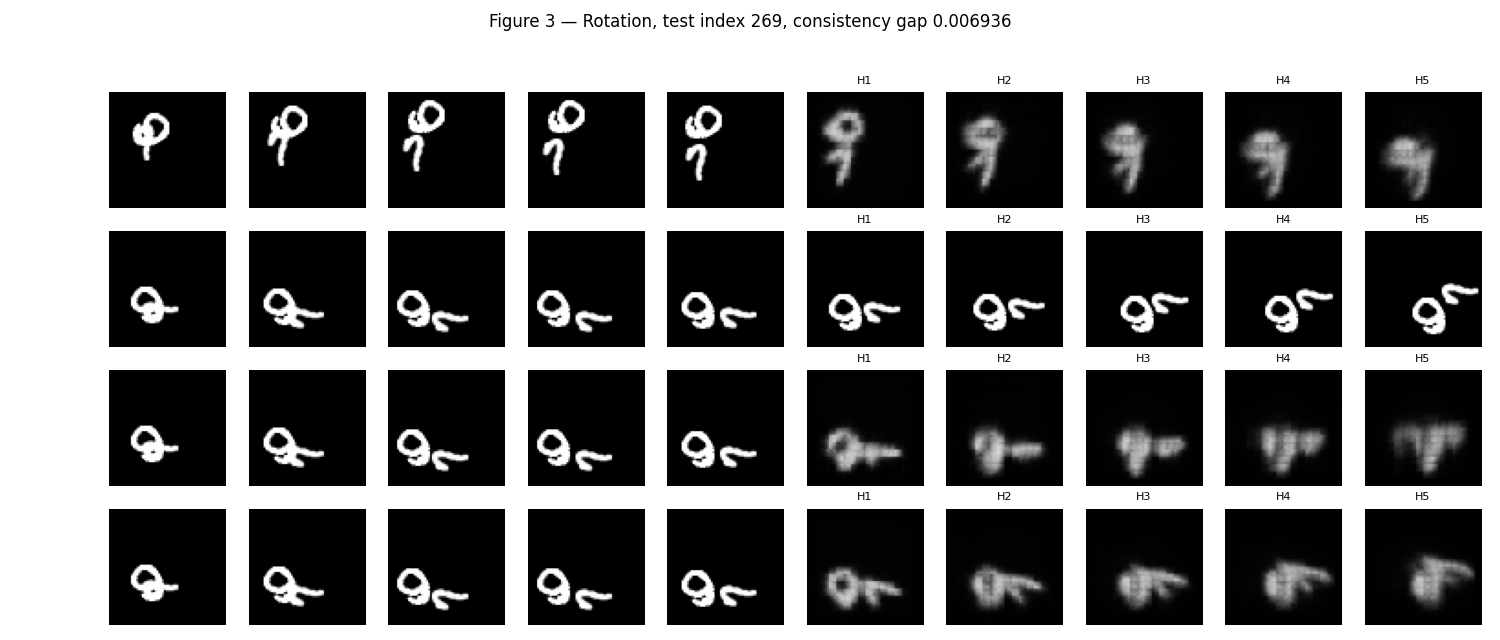


figures/Figure4/Figure4a_mirror_histogram.png


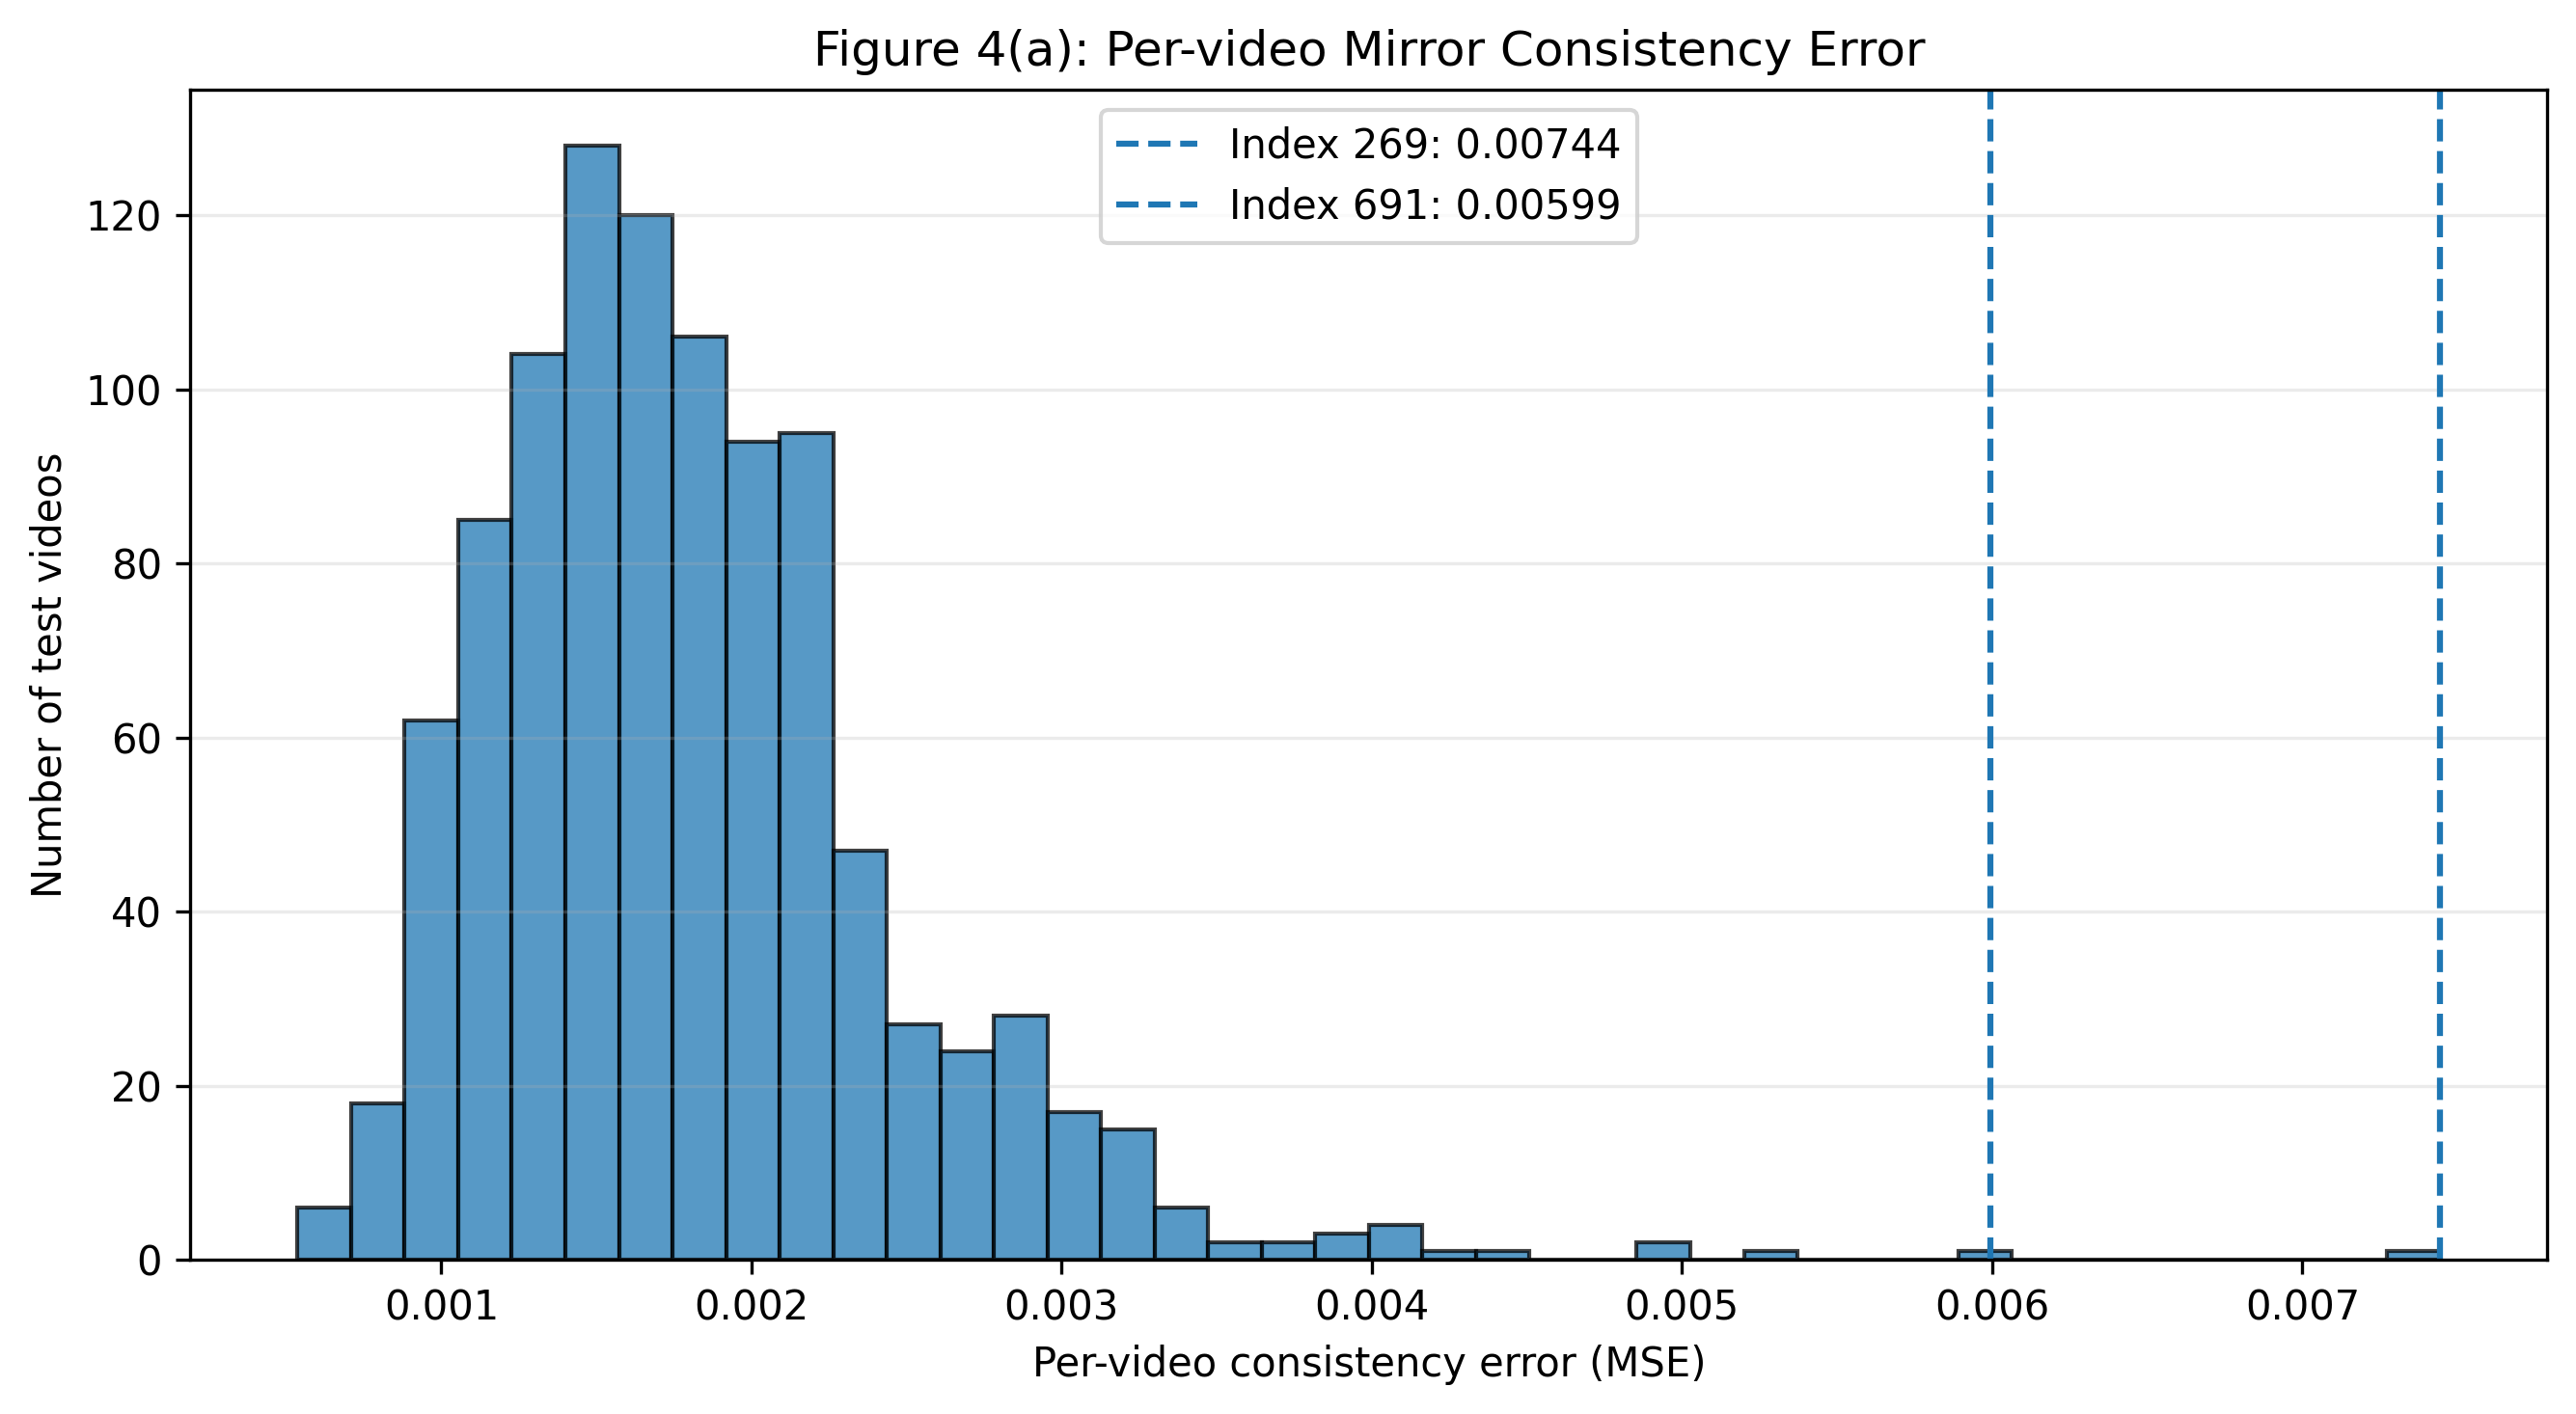


figures/Figure4/Figure4b_rotation_histogram.png


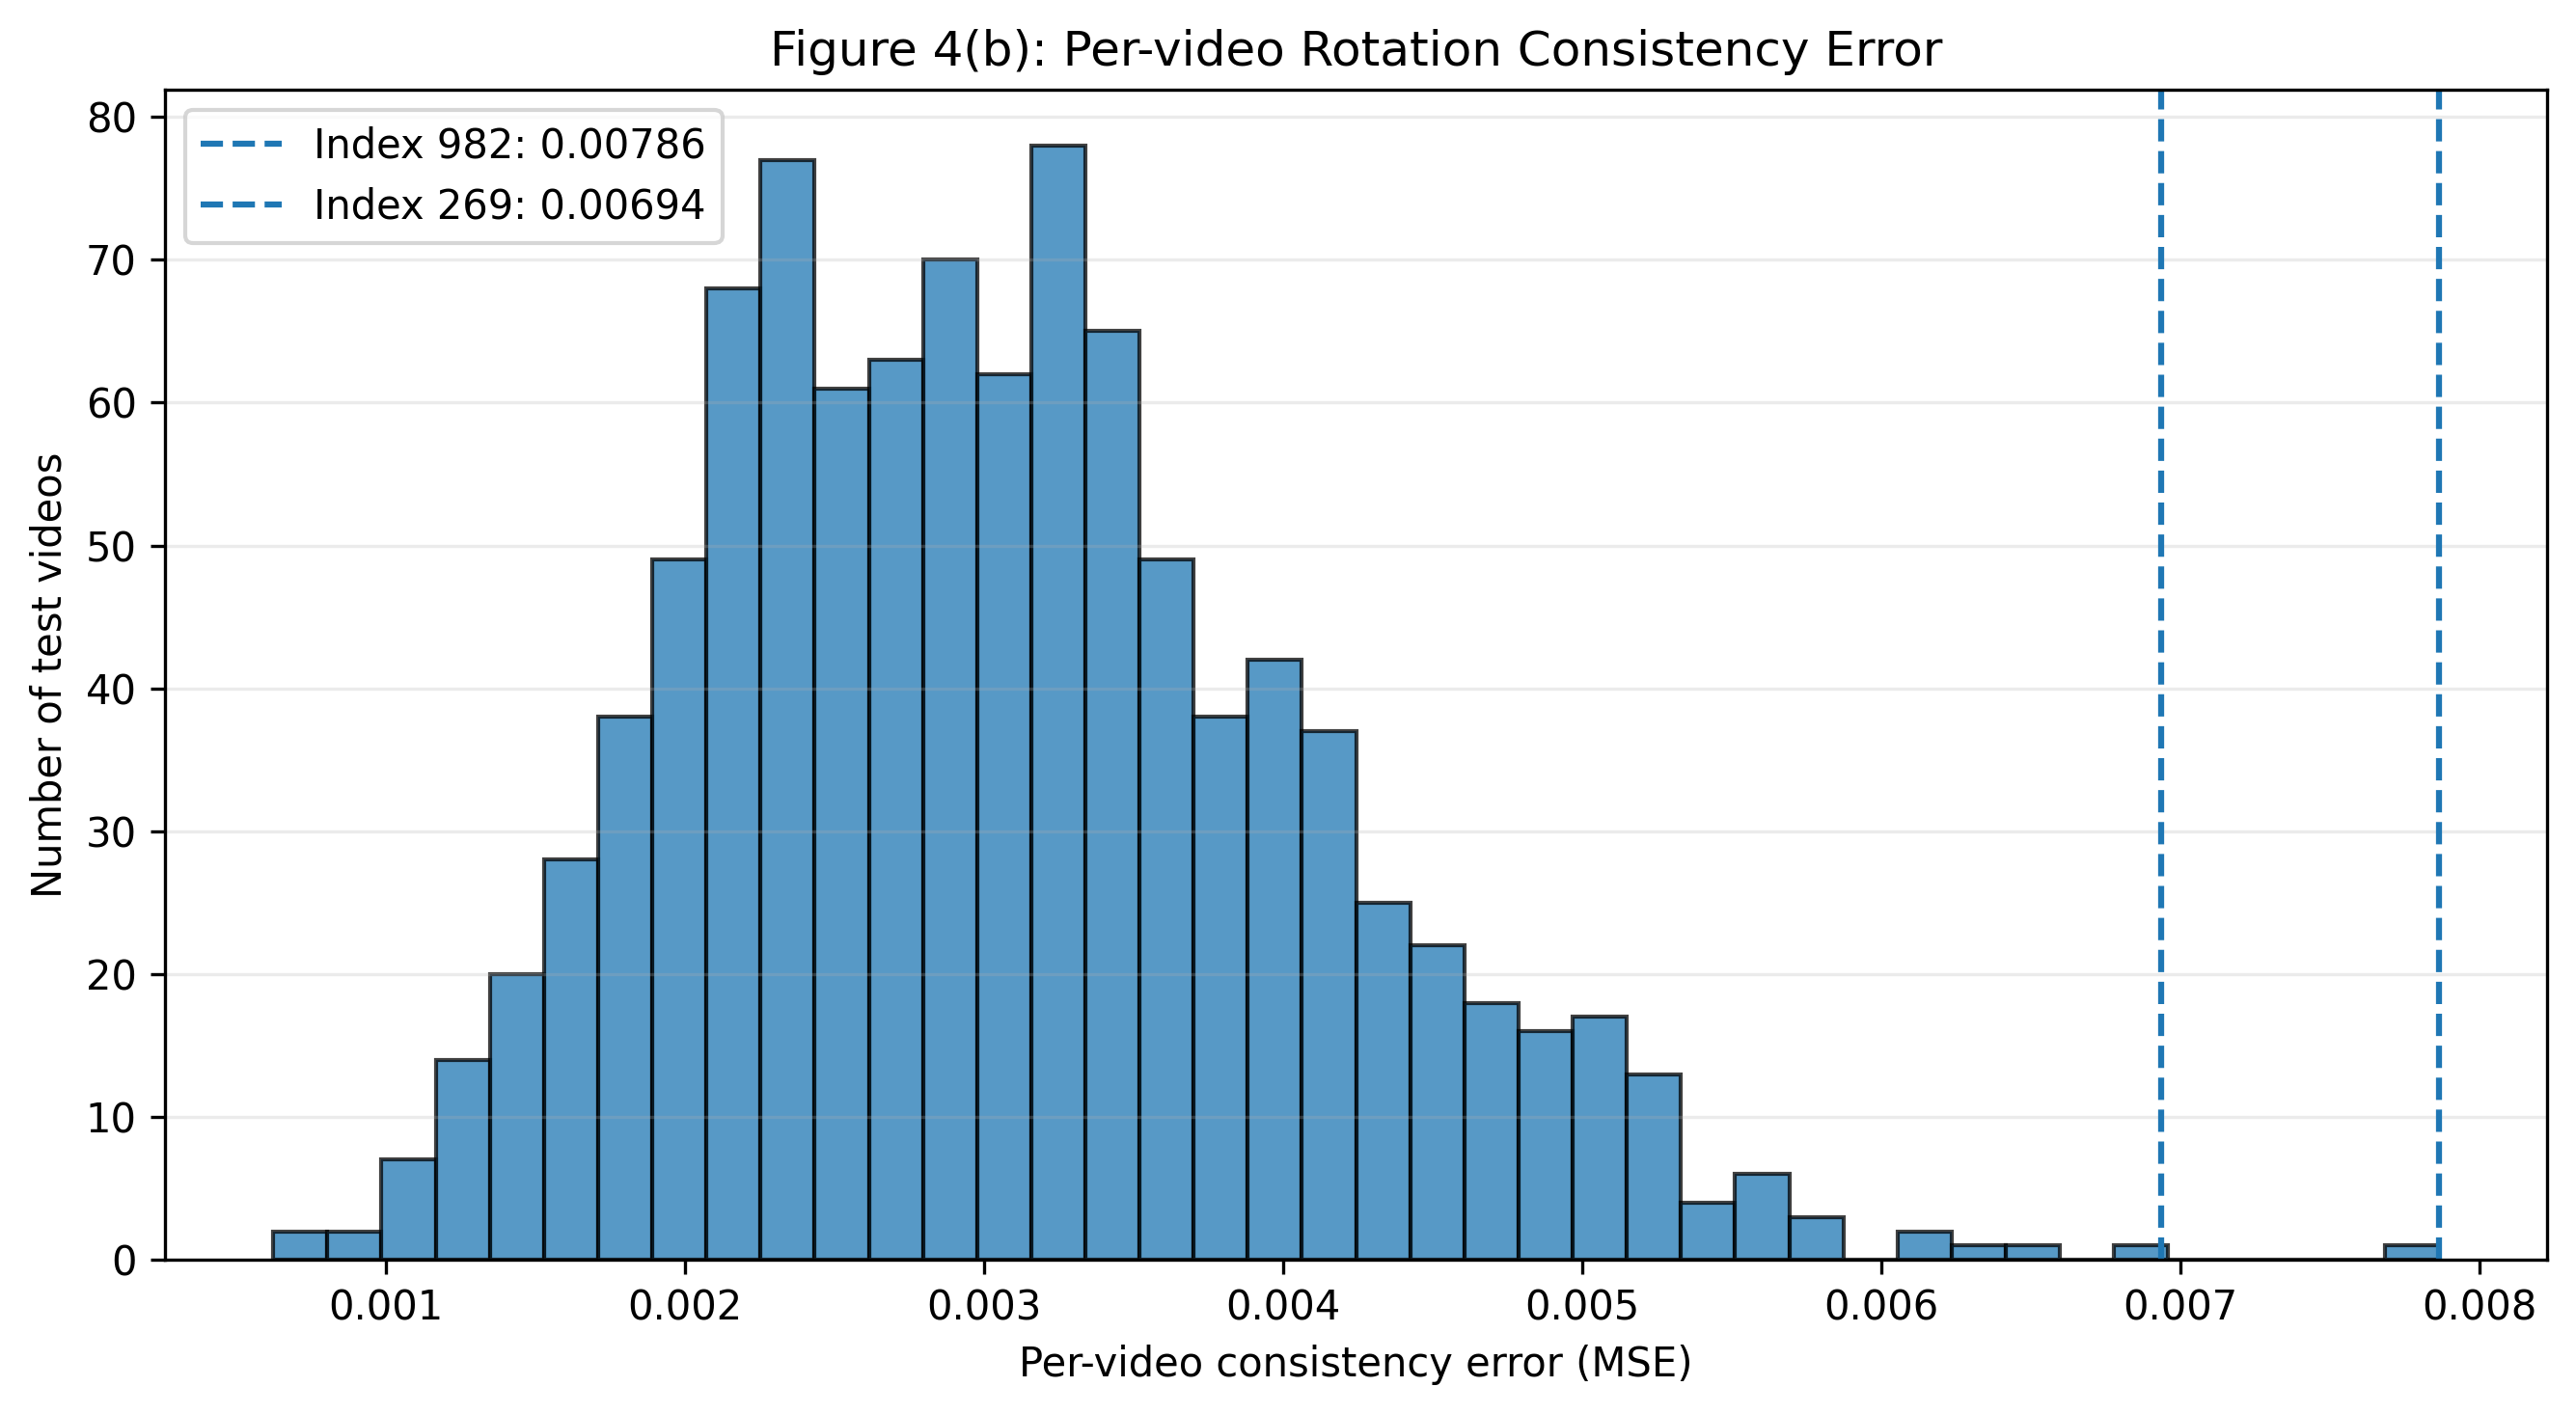

In [186]:
from IPython.display import display, Image
from pathlib import Path

figure_files = [
    "figures/Figure3/mirror_test_269.png",
    "figures/Figure3/mirror_test_691.png",
    "figures/Figure3/rotation_test_982.png",
    "figures/Figure3/rotation_test_269.png",
    "figures/Figure4/Figure4a_mirror_histogram.png",
    "figures/Figure4/Figure4b_rotation_histogram.png",
]

for file in figure_files:
    path = Path(file)
    print(f"\n{file}")
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print("File not found")

In [ ]:
print("Model A architecture:")
print(model_a_seed0)

print("\nTotal trainable parameters:")
print(sum(p.numel() for p in model_a_seed0.parameters() if p.requires_grad))

Model A architecture:
ModelA(
  (pixel_unshuffle): PixelUnshuffle(downscale_factor=4)
  (convlstm1): ConvLSTMCell(
    (gates): Conv2d(80, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm2): ConvLSTMCell(
    (gates): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=4)
)

Total trainable parameters:
480784


In [196]:
import numpy as np

# ============================================
# TABLE 5 — MOTION OR MEMORY?
# ============================================

# 1. Parameter counts
parameter_counts = {
    "A": 480784,
    "B": 480784,
    "C": 480784,
    "D": params_d
}

# 2. Mean training time per epoch (seconds)
training_times = {
    "A": (12.7081 + 12.4759) / 2,
    "B": (epoch_time_b_seed0 + epoch_time_b_seed1) / 2,
    "C": (epoch_time_c_seed0 + epoch_time_c_seed1) / 2,
    "D": (epoch_time_d_seed0 + epoch_time_d_seed1) / 2
}

# 3. Mean inference time per video (seconds)
inference_times = {
    "A": (
        model_a_final_results[0]["inference_seconds"]
        + model_a_final_results[1]["inference_seconds"]
    ) / 2 / 1000,
    "B": None,  # Not recorded in the available results
    "C": (
        inference_results["C_seed0"]["seconds_per_video"]
        + inference_results["C_seed1"]["seconds_per_video"]
    ) / 2,
    "D": (
        inference_results["D_seed0"]["seconds_per_video"]
        + inference_results["D_seed1"]["seconds_per_video"]
    ) / 2
}

# Helper: average a metric across seeds for a given speed.
def mean_speed_metric(results, speed, metric):
    values = [results[speed][seed][metric] for seed in (0, 1)]
    values = [v for v in values if np.isfinite(v)]
    return float(np.mean(values)) if values else None

def mean_c_d_metric(results, speed, metric):
    values = [results[seed][speed][metric] for seed in (0, 1)]
    values = [v for v in values if np.isfinite(v)]
    return float(np.mean(values)) if values else None

# 4. E5 and E2 speed metrics
speed_table = {
    "A": {
        "E5_1x": mean_speed_metric(speed_results_a, 1, "e5"),
        "E2_1x": mean_speed_metric(speed_results_a, 1, "e2"),
        "E2_2x": mean_speed_metric(speed_results_a, 2, "e2"),
        "E2_3x": mean_speed_metric(speed_results_a, 3, "e2")
    },

    "B": {
        "E5_1x": np.mean([
            model_b_final_results[0]["e5"],
            model_b_final_results[1]["e5"]
        ]),
        "E2_1x": None,
        "E2_2x": None,
        "E2_3x": None
    },

    "C": {
        "E5_1x": mean_c_d_metric(speed_results_c, 1, "e5"),
        "E2_1x": mean_c_d_metric(speed_results_c, 1, "e2"),
        "E2_2x": mean_c_d_metric(speed_results_c, 2, "e2"),
        "E2_3x": mean_c_d_metric(speed_results_c, 3, "e2")
    },

    "D": {
        "E5_1x": mean_c_d_metric(speed_results_d, 1, "e5"),
        "E2_1x": mean_c_d_metric(speed_results_d, 1, "e2"),
        "E2_2x": mean_c_d_metric(speed_results_d, 2, "e2"),
        "E2_3x": mean_c_d_metric(speed_results_d, 3, "e2")
    }
}

# 5. Transformation metrics (means over seeds)
transform_table = {
    "A": {
        "CM": (0.0018154628342017531 + 0.0017605532193556428) / 2,
        "EM": (0.02314576506614685 + 0.02257055602967739) / 2,
        "CR": (0.0030672696884721518 + 0.002928656293079257) / 2,
        "ER": (0.02419046312570572 + 0.023563988506793976) / 2
    },
    "B": {
        "CM": (0.0011479558888822794 + 0.0011485518189147115) / 2,
        "EM": (0.022171534597873688 + 0.022182324901223183) / 2,
        "CR": (0.0014297249726951122 + 0.0016762923914939165) / 2,
        "ER": (0.022175105288624763 + 0.022218968719244003) / 2
    },
    "C": {
        "CM": (0.0007597571 + 0.0013723300) / 2,
        "EM": (0.0275380034 + 0.0270771980) / 2,
        "CR": (0.0017838730 + 0.0029493272) / 2,
        "ER": (0.0283300411 + 0.0280873720) / 2
    },
    "D": {
        "CM": (1.44847e-7 + 0.0016129002) / 2,
        "EM": (0.0401366651 + 0.0255128536) / 2,
        "CR": (1.75773e-7 + 0.0027462489) / 2,
        "ER": (0.0401366577 + 0.0266355965) / 2
    }
}

# 6. Print Table 5
def fmt(value):
    if value is None:
        return "N/A"
    if not np.isfinite(value):
        return "N/A"
    return f"{value:.3g}"

print("TABLE 5 — MOTION OR MEMORY?")
print("-" * 145)
print(
    f"{'Model':<7}"
    f"{'E5 1x':>10}{'CM':>10}{'EM':>10}{'CR':>10}{'ER':>10}"
    f"{'E2 1x':>10}{'E2 2x':>10}{'E2 3x':>10}"
    f"{'Parameters':>14}{'Train s/epoch':>16}{'Infer s/video':>17}"
)
print("-" * 145)

for model in ("A", "B", "C", "D"):
    s = speed_table[model]
    t = transform_table[model]

    print(
        f"{model:<7}"
        f"{fmt(s['E5_1x']):>10}"
        f"{fmt(t['CM']):>10}"
        f"{fmt(t['EM']):>10}"
        f"{fmt(t['CR']):>10}"
        f"{fmt(t['ER']):>10}"
        f"{fmt(s['E2_1x']):>10}"
        f"{fmt(s['E2_2x']):>10}"
        f"{fmt(s['E2_3x']):>10}"
        f"{parameter_counts[model]:>14,}"
        f"{training_times[model]:>16.3f}"
        f"{fmt(inference_times[model]):>17}"
    )

print("-" * 145)
print("N/A means a value is not available in the saved results.")
print("Note: Model B speed evaluations and inference timing are still missing.")

TABLE 5 — MOTION OR MEMORY?
-------------------------------------------------------------------------------------------------------------------------------------------------
Model       E5 1x        CM        EM        CR        ER     E2 1x     E2 2x     E2 3x    Parameters   Train s/epoch    Infer s/video
-------------------------------------------------------------------------------------------------------------------------------------------------
A           0.022   0.00179    0.0229     0.003    0.0239    0.0184    0.0446    0.0529       480,784          12.592          0.00122
B          0.0222   0.00115    0.0222   0.00155    0.0222       N/A       N/A       N/A       480,784          13.363              N/A
C          0.0269   0.00107    0.0273   0.00237    0.0282    0.0234    0.0291    0.0334       480,784          12.832         0.000517
D          0.0326  0.000807    0.0328   0.00137    0.0334     0.031    0.0336    0.0357       598,320          17.017         0.000515
-----

In [205]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "model_d_seed_0/best_model.pt",
    map_location=device,
    weights_only=False
)

state = checkpoint["model_state_dict"]

for name, parameter in state.items():
    if "output_conv" in name:
        print(
            f"{name}: "
            f"mean={parameter.float().mean().item():.6f}, "
            f"std={parameter.float().std().item():.6f}, "
            f"min={parameter.float().min().item():.6f}, "
            f"max={parameter.float().max().item():.6f}"
        )

output_conv.weight: mean=0.001377, std=0.092273, min=-0.178709, max=0.180332
output_conv.bias: mean=-0.030015, std=0.064276, min=-0.124962, max=0.061062


In [206]:
for name, parameter in state.items():
    if any(layer in name for layer in ["convlstm1", "convlstm2", "convlstm3"]):
        if "weight" in name or "bias" in name:
            p = parameter.float()
            print(
                f"{name}: "
                f"mean={p.mean().item():.6f}, "
                f"std={p.std().item():.6f}, "
                f"min={p.min().item():.6f}, "
                f"max={p.max().item():.6f}"
            )

convlstm1.gates.weight: mean=0.002628, std=0.027266, min=-0.067018, max=0.073914
convlstm1.gates.bias: mean=0.018954, std=0.036751, min=-0.070195, max=0.158282
convlstm2.gates.weight: mean=-0.000956, std=0.026029, min=-0.123944, max=0.117042
convlstm2.gates.bias: mean=0.019400, std=0.035146, min=-0.056659, max=0.141555
convlstm3.gates.weight: mean=-0.001583, std=0.027038, min=-0.103448, max=0.111110
convlstm3.gates.bias: mean=0.016227, std=0.024416, min=-0.051198, max=0.059276


In [233]:
print(model_d_seed0)

ModelD(
  (pixel_unshuffle): PixelUnshuffle(downscale_factor=4)
  (convlstm1): ConvLSTMCell(
    (gates): Conv2d(72, 224, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm2): ConvLSTMCell(
    (gates): Conv2d(112, 224, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (convlstm3): ConvLSTMCell(
    (gates): Conv2d(112, 224, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(56, 16, kernel_size=(1, 1), stride=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=4)
)


In [235]:
from pathlib import Path

for path in [
    Path("model_d_seed_0/best_model.pt"),
    Path("model_d_seed_0/latest_checkpoint.pt"),
    Path("model_d_seed_1/best_model.pt"),
    Path("model_d_seed_1/latest_checkpoint.pt"),
]:
    print(f"{path}: {'EXISTS' if path.exists() else 'MISSING'}")

model_d_seed_0\best_model.pt: EXISTS
model_d_seed_0\latest_checkpoint.pt: EXISTS
model_d_seed_1\best_model.pt: EXISTS
model_d_seed_1\latest_checkpoint.pt: EXISTS


In [236]:
import shutil
from pathlib import Path

source = Path("model_d_seed_0")
backup = Path("model_d_seed_0_backup")

backup.mkdir(parents=True, exist_ok=True)

for filename in ["best_model.pt", "latest_checkpoint.pt"]:
    shutil.copy2(source / filename, backup / filename)
    print(f"Backed up: {filename}")

print("\nBackup folder:", backup.resolve())

Backed up: best_model.pt
Backed up: latest_checkpoint.pt

Backup folder: C:\Users\Fav nand\Downloads\DL4STG_PA2\DL4STG_PA2 2\Question 2\model_d_seed_0_backup


In [238]:
from pathlib import Path
import inspect

print(inspect.signature(train_model_d))

print(
    "Original Seed 0 checkpoint exists:",
    Path("model_d_seed_0/best_model.pt").exists()
)

print(
    "Backup checkpoint exists:",
    Path("model_d_seed_0_backup/best_model.pt").exists()
)

(seed, epochs=30, batch_size=32, learning_rate=0.001, output_dir=None)
Original Seed 0 checkpoint exists: True
Backup checkpoint exists: True


In [239]:

# Reproduce the Seed 0 initialization and capture its initial output weights.
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

initial_model_d0 = ModelD().to(
    torch.device("cuda" if torch.cuda.is_available() else "cpu")
)

initial_output_weight_d0 = (
    initial_model_d0.output_conv.weight.detach().cpu().clone()
)
initial_output_bias_d0 = (
    initial_model_d0.output_conv.bias.detach().cpu().clone()
)

print(
    "Initial output-weight std:",
    initial_output_weight_d0.std().item()
)
print(
    "Initial output-bias mean:",
    initial_output_bias_d0.mean().item()
)

# Train in a NEW directory; original checkpoints remain untouched.
model_d_seed0_exp, history_d_seed0_exp, epoch_time_d_seed0_exp = (
    train_model_d(
        seed=0,
        epochs=30,
        batch_size=32,
        learning_rate=1e-3,
        output_dir="model_d_seed_0_experiment"
    )
)

# Compare initial and final output-convolution parameters.
final_output_weight_d0 = (
    model_d_seed0_exp.output_conv.weight.detach().cpu()
)
final_output_bias_d0 = (
    model_d_seed0_exp.output_conv.bias.detach().cpu()
)

print("\nOutput-convolution comparison")
print(
    "Initial weight std:",
    initial_output_weight_d0.std().item()
)
print(
    "Final weight std:",
    final_output_weight_d0.std().item()
)
print(
    "Maximum absolute weight change:",
    (final_output_weight_d0 - initial_output_weight_d0).abs().max().item()
)
print(
    "Initial bias mean:",
    initial_output_bias_d0.mean().item()
)
print(
    "Final bias mean:",
    final_output_bias_d0.mean().item()
)
print(
    "Maximum absolute bias change:",
    (final_output_bias_d0 - initial_output_bias_d0).abs().max().item()
)


Initial output-weight std: 0.07762355357408524
Initial output-bias mean: -0.0017377426847815514
Model D | Seed 0 | Epoch 01/30 | Train MSE: 0.047826 | Val MSE: 0.039472 | Time: 0.39 min
Model D | Seed 0 | Epoch 02/30 | Train MSE: 0.040180 | Val MSE: 0.039469 | Time: 0.29 min
Model D | Seed 0 | Epoch 03/30 | Train MSE: 0.040203 | Val MSE: 0.039469 | Time: 0.28 min
Model D | Seed 0 | Epoch 04/30 | Train MSE: 0.040202 | Val MSE: 0.039469 | Time: 0.28 min
Model D | Seed 0 | Epoch 05/30 | Train MSE: 0.040184 | Val MSE: 0.039470 | Time: 0.28 min
Model D | Seed 0 | Epoch 06/30 | Train MSE: 0.040201 | Val MSE: 0.039469 | Time: 0.28 min
Model D | Seed 0 | Epoch 07/30 | Train MSE: 0.040182 | Val MSE: 0.039469 | Time: 0.28 min
Model D | Seed 0 | Epoch 08/30 | Train MSE: 0.040188 | Val MSE: 0.039468 | Time: 0.28 min
Model D | Seed 0 | Epoch 09/30 | Train MSE: 0.040189 | Val MSE: 0.039468 | Time: 0.28 min
Model D | Seed 0 | Epoch 10/30 | Train MSE: 0.040196 | Val MSE: 0.039469 | Time: 0.28 min
Mode

In [240]:

# Use a fresh Seed 0 model so we can inspect gradients at initialization.
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gradient_model = ModelD().to(device)
gradient_optimizer = torch.optim.Adam(
    gradient_model.parameters(),
    lr=1e-3
)

# Use one batch and reproduce the same window-building procedure.
loader = DataLoader(
    TensorDataset(train_videos),
    batch_size=32,
    shuffle=True,
    num_workers=0,
    drop_last=False
)

videos_batch, = next(iter(loader))
videos_batch = videos_batch.to(device)

speeds = torch.randint(
    low=1, high=4, size=(videos_batch.size(0),), device="cpu"
).tolist()

inputs, targets, target_lengths = [], [], []

for i, speed in enumerate(speeds):
    start = random.choice(allowed_starts_cd_train[speed])
    X, Y = make_window(videos_batch[i], t=start, speed=speed)

    inputs.append(X)
    target_lengths.append(Y.size(0))

    if Y.size(0) < 5:
        padding = torch.zeros(
            (5 - Y.size(0), *Y.shape[1:]),
            dtype=Y.dtype,
            device=Y.device
        )
        Y = torch.cat([Y, padding], dim=0)

    targets.append(Y)

X_batch = torch.stack(inputs).to(device)
Y_batch = torch.stack(targets).to(device)

gradient_optimizer.zero_grad(set_to_none=True)
predictions = model_d_rollout(gradient_model, X_batch)
losses = per_video_mse_masked(predictions, Y_batch, target_lengths)
loss = losses.mean()
loss.backward()

print(f"Initial batch loss: {loss.item():.6f}")

for name, parameter in gradient_model.named_parameters():
    if parameter.grad is not None:
        print(
            f"{name:30s} "
            f"grad_norm={parameter.grad.norm().item():.6e}"
        )


Initial batch loss: 0.242911
convlstm1.gates.weight         grad_norm=7.791385e-04
convlstm1.gates.bias           grad_norm=4.237468e-04
convlstm2.gates.weight         grad_norm=1.291206e-03
convlstm2.gates.bias           grad_norm=2.534582e-03
convlstm3.gates.weight         grad_norm=3.856838e-03
convlstm3.gates.bias           grad_norm=1.425730e-02
output_conv.weight             grad_norm=4.085602e-03
output_conv.bias               grad_norm=5.615121e-02


In [241]:

from pathlib import Path
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for epoch_name, checkpoint_file in [
    ("Seed 0 best checkpoint", Path("model_d_seed_0_backup/best_model.pt")),
    ("Seed 0 experiment latest", Path("model_d_seed_0_experiment/latest_checkpoint.pt")),
]:
    if not checkpoint_file.exists():
        print(f"\nMissing: {checkpoint_file}")
        continue

    checkpoint_data = torch.load(
        checkpoint_file,
        map_location="cpu",
        weights_only=False
    )
    state = checkpoint_data["model_state_dict"]

    print(f"\n{epoch_name}")
    print("Saved epoch:", checkpoint_data["epoch"])
    print("Output bias mean:", state["output_conv.bias"].mean().item())
    print("Output bias std:", state["output_conv.bias"].std().item())
    print("Output weight std:", state["output_conv.weight"].std().item())



Seed 0 best checkpoint
Saved epoch: 23
Output bias mean: -0.030015356838703156
Output bias std: 0.06427600234746933
Output weight std: 0.09227254986763

Seed 0 experiment latest
Saved epoch: 30
Output bias mean: -0.030710017308592796
Output bias std: 0.06426406651735306
Output weight std: 0.09259579330682755


In [242]:

from pathlib import Path
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = Path("model_d_seed_1/best_model.pt")

assert checkpoint_path.exists(), f"Checkpoint not found: {checkpoint_path}"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model_d_final = ModelD().to(device)
model_d_final.load_state_dict(checkpoint["model_state_dict"])
model_d_final.eval()

print("Model D loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation MSE:", min(
    record["val_loss"] for record in checkpoint["history"]
))
print("Parameter count:", sum(
    parameter.numel() for parameter in model_d_final.parameters()
))


Model D loaded successfully.
Checkpoint epoch: 30
Best validation MSE: 0.024902842506766318
Parameter count: 598320


In [243]:
import numpy as np
import time

# Evaluate Model B at all three motion speeds.
allowed_starts = {
    1: list(range(1, 12)),
    2: list(range(1, 9)),
    3: [1, 2]
}

speed_results_b = {}

for seed, model in [
    (0, model_b_seed0),
    (1, model_b_seed1)
]:
    speed_results_b[seed] = {}

    model.eval()

    for speed in (1, 2, 3):
        print(f"Evaluating Model B, seed {seed}, speed {speed}x...")

        result = evaluate_speed_for_seed(
            model=model,
            speed=speed,
            starts=allowed_starts[speed],
            videos=test_videos,
            batch_size=32
        )

        speed_results_b[seed][speed] = result

print("\nModel B speed evaluation completed.")

Evaluating Model B, seed 0, speed 1x...
Evaluating Model B, seed 0, speed 2x...
Evaluating Model B, seed 0, speed 3x...
Evaluating Model B, seed 1, speed 1x...
Evaluating Model B, seed 1, speed 2x...
Evaluating Model B, seed 1, speed 3x...

Model B speed evaluation completed.


In [244]:
# Inspect one result so we can confirm the metric names.
print("Example result:", speed_results_b[0][1])

def mean_b_metric(speed, metric):
    values = [
        speed_results_b[seed][speed][metric]
        for seed in (0, 1)
    ]
    values = [v for v in values if np.isfinite(v)]
    return float(np.mean(values)) if values else None

print("\nMODEL B — AVERAGED SPEED METRICS")
for speed in (1, 2, 3):
    print(
        f"{speed}x: E2 = "
        f"{mean_b_metric(speed, 'e2')}"
    )

Example result: {'e2': 0.018030153587460518, 'e5': 0.021938694640994072, 'horizon_mse': array([0.01602536, 0.02003494, 0.0226361 , 0.02459409, 0.02640298]), 'horizon_counts': array([45056000., 45056000., 45056000., 45056000., 45056000.]), 'num_starts': 11}

MODEL B — AVERAGED SPEED METRICS
1x: E2 = 0.018190848641097546
2x: E2 = 0.04487626254558563
3x: E2 = 0.050873979926109314


In [245]:
speed_table["B"]["E2_1x"] = 0.018190848641097546
speed_table["B"]["E2_2x"] = 0.04487626254558563
speed_table["B"]["E2_3x"] = 0.050873979926109314

import inspect

print(inspect.signature(measure_inference_time))
print(inspect.getsource(measure_inference_time))

(model, rollout_function, inputs, batch_size=32)
def measure_inference_time(model, rollout_function, inputs, batch_size=32):
    device = next(model.parameters()).device
    model.eval()

    elapsed_seconds = 0.0
    number_of_videos = 0

    with torch.no_grad():
        for start in range(0, len(inputs), batch_size):
            # Move the batch to the model's device before timing.
            batch = inputs[start:start + batch_size].to(device)

            if device.type == "cuda":
                torch.cuda.synchronize(device)

            batch_start = time.perf_counter()

            predictions = rollout_function(model, batch)

            if device.type == "cuda":
                torch.cuda.synchronize(device)

            elapsed_seconds += time.perf_counter() - batch_start
            number_of_videos += batch.shape[0]

            # Ensure predictions were actually generated.
            assert predictions.shape == (
                batch.shape[0], 5, 1, 64, 64
            

In [250]:
def make_sym_b_rollout(model):
    def rollout_fn(_model, inputs):
        return symmetrized_rollout_generic(
            model, inputs, model_a_rollout, batch_size=32
        )
    return rollout_fn

inference_results["B_seed0"] = measure_inference_time(
    model=model_b_seed0,
    rollout_function=make_sym_b_rollout(model_b_seed0),
    inputs=test_inputs,
    batch_size=32
)

inference_results["B_seed1"] = measure_inference_time(
    model=model_b_seed1,
    rollout_function=make_sym_b_rollout(model_b_seed1),
    inputs=test_inputs,
    batch_size=32
)

b_inference_time = np.mean([
    inference_results["B_seed0"]["seconds_per_video"],
    inference_results["B_seed1"]["seconds_per_video"]
])

inference_times["B"] = b_inference_time

print("Model B seed 0:", inference_results["B_seed0"])
print("Model B seed 1:", inference_results["B_seed1"])
print(f"Model B average inference time: {b_inference_time:.6f} seconds/video")

Model B seed 0: {'total_seconds': 3.923678999984986, 'videos': 1000, 'seconds_per_video': 0.003923678999984986}
Model B seed 1: {'total_seconds': 3.663081399994553, 'videos': 1000, 'seconds_per_video': 0.003663081399994553}
Model B average inference time: 0.003793 seconds/video


In [251]:
import numpy as np

# Parameter counts
parameter_counts = {
    "A": 480784,
    "B": 480784,
    "C": 480784,
    "D": params_d
}

# Average training time per epoch across seeds
training_times = {
    "A": (12.7081 + 12.4759) / 2,
    "B": (epoch_time_b_seed0 + epoch_time_b_seed1) / 2,
    "C": (epoch_time_c_seed0 + epoch_time_c_seed1) / 2,
    "D": (epoch_time_d_seed0 + epoch_time_d_seed1) / 2
}

# Average inference time per video across seeds
inference_times = {
    "A": (
        model_a_final_results[0]["inference_seconds"]
        + model_a_final_results[1]["inference_seconds"]
    ) / 2 / 1000,

    "B": (
        inference_results["B_seed0"]["seconds_per_video"]
        + inference_results["B_seed1"]["seconds_per_video"]
    ) / 2,

    "C": (
        inference_results["C_seed0"]["seconds_per_video"]
        + inference_results["C_seed1"]["seconds_per_video"]
    ) / 2,

    "D": (
        inference_results["D_seed0"]["seconds_per_video"]
        + inference_results["D_seed1"]["seconds_per_video"]
    ) / 2
}


# Average speed metrics across the two seeds
def mean_speed_metric(results, speed, metric):
    values = [
        results[speed][seed][metric]
        for seed in (0, 1)
    ]
    values = [v for v in values if np.isfinite(v)]
    return float(np.mean(values)) if values else None


def mean_c_d_metric(results, speed, metric):
    values = [
        results[seed][speed][metric]
        for seed in (0, 1)
    ]
    values = [v for v in values if np.isfinite(v)]
    return float(np.mean(values)) if values else None


# Speed evaluation results
speed_table = {
    "A": {
        "E5_1x": mean_speed_metric(speed_results_a, 1, "e5"),
        "E2_1x": mean_speed_metric(speed_results_a, 1, "e2"),
        "E2_2x": mean_speed_metric(speed_results_a, 2, "e2"),
        "E2_3x": mean_speed_metric(speed_results_a, 3, "e2")
    },

    "B": {
        "E5_1x": np.mean([
            model_b_final_results[0]["e5"],
            model_b_final_results[1]["e5"]
        ]),
        "E2_1x": np.mean([
            speed_results_b[0][1]["e2"],
            speed_results_b[1][1]["e2"]
        ]),
        "E2_2x": np.mean([
            speed_results_b[0][2]["e2"],
            speed_results_b[1][2]["e2"]
        ]),
        "E2_3x": np.mean([
            speed_results_b[0][3]["e2"],
            speed_results_b[1][3]["e2"]
        ])
    },

    "C": {
        "E5_1x": mean_c_d_metric(speed_results_c, 1, "e5"),
        "E2_1x": mean_c_d_metric(speed_results_c, 1, "e2"),
        "E2_2x": mean_c_d_metric(speed_results_c, 2, "e2"),
        "E2_3x": mean_c_d_metric(speed_results_c, 3, "e2")
    },

    "D": {
        "E5_1x": mean_c_d_metric(speed_results_d, 1, "e5"),
        "E2_1x": mean_c_d_metric(speed_results_d, 1, "e2"),
        "E2_2x": mean_c_d_metric(speed_results_d, 2, "e2"),
        "E2_3x": mean_c_d_metric(speed_results_d, 3, "e2")
    }
}


# Transformation metrics, averaged across seeds
transform_table = {
    "A": {
        "CM": (0.0018154628342017531 + 0.0017605532193556428) / 2,
        "EM": (0.02314576506614685 + 0.02257055602967739) / 2,
        "CR": (0.0030672696884721518 + 0.002928656293079257) / 2,
        "ER": (0.02419046312570572 + 0.023563988506793976) / 2
    },

    "B": {
        "CM": (0.0011479558888822794 + 0.0011485518189147115) / 2,
        "EM": (0.022171534597873688 + 0.022182324901223183) / 2,
        "CR": (0.0014297249726951122 + 0.0016762923914939165) / 2,
        "ER": (0.022175105288624763 + 0.022218968719244003) / 2
    },

    "C": {
        "CM": (0.0007597571 + 0.0013723300) / 2,
        "EM": (0.0275380034 + 0.0270771980) / 2,
        "CR": (0.0017838730 + 0.0029493272) / 2,
        "ER": (0.0283300411 + 0.0280873720) / 2
    },

    "D": {
        "CM": (1.44847e-7 + 0.0016129002) / 2,
        "EM": (0.0401366651 + 0.0255128536) / 2,
        "CR": (1.75773e-7 + 0.0027462489) / 2,
        "ER": (0.0401366577 + 0.0266355965) / 2
    }
}


# Generate Table 5
columns = [
    "Model", "E5 1x", "CM", "EM", "CR", "ER",
    "E2 1x", "E2 2x", "E2 3x",
    "Parameters", "Train s/epoch", "Infer s/video"
]

print("TABLE 5 — MOTION OR MEMORY?\n")
print(
    f"{columns[0]:<8}"
    f"{columns[1]:>10}"
    f"{columns[2]:>10}"
    f"{columns[3]:>10}"
    f"{columns[4]:>10}"
    f"{columns[5]:>10}"
    f"{columns[6]:>10}"
    f"{columns[7]:>10}"
    f"{columns[8]:>10}"
    f"{columns[9]:>13}"
    f"{columns[10]:>16}"
    f"{columns[11]:>16}"
)

for model_name in ("A", "B", "C", "D"):
    row = [
        model_name,
        speed_table[model_name]["E5_1x"],
        transform_table[model_name]["CM"],
        transform_table[model_name]["EM"],
        transform_table[model_name]["CR"],
        transform_table[model_name]["ER"],
        speed_table[model_name]["E2_1x"],
        speed_table[model_name]["E2_2x"],
        speed_table[model_name]["E2_3x"],
        parameter_counts[model_name],
        training_times[model_name],
        inference_times[model_name]
    ]

    formatted = []
    for i, value in enumerate(row):
        if value is None:
            formatted.append("N/A")
        elif i == 0:
            formatted.append(str(value))
        elif i == 9:
            formatted.append(f"{int(value):,}")
        elif i == 10:
            formatted.append(f"{value:.3f}")
        elif i == 11:
            formatted.append(f"{value:.6f}")
        else:
            formatted.append(f"{value:.5f}")

    print(
        f"{formatted[0]:<8}"
        f"{formatted[1]:>10}"
        f"{formatted[2]:>10}"
        f"{formatted[3]:>10}"
        f"{formatted[4]:>10}"
        f"{formatted[5]:>10}"
        f"{formatted[6]:>10}"
        f"{formatted[7]:>10}"
        f"{formatted[8]:>10}"
        f"{formatted[9]:>13}"
        f"{formatted[10]:>16}"
        f"{formatted[11]:>16}"
    )

TABLE 5 — MOTION OR MEMORY?

Model        E5 1x        CM        EM        CR        ER     E2 1x     E2 2x     E2 3x   Parameters   Train s/epoch   Infer s/video
A          0.02201   0.00179   0.02286   0.00300   0.02388   0.01839   0.04459   0.05291      480,784          12.592        0.001224
B          0.02217   0.00115   0.02218   0.00155   0.02220   0.01819   0.04488   0.05087      480,784          13.363        0.003793
C          0.02693   0.00107   0.02731   0.00237   0.02821   0.02344   0.02907   0.03344      480,784          12.832        0.000517
D          0.03256   0.00081   0.03282   0.00137   0.03339   0.03101   0.03364   0.03573      598,320          17.017        0.000515


In [257]:
import numpy as np
import torch
import time

models_to_evaluate = {
    "Symmetrised B — seed 0": (model_b_seed0, model_a_rollout),
    "Symmetrised B — seed 1": (model_b_seed1, model_a_rollout),
    "Symmetrised D — seed 0": (model_d_seed0, model_d_rollout),
    "Symmetrised D — seed 1": (model_d_seed1, model_d_rollout),
}

symmetrized_results = []

for model_name, (trained_model, ordinary_rollout) in models_to_evaluate.items():
    print(f"\nEvaluating {model_name}...")

    metrics = evaluate_symmetrized_model(
        trained_model,
        ordinary_rollout,
        batch_size=32
    )

    def sym_rollout(m, x, rollout=ordinary_rollout):
        return symmetrized_rollout_generic(
            m, x, rollout, batch_size=32
        )

    timing = measure_inference_time(
        trained_model,
        sym_rollout,
        test_inputs,
        batch_size=32
    )

    row = {
        "Model": model_name,
        "E5": metrics["E5"],
        "CM": metrics["CM"],
        "EM": metrics["EM"],
        "CR": metrics["CR"],
        "ER": metrics["ER"],
        "Inference (s/video)": timing["seconds_per_video"],
        "Parameters": sum(
            p.numel() for p in trained_model.parameters()
        ),
    }
    symmetrized_results.append(row)

    print(f"E5: {metrics['E5']:.6f}")
    print(f"CM: {metrics['CM']:.3e}")
    print(f"EM: {metrics['EM']:.6f}")
    print(f"CR: {metrics['CR']:.3e}")
    print(f"ER: {metrics['ER']:.6f}")
    print(f"Inference time: {timing['seconds_per_video']:.6f} s/video")
    print(f"Parameters: {row['Parameters']:,}")

print("\n===== SUMMARY =====")
for row in symmetrized_results:
    print("\n", row["Model"])
    for key, value in row.items():
        if key == "Model":
            continue
        if isinstance(value, float):
            print(f"  {key}: {value:.6g}")
        else:
            print(f"  {key}: {value}")


Evaluating Symmetrised B — seed 0...
E5: 0.021555
CM: 8.664e-17
EM: 0.021555
CR: 8.551e-17
ER: 0.021555
Inference time: 0.003276 s/video
Parameters: 480,784

Evaluating Symmetrised B — seed 1...
E5: 0.021551
CM: 8.892e-17
EM: 0.021551
CR: 8.808e-17
ER: 0.021551
Inference time: 0.003301 s/video
Parameters: 480,784

Evaluating Symmetrised D — seed 0...
E5: 0.040137
CM: 9.980e-18
EM: 0.040137
CR: 8.317e-18
ER: 0.040137
Inference time: 0.004587 s/video
Parameters: 598,320

Evaluating Symmetrised D — seed 1...
E5: 0.025042
CM: 6.678e-17
EM: 0.025042
CR: 6.695e-17
ER: 0.025042
Inference time: 0.004637 s/video
Parameters: 598,320

===== SUMMARY =====

 Symmetrised B — seed 0
  E5: 0.0215549
  CM: 8.66386e-17
  EM: 0.0215549
  CR: 8.55093e-17
  ER: 0.0215549
  Inference (s/video): 0.00327635
  Parameters: 480784

 Symmetrised B — seed 1
  E5: 0.0215512
  CM: 8.89155e-17
  EM: 0.0215512
  CR: 8.80846e-17
  ER: 0.0215512
  Inference (s/video): 0.00330111
  Parameters: 480784

 Symmetrised D — s

In [259]:
# Evaluate symmetrised models on the same speed-test windows.
# No pandas required; no model training occurs.

def evaluate_symmetrized_speed(model_to_test, rollout_fn, speed_value, starts):
    device = next(model_to_test.parameters()).device
    model_to_test.eval()

    all_X = []
    all_Y = []
    target_lengths = []

    # Match the existing evaluation: every test video and allowed start.
    for video in test_videos:
        for window_start in starts:
            X, Y = make_window(video, t=window_start, speed=speed_value)

            all_X.append(X)
            target_lengths.append(Y.size(0))

            if Y.size(0) < 5:
                padding = torch.zeros(
                    (5 - Y.size(0), *Y.shape[1:]),
                    dtype=Y.dtype,
                    device=Y.device
                )
                Y = torch.cat([Y, padding], dim=0)

            all_Y.append(Y)

    all_X = torch.stack(all_X)
    all_Y = torch.stack(all_Y)

    prediction_batches = []

    with torch.no_grad():
        for begin in range(0, len(all_X), 32):
            batch_X = all_X[begin:begin + 32].to(device)

            batch_predictions = symmetrized_rollout_generic(
                model_to_test,
                batch_X,
                rollout_fn,
                batch_size=32
            )
            prediction_batches.append(batch_predictions.cpu())

    predictions = torch.cat(prediction_batches, dim=0)

    horizon_mse = []
    for horizon in range(5):
        valid_indices = [
            i for i, length in enumerate(target_lengths)
            if length > horizon
        ]

        if not valid_indices:
            horizon_mse.append(float("nan"))
            continue

        idx = torch.tensor(valid_indices, dtype=torch.long)
        error = (predictions[idx, horizon] - all_Y[idx, horizon]) ** 2
        horizon_mse.append(error.mean().item())

    e2 = float(np.mean(horizon_mse[:2]))
    e5 = (
        float(np.mean(horizon_mse))
        if np.isfinite(horizon_mse).all()
        else float("nan")
    )

    return {
        "E2": e2,
        "E5": e5,
        "horizon_mse": horizon_mse,
        "num_windows": len(all_X)
    }


symmetrized_speed_results = {}

models_for_speed = {
    "B_seed0": (model_b_seed0, model_a_rollout),
    "B_seed1": (model_b_seed1, model_a_rollout),
    "D_seed0": (model_d_seed0, model_d_rollout),
    "D_seed1": (model_d_seed1, model_d_rollout),
}

for model_name, (trained_model, rollout_fn) in models_for_speed.items():
    symmetrized_speed_results[model_name] = {}

    for speed_value in [1, 2, 3]:
        print(f"\n{model_name}: evaluating speed {speed_value}x...")

        result = evaluate_symmetrized_speed(
            trained_model,
            rollout_fn,
            speed_value,
            allowed_starts[speed_value]
        )

        symmetrized_speed_results[model_name][speed_value] = result

        print(
            f"Speed {speed_value}x | "
            f"E2={result['E2']:.6f} | "
            f"E5={result['E5']:.6f} | "
            f"windows={result['num_windows']}"
        )

print("\n===== SPEED RESULTS SUMMARY =====")
for model_name, speed_results in symmetrized_speed_results.items():
    print(f"\n{model_name}")
    for speed_value, result in speed_results.items():
        print(
            f"  {speed_value}x: "
            f"E2={result['E2']:.6f}, E5={result['E5']:.6f}"
        )


B_seed0: evaluating speed 1x...
Speed 1x | E2=0.017555 | E5=0.021352 | windows=11000

B_seed0: evaluating speed 2x...
Speed 2x | E2=0.043527 | E5=0.046815 | windows=8000

B_seed0: evaluating speed 3x...
Speed 3x | E2=0.047552 | E5=nan | windows=2000

B_seed1: evaluating speed 1x...
Speed 1x | E2=0.017942 | E5=0.021387 | windows=11000

B_seed1: evaluating speed 2x...
Speed 2x | E2=0.044852 | E5=0.050150 | windows=8000

B_seed1: evaluating speed 3x...
Speed 3x | E2=0.052511 | E5=nan | windows=2000

D_seed0: evaluating speed 1x...
Speed 1x | E2=0.040105 | E5=0.040110 | windows=11000

D_seed0: evaluating speed 2x...
Speed 2x | E2=0.040116 | E5=0.040156 | windows=8000

D_seed0: evaluating speed 3x...
Speed 3x | E2=0.040163 | E5=nan | windows=2000

D_seed1: evaluating speed 1x...
Speed 1x | E2=0.021922 | E5=0.024911 | windows=11000

D_seed1: evaluating speed 2x...
Speed 2x | E2=0.027058 | E5=0.030923 | windows=8000

D_seed1: evaluating speed 3x...
Speed 3x | E2=0.031121 | E5=nan | windows=2